# Tarea académica 1 — diagnóstico y mejora de una red neuronal
Clasificación de préstamos: **Fully Paid = 0**, **Charged Off = 1**.

## Diagnóstico del avance original
Los resultados guardados muestran accuracy de validación **0.852166** con precision, recall y F1 iguales a cero en las redes de 5, 10, 20, 50 y 100 capas. Con ambas clases presentes, estos resultados indican que se predijo únicamente la clase 0. La proporción de esa clase explica el accuracy elevado. Los AUC de esas redes sí variaban (0.519190 a 0.711422): cambiaban las probabilidades, aunque no cruzaran el umbral 0.5. En otros experimentos, el mismo accuracy coexistía con recall distinto: el número total de aciertos puede coincidir con predicciones diferentes.

Otros problemas corregidos:
- MinMaxScaler/RobustScaler utilizaban X antes de su creación y sus salidas no alimentaban los modelos.
- Se imputaban predictores usando toda la base; ahora se ajustan imputación, codificación y escalado solo con train.
- Tres etiquetas ausentes se convertían artificialmente en Fully Paid; ahora se excluyen y se informa el conteo.
- No se guardaban curvas por experimento y el número de épocas seleccionado no se conservaba en el modelo final.
- Early Stopping puede producir el mismo resultado para diferentes máximos de épocas. El experimento de épocas ahora desactiva esta parada para aislar ese factor.

Se mantiene la búsqueda secuencial de un factor por etapa. La red mejorada se selecciona entre profundidades de **5, 10 y 20 capas** por el alcance de la actividad; las redes de 1 y 2 capas no participan en esa selección. Esto no demuestra que una red profunda sea superior. La red básica de una capa se conserva únicamente como referencia de la consigna. Se muestran las métricas reales y se separa la comparación a umbral 0.5 de la comparación con umbral elegido exclusivamente en validación.

## 0. Ejecución
Ejecutar de arriba abajo en Colab o en Jupyter. Colocar `dataset.xlsx` junto al notebook o indicar `DATA_PATH`.
`MODO_RAPIDO=True` ejecuta todos los tipos de experimentos con presupuestos reducidos; cambiarlo a False para la corrida extensa de 500/800/1000 épocas.
Las curvas son evaluaciones completas de train y validación al final de cada época, en modo inferencia, con F1 binario de la clase 1 y umbral fijo 0.5.
Dependencias: tensorflow, scikit-learn, pandas, openpyxl, matplotlib; SHAP se instala en la sección 13. En Colab, si falta alguna, instalarla con `%pip install tensorflow scikit-learn pandas openpyxl matplotlib shap` y reiniciar el entorno.
Cada entrenamiento muestra cuatro paneles: loss, AC, F1 y AUC ROC; cada panel contiene las curvas de Train y Validación; también se registra AP por época. AUC usa probabilidades y no depende del umbral 0.5.


SHAP (sección 13) se instala en su propia celda con `%pip install -q shap`; no requiere banderas ni reiniciar el entorno, pero sí que los modelos de las secciones 3 a 11 estén en memoria, por lo que el notebook debe ejecutarse **en orden**.

Documentación: [SHAP](https://shap.readthedocs.io/en/latest/) y [%pip en IPython](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-pip).


In [1]:
from pathlib import Path
import os, time, copy, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, log_loss, r2_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve, average_precision_score, balanced_accuracy_score)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
MODO_RAPIDO = False
EPOCAS_BUSQUEDA = 20 if MODO_RAPIDO else 100
EPOCAS_COMPARAR = [10, 20, 30] if MODO_RAPIDO else [50, 100, 200]
DATA_PATH = Path('dataset.xlsx')
RESULTADOS = Path('resultados_tarea')
RESULTADOS.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
print('TensorFlow:', tf.__version__, '| corrida:', 'rápida' if MODO_RAPIDO else 'extensa')

TensorFlow: 2.21.0 | corrida: extensa


## 1. Datos y separación sin fuga de información
Partición estratificada: 64% train, 16% validación, 20% test. Test se consulta después de congelar modelos y umbrales. MinMaxScaler es un **escalado al rango [0,1]**, no una estandarización de media cero. Valores de validación/test pueden quedar fuera de ese rango si superan los extremos de train; no se reajusta el escalador.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Mostrar archivos disponibles para localizar dataset.xlsx.
display([p.name for p in Path.cwd().iterdir() if p.is_file()])


[]

In [4]:
# Busca dataset.xlsx en el directorio actual o en /content (Google Colab)
candidatos = [Path('dataset.xlsx'), Path('/content/drive/MyDrive/Deeplearning/Tarea academica 1/dataset.xlsx'), Path('/content/drive/MyDrive/Colab Notebooks/deep-learning/dataset.xlsx')] # <----- here
DATA_PATH = next((p for p in candidatos if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('No se encontró dataset.xlsx. Súbelo al mismo entorno del notebook.')

raw = pd.read_excel(DATA_PATH)
etiquetas = raw['loan_status'].astype('string').str.strip()
validas = etiquetas.isin(['Fully Paid', 'Charged Off'])
print('Filas originales:', len(raw), '| etiquetas ausentes/no reconocidas excluidas:', (~validas).sum())
data = raw.loc[validas].copy()
y = etiquetas.loc[validas].map({'Fully Paid': 0, 'Charged Off': 1}).astype('int32')
mapping = {'10+ years':10, '9 years':9, '8 years':8, '7 years':7, '6 years':6,
           '5 years':5, '4 years':4, '3 years':3, '2 years':2, '1 year':1, '< 1 year':0}
data['emp_length_numeric'] = data['emp_length'].map(mapping)
fecha = pd.to_datetime(data['issue_d'].astype(str).str.strip(), format='%b-%Y', errors='coerce')
faltan = fecha.isna()
fecha.loc[faltan] = pd.to_datetime(data.loc[faltan, 'issue_d'], errors='coerce')
data['issue_year'] = fecha.dt.year
X = data.drop(columns=['loan_status','index','emp_title','emp_length','issue_d','pymnt_plan'])
categoricas = X.select_dtypes(exclude='number').columns.tolist()
numericas = X.select_dtypes(include='number').columns.tolist()
for c in categoricas:
    X[c] = X[c].map(lambda v: str(v).strip() if pd.notna(v) else np.nan).astype(object)
X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=.20, random_state=SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=.20, random_state=SEED, stratify=y_tv)
preprocesador = ColumnTransformer([
    ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                      ('minmax', MinMaxScaler())]), numericas),
    ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categoricas)
])
X_train_s = preprocesador.fit_transform(X_train).astype('float32')
X_val_s = preprocesador.transform(X_val).astype('float32')
X_test_s = preprocesador.transform(X_test).astype('float32')
feature_names = preprocesador.get_feature_names_out()
for a in [X_train_s, X_val_s, X_test_s]:
    assert np.isfinite(a).all()
assert set(X_train.index).isdisjoint(X_val.index) and set(X_tv.index).isdisjoint(X_test.index)
display(pd.DataFrame([{'conjunto':n,'filas':len(t),'proporcion_impago':t.mean(),
                      'accuracy_siempre_0':(t==0).mean()}
                     for n,t in [('Train',y_train),('Validación',y_val),('Test',y_test)]]))
pesos = compute_class_weight(class_weight='balanced', classes=np.array([0,1]), y=y_train)
PESOS_CLASE = dict(enumerate(pesos))
print('Pesos calculados solo con train:', PESOS_CLASE)

Filas originales: 19908 | etiquetas ausentes/no reconocidas excluidas: 3


,conjunto,filas,proporcion_impago,accuracy_siempre_0
0,Train,12739,0.147814,0.852186
1,Validación,3185,0.147881,0.852119
2,Test,3981,0.147953,0.852047


Pesos calculados solo con train: {0: np.float64(0.5867262343404569), 1: np.float64(3.3826340945300055)}


## 2. Métricas, entrenamiento y curvas
`loss` en tablas y curvas es log-loss binaria sin ponderación ni penalizaciones, comparable entre todos los modelos. El objetivo optimizado por la red puede incluir pesos de clase y L1/L2; también se conserva como `objetivo_train`.
`ac` se expresa en %, `f1` en [0,1], `Auc` usa probabilidades y `gini = 2*Auc - 1`.
Se incluye **r² = r2_score(y, probabilidad)** para reproducir la tabla solicitada: es descriptivo, puede ser negativo y no es una métrica principal de clasificación.
La selección utiliza average precision (AP) de validación, con F1 a umbral optimizado como desempate. AP resume la curva precision–recall mediante una suma ponderada; no es el área trapezoidal de esa curva. Su referencia es la prevalencia de impago. La reutilización de validación para muchas decisiones puede sobreajustarla; test conserva la evaluación final independiente.
Early Stopping restaura los pesos con mayor AP de validación. Las curvas de F1 mantienen umbral 0.5 para separar el efecto del entrenamiento del ajuste del umbral; cada tabla por etapa añade `f1_opt`, `precision_opt`, `recall_opt` y `umbral_val`. Reutilizar validación para seleccionar arquitectura y umbral puede introducir optimismo; las diferencias pequeñas requieren varias semillas o validación cruzada para evaluarse.


In [5]:
def elegir_umbral(y_real,p):
    precision,recall,umbrales=precision_recall_curve(y_real,p)
    f1=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    return float(umbrales[np.argmax(f1)])

def metricas(y_real, p, umbral=.5):
    p = np.asarray(p, dtype=float).ravel()
    pred = (p >= umbral).astype(int)
    auc = roc_auc_score(y_real, p)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0,1]).ravel()
    return {'loss':log_loss(y_real,p,labels=[0,1]), 'ac':100*accuracy_score(y_real,pred),
            'f1':f1_score(y_real,pred,zero_division=0), 'r²':r2_score(y_real,p),
            'Auc':auc, 'gini':2*auc-1,
            'AP':average_precision_score(y_real,p),
            'balanced_accuracy':balanced_accuracy_score(y_real,pred),
            'precision':precision_score(y_real,pred,zero_division=0),
            'recall':recall_score(y_real,pred,zero_division=0),
            'positivos_predichos':int(pred.sum()), 'TN':tn,'FP':fp,'FN':fn,'TP':tp}

def probabilidades(modelo, A):
    if hasattr(modelo,'predict_proba'):
        return modelo.predict_proba(A)[:,1]
    return np.concatenate([modelo(A[i:i+2048], training=False).numpy().ravel()
                           for i in range(0,len(A),2048)])

class CurvasCompletas(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        for prefijo,A,b in [('train',X_train_s,y_train),('val',X_val_s,y_val)]:
            m = metricas(b,probabilidades(self.model,A))
            for k in ['loss','ac','f1','Auc','AP']:
                logs[f'{prefijo}_{k}'] = m[k]

def crear_modelo(cfg):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(X_train_s.shape[1],))])
    for unidades in cfg['hidden_layers']:
        model.add(tf.keras.layers.Dense(unidades, activation=cfg['activation'],
            kernel_regularizer=tf.keras.regularizers.L1L2(l1=cfg['l1'], l2=cfg['l2'])))
        if cfg['dropout'] > 0:
            model.add(tf.keras.layers.Dropout(cfg['dropout']))
    model.add(tf.keras.layers.Dense(1,activation='sigmoid'))
    optimizadores = {'adam':lambda:tf.keras.optimizers.Adam(cfg['lr']),
        'rmsprop':lambda:tf.keras.optimizers.RMSprop(cfg['lr']),
        'sgd':lambda:tf.keras.optimizers.SGD(cfg['lr']),
        'momentum':lambda:tf.keras.optimizers.SGD(cfg['lr'],momentum=.9)}
    model.compile(optimizer=optimizadores[cfg['optimizer']](), loss='binary_crossentropy')
    return model

def graficar_curvas(nombre, historia):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, k, titulo in zip(axes.ravel(), ['loss','ac','f1','Auc'],
                            ['Loss (sin ponderar)','AC / Accuracy (%)','F1 clase 1','AUC ROC']):
        for prefijo, etiqueta, estilo in [('train','Train','-'),('val','Validación','--')]:
            valores = historia[f'{prefijo}_{k}']
            ax.plot(np.arange(1,len(valores)+1), valores, estilo, label=etiqueta)
        ax.set(xlabel='Época', ylabel=titulo)
        ax.ticklabel_format(axis='y', style='plain', useOffset=False)
        if k == 'f1':
            ax.set_ylim(0, max(.05, 1.05*max(historia['train_f1'] + historia['val_f1'])))
        if k == 'Auc':
            ax.axhline(.5, color='gray', linestyle=':', linewidth=1, label='Referencia AUC = 0.5')
        ax.grid(alpha=.2)
        ax.legend()
    fig.suptitle(nombre)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


REGISTRO = {}
def entrenar(nombre,cfg):
    model = crear_modelo(cfg)
    callbacks = [CurvasCompletas()]
    if cfg['early_stopping']:
        callbacks.append(tf.keras.callbacks.EarlyStopping(monitor='val_AP',mode='max',
            patience=cfg['patience'],restore_best_weights=True,min_delta=0))
    inicio = time.perf_counter()
    hist = model.fit(X_train_s,np.asarray(y_train),epochs=cfg['epochs'],batch_size=cfg['batch'],
        class_weight=PESOS_CLASE if cfg['balanceado'] else None,
        callbacks=callbacks,verbose=0).history
    hist['objetivo_train'] = hist.pop('loss')
    p_val = probabilidades(model,X_val_s)
    umbral = elegir_umbral(y_val,p_val)
    m = metricas(y_val,p_val)
    m_opt = metricas(y_val,p_val,umbral)
    m.update(umbral_val=umbral, f1_opt=m_opt['f1'],
             precision_opt=m_opt['precision'], recall_opt=m_opt['recall'])
    fila = {'experimento':nombre,**m,'capas_ocultas':len(cfg['hidden_layers']),
            'arquitectura':str(cfg['hidden_layers']), 'neuronas_totales':sum(cfg['hidden_layers']),
            'parametros':model.count_params(), 'epocas_ejecutadas':len(hist['val_Auc']),
            'epoca_evaluada':int(np.argmax(hist['val_AP']))+1 if cfg['early_stopping'] else len(hist['val_Auc']),
            'segundos':time.perf_counter()-inicio}
    REGISTRO[nombre] = {'config':copy.deepcopy(cfg),'historia':hist,'metricas_val':fila}
    print(nombre, '| AP:',round(m['AP'],4),'| F1 optimizado:',round(m['f1_opt'],4), '| AUC:',round(m['Auc'],4),'| F1:',round(m['f1'],4),
          '| positivos:',m['positivos_predichos'], '| épocas:',fila['epocas_ejecutadas'], flush=True)
    graficar_curvas(nombre,hist)
    return model, fila

TABLAS_ETAPAS = {}
def etapa(titulo,cfg,cambios):
    filas=[]; mejor_modelo=None; mejor_cfg=None; mejor_clave=None
    for etiqueta,actualizacion in cambios:
        candidato=copy.deepcopy(cfg); candidato.update(actualizacion)
        modelo,fila=entrenar(f'{titulo}: {etiqueta}',candidato)
        filas.append(fila)
        clave=(fila['AP'],fila['f1_opt'],fila['Auc'])
        if mejor_clave is None or clave > mejor_clave:
            mejor_clave=clave; mejor_modelo=modelo; mejor_cfg=candidato
    tabla=pd.DataFrame(filas).sort_values(['AP','f1_opt','Auc'],ascending=False,kind='stable')
    TABLAS_ETAPAS[titulo]=tabla
    display(tabla)
    print('Se conserva:',tabla.iloc[0]['experimento'])
    return mejor_cfg,mejor_modelo

## 3. Red básica y balanceo
La referencia mantiene una capa de 100 neuronas ReLU, Adam, 10 épocas y batch 64, ahora con MinMaxScaler. No es una reproducción numérica exacta del avance, cuyo preprocesamiento contenía errores.
Se compara explícitamente `class_weight=None` frente a pesos balanceados manteniendo los demás parámetros. El balanceo puede mejorar recall/F1 y reducir accuracy; sus salidas no deben interpretarse automáticamente como probabilidades calibradas.

Red básica | AP: 0.264 | F1 optimizado: 0.3602 | AUC: 0.686 | F1: 0.0042 | positivos: 7 | épocas: 10


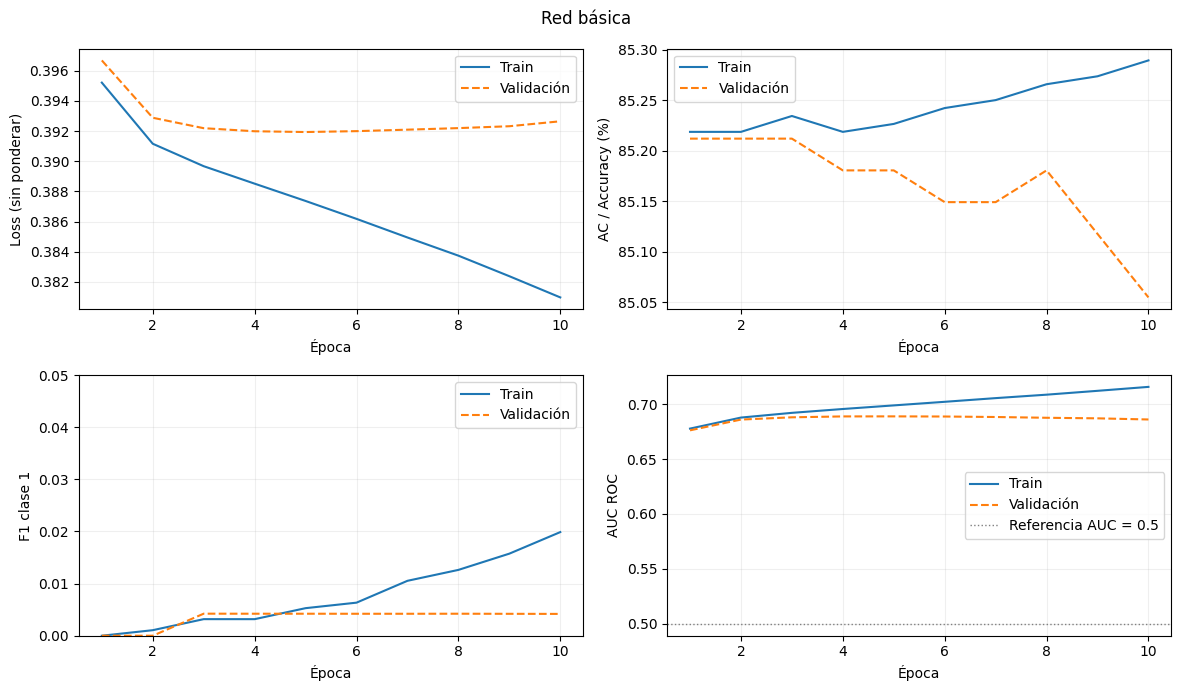

Balanceo: sin pesos | AP: 0.264 | F1 optimizado: 0.3602 | AUC: 0.686 | F1: 0.0042 | positivos: 7 | épocas: 10


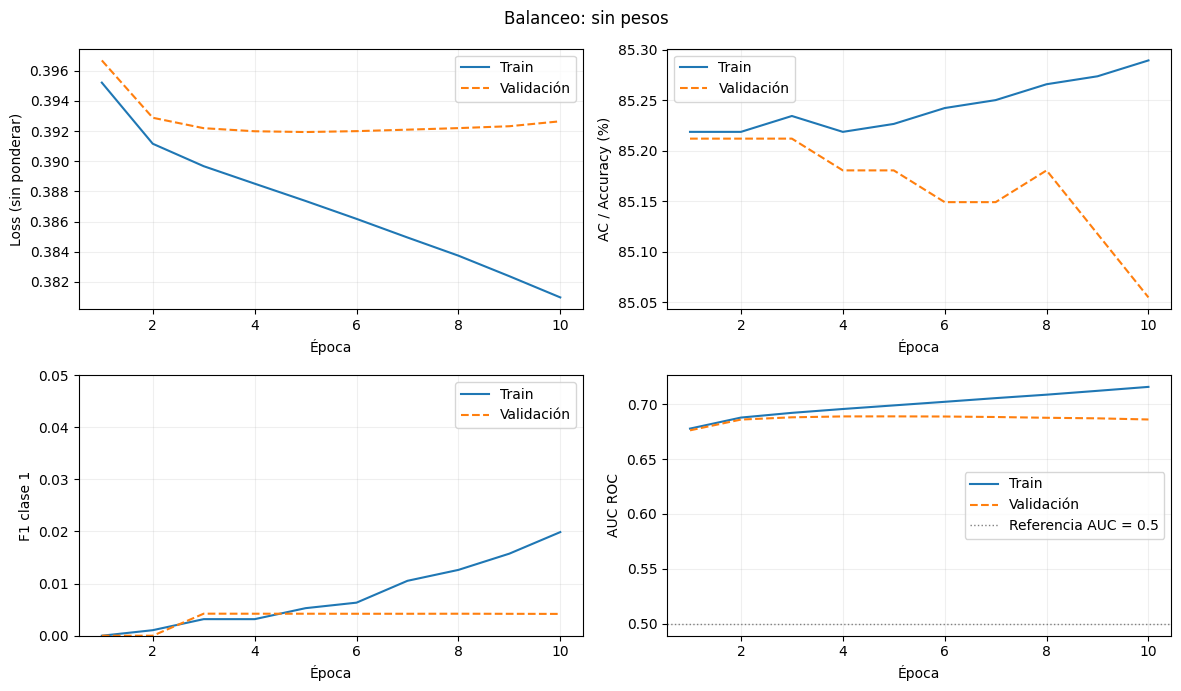

Balanceo: pesos balanceados | AP: 0.2638 | F1 optimizado: 0.3593 | AUC: 0.6835 | F1: 0.3547 | positivos: 1170 | épocas: 10


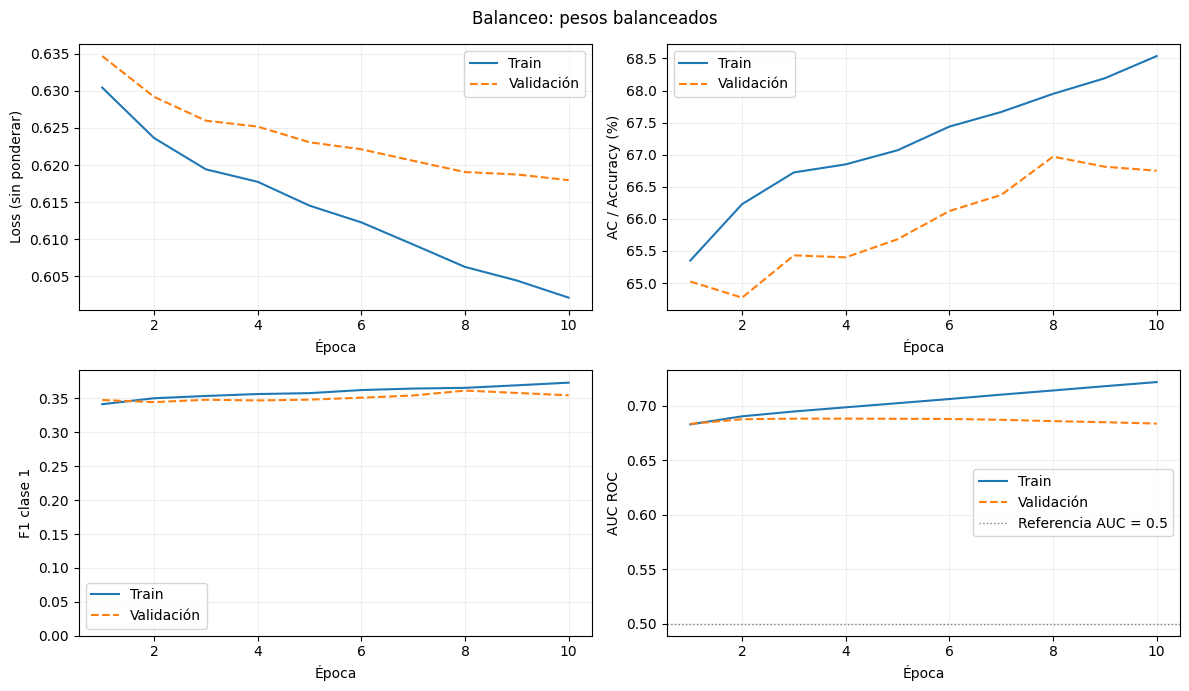

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
0,Balanceo: sin pesos,0.392646,85.054945,0.004184,0.054942,0.685967,0.371935,0.264035,0.499956,0.142857,0.002123,7,2708,6,470,1,0.157158,0.360202,0.256043,0.607219,1,[100],100,5101,10,10,7.505920
1,Balanceo: pesos balanceados,0.617967,66.750392,0.354662,-0.701951,0.683520,0.367039,0.263806,0.646979,0.248718,0.617834,1170,1835,879,180,291,0.494052,0.359310,0.249587,0.641189,1,[100],100,5101,10,10,6.218872


Se conserva: Balanceo: sin pesos


In [6]:
config_basica = dict(hidden_layers=[100],activation='relu',optimizer='adam',lr=.001,
    dropout=0.,l1=0.,l2=0.,balanceado=False,epochs=10,batch=64,early_stopping=False,patience=5)
modelo_original,fila_original = entrenar('Red básica',config_basica)
config_actual,modelo_mejorado = etapa('Balanceo',config_basica,
    [('sin pesos',{'balanceado':False}),('pesos balanceados',{'balanceado':True})])
config_actual.update(epochs=EPOCAS_BUSQUEDA,early_stopping=True)

## 4.1 Optimizador
Momentum se implementa mediante SGD con momentum 0.9.

Optimizador: sgd | AP: 0.2366 | F1 optimizado: 0.3485 | AUC: 0.666 | F1: 0.0 | positivos: 0 | épocas: 100


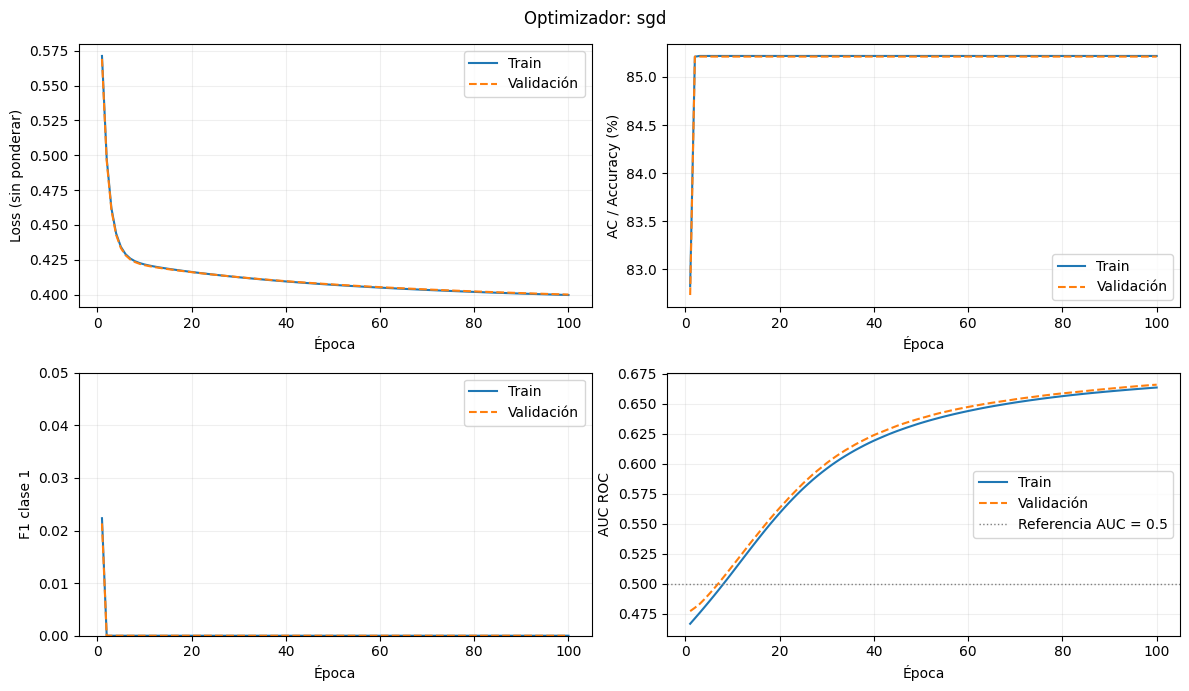

Optimizador: adam | AP: 0.2661 | F1 optimizado: 0.3611 | AUC: 0.6888 | F1: 0.0042 | positivos: 3 | épocas: 10


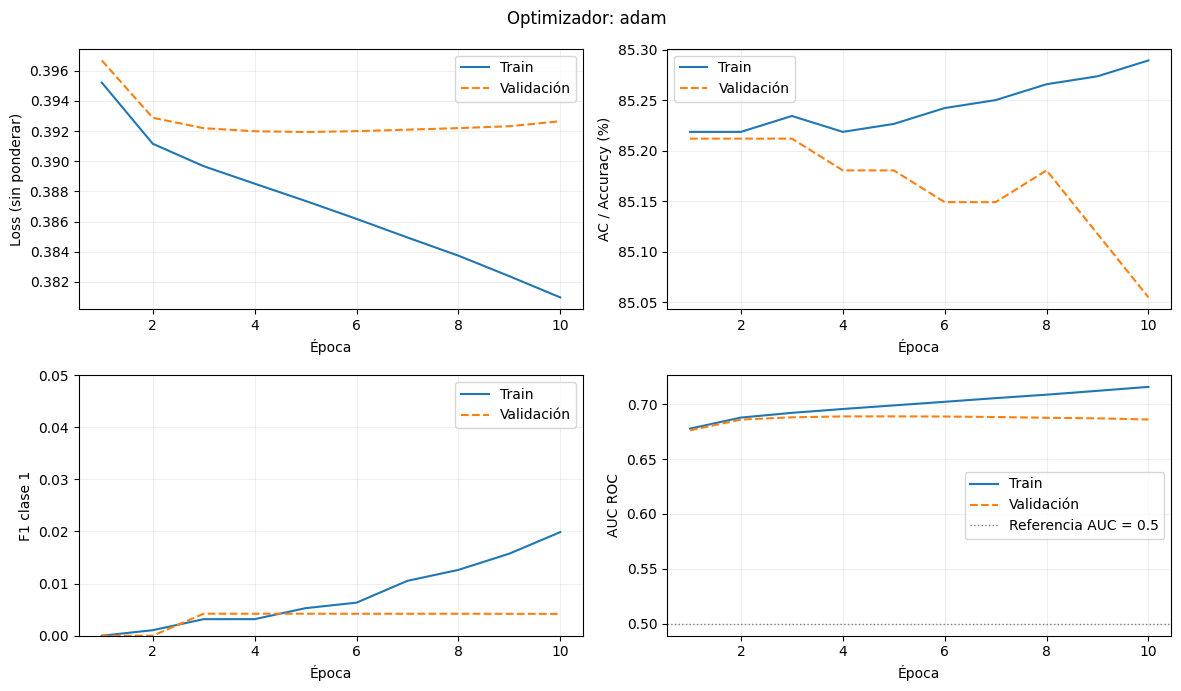

Optimizador: rmsprop | AP: 0.2643 | F1 optimizado: 0.3603 | AUC: 0.6873 | F1: 0.0042 | positivos: 2 | épocas: 10


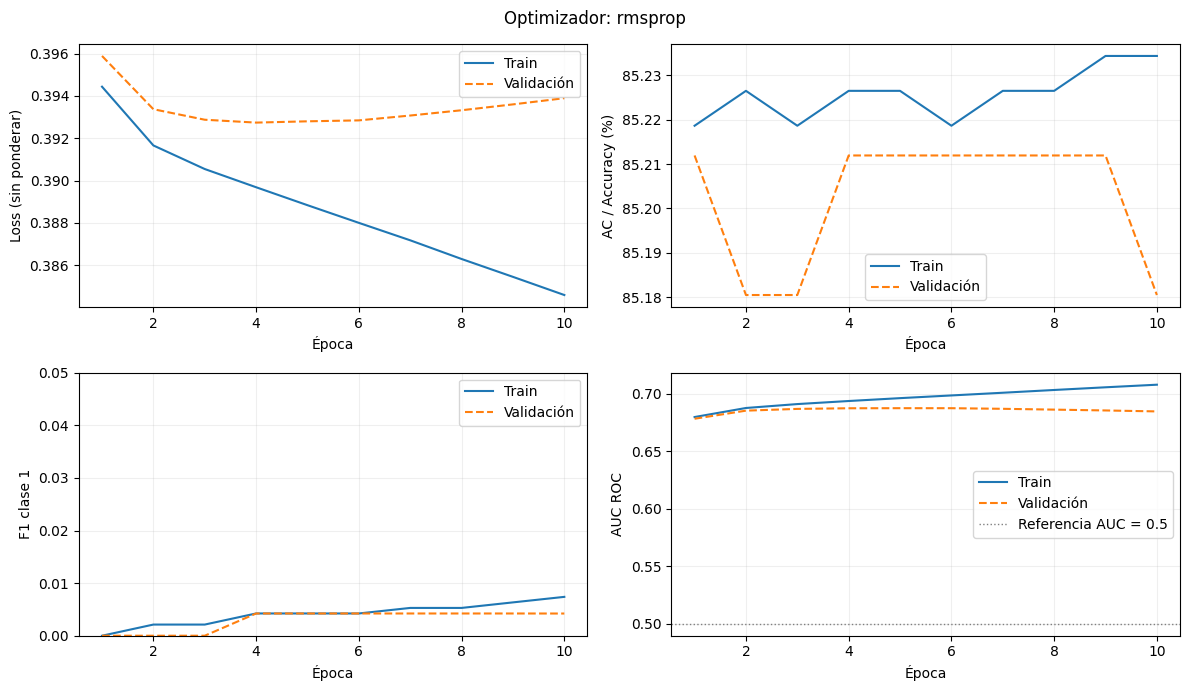

Optimizador: momentum | AP: 0.2646 | F1 optimizado: 0.3605 | AUC: 0.688 | F1: 0.0 | positivos: 0 | épocas: 60


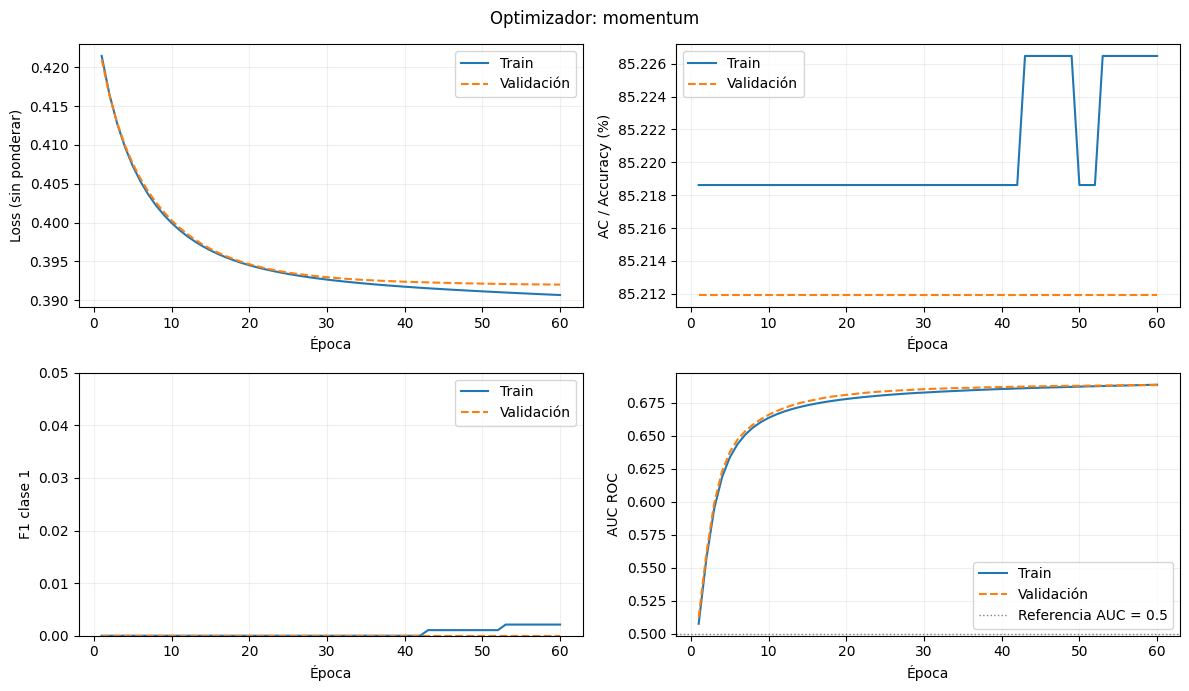

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
1,Optimizador: adam,0.391934,85.180534,0.004219,0.056169,0.688798,0.377595,0.266144,0.500693,0.333333,0.002123,3,2712,2,470,1,0.181114,0.361132,0.282297,0.501062,1,[100],100,5101,10,5,5.859798
3,Optimizador: momentum,0.392040,85.211931,0.000000,0.055567,0.688024,0.376048,0.264614,0.500000,0.000000,0.000000,0,2714,0,471,0,0.174303,0.360521,0.266194,0.558386,1,[100],100,5101,60,55,38.246522
2,Optimizador: rmsprop,0.392798,85.211931,0.004228,0.054175,0.687294,0.374588,0.264280,0.500877,0.500000,0.002123,2,2713,1,470,1,0.158084,0.360348,0.263209,0.571125,1,[100],100,5101,10,5,8.380941
0,Optimizador: sgd,0.400121,85.211931,0.000000,0.038711,0.666006,0.332011,0.236639,0.500000,0.000000,0.000000,0,2714,0,471,0,0.156807,0.348548,0.241776,0.624204,1,[100],100,5101,100,100,62.582452


Se conserva: Optimizador: adam


In [7]:
config_actual, modelo_mejorado = etapa('Optimizador', config_actual, [(a,{'optimizer':a}) for a in ['sgd','adam','rmsprop','momentum']])

## 4.2 Tasa de aprendizaje
Misma arquitectura y optimizador; solo cambia learning rate.

Learning rate: 0.01 | AP: 0.2683 | F1 optimizado: 0.3511 | AUC: 0.6829 | F1: 0.0547 | positivos: 41 | épocas: 9


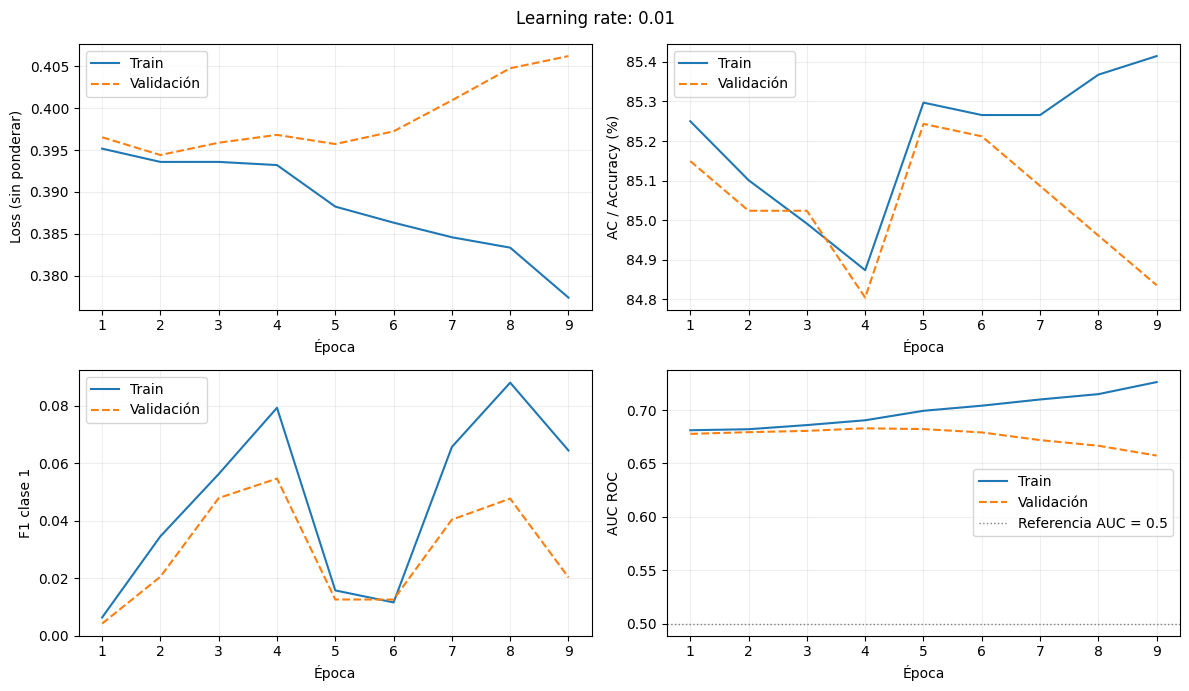

Learning rate: 0.001 | AP: 0.2661 | F1 optimizado: 0.3611 | AUC: 0.6888 | F1: 0.0042 | positivos: 3 | épocas: 10


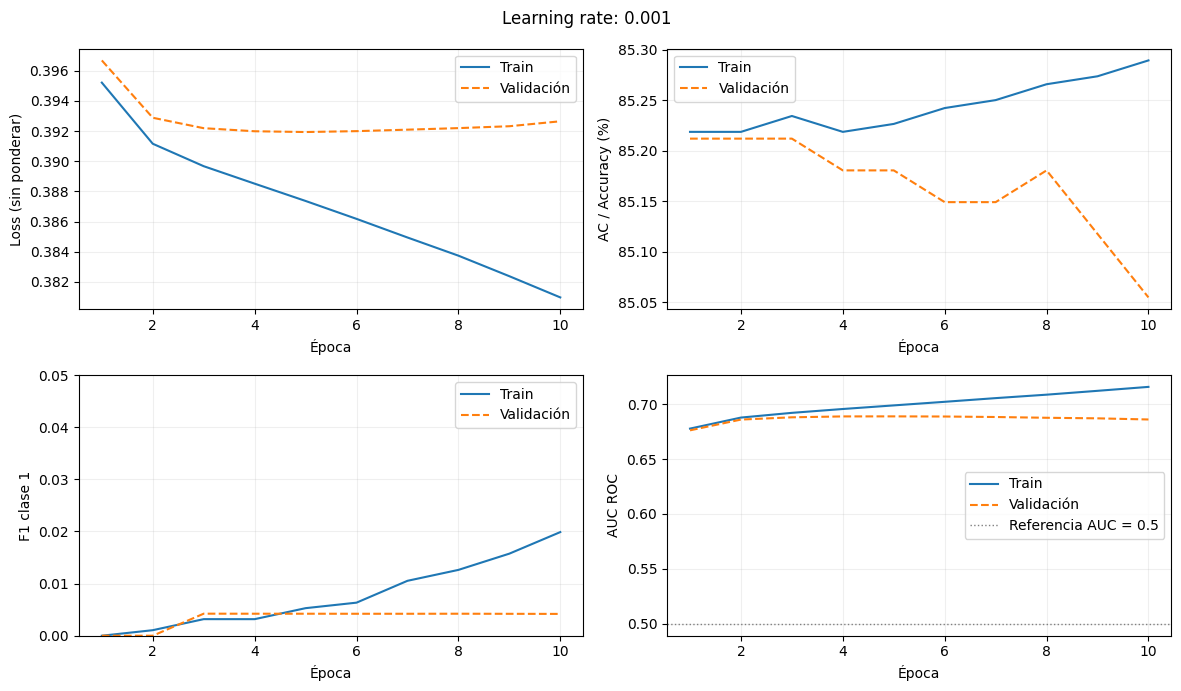

Learning rate: 0.0001 | AP: 0.269 | F1 optimizado: 0.3656 | AUC: 0.6895 | F1: 0.0042 | positivos: 3 | épocas: 48


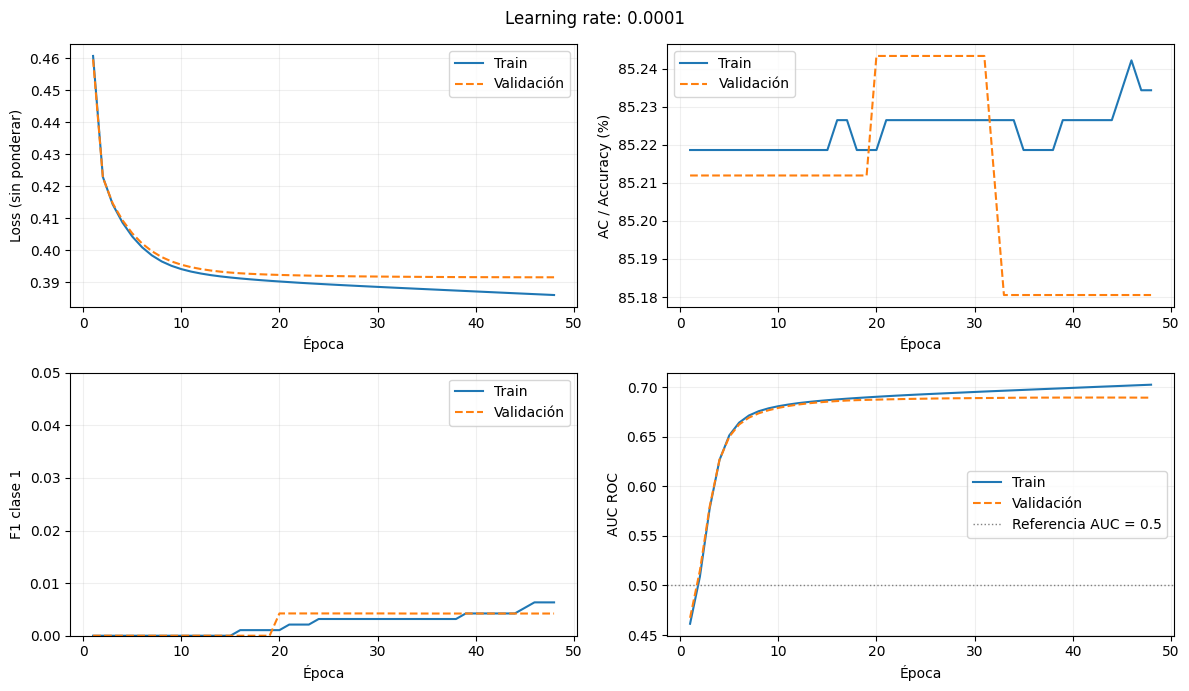

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
2,Learning rate: 0.0001,0.391570,85.180534,0.004219,0.057215,0.689536,0.379072,0.269018,0.500693,0.333333,0.002123,3,2712,2,470,1,0.174459,0.365636,0.270325,0.564756,1,[100],100,5101,48,43,28.642145
0,Learning rate: 0.01,0.396804,84.803768,0.054688,0.042136,0.682891,0.365783,0.268296,0.509888,0.341463,0.029724,41,2687,27,457,14,0.245057,0.351145,0.292373,0.439490,1,[100],100,5101,9,4,5.422714
1,Learning rate: 0.001,0.391934,85.180534,0.004219,0.056169,0.688798,0.377595,0.266144,0.500693,0.333333,0.002123,3,2712,2,470,1,0.181114,0.361132,0.282297,0.501062,1,[100],100,5101,10,5,7.479648


Se conserva: Learning rate: 0.0001


In [8]:
config_actual, modelo_mejorado = etapa('Learning rate', config_actual, [(str(v),{'lr':v}) for v in [.01,.001,.0001]])

## 4.3 Batch size
Se mantiene el número de épocas de la configuración de búsqueda (`EPOCAS_BUSQUEDA`).

Batch: 32 | AP: 0.2693 | F1 optimizado: 0.365 | AUC: 0.6899 | F1: 0.0042 | positivos: 3 | épocas: 32


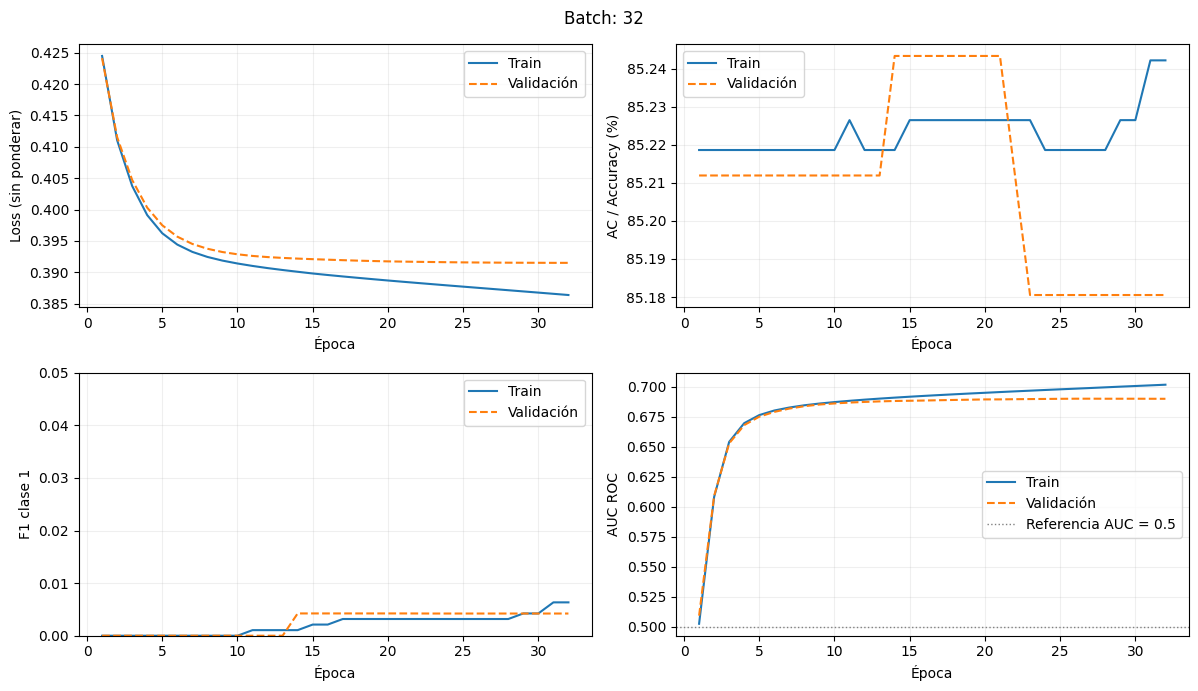

Batch: 64 | AP: 0.269 | F1 optimizado: 0.3656 | AUC: 0.6895 | F1: 0.0042 | positivos: 3 | épocas: 48


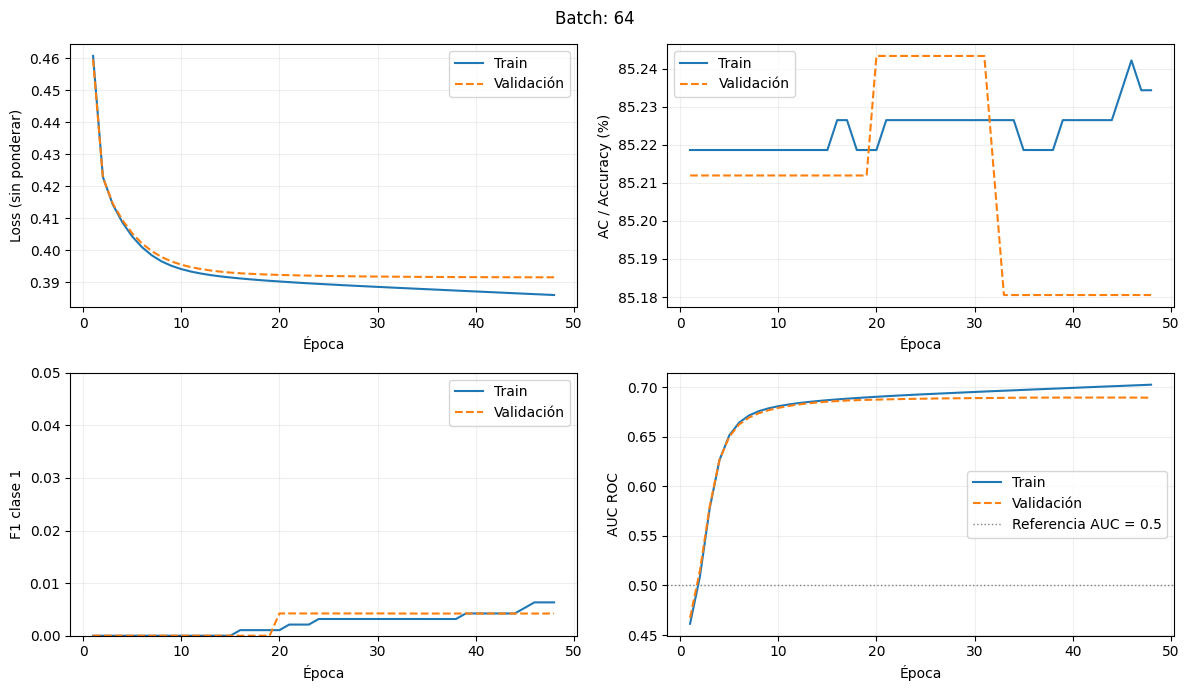

Batch: 128 | AP: 0.2685 | F1 optimizado: 0.3622 | AUC: 0.6892 | F1: 0.0042 | positivos: 3 | épocas: 58


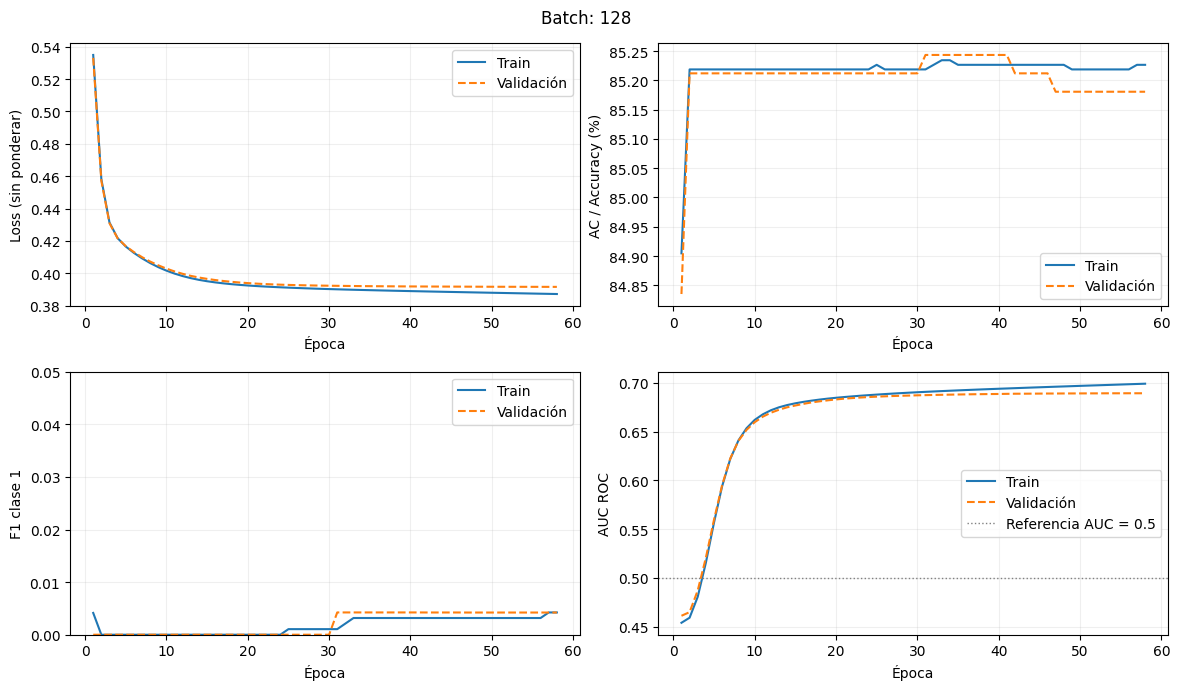

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
0,Batch: 32,0.391553,85.180534,0.004219,0.057229,0.689898,0.379795,0.269288,0.500693,0.333333,0.002123,3,2712,2,470,1,0.175430,0.365035,0.272158,0.554140,1,[100],100,5101,32,27,32.524719
1,Batch: 64,0.391570,85.180534,0.004219,0.057215,0.689536,0.379072,0.269018,0.500693,0.333333,0.002123,3,2712,2,470,1,0.174459,0.365636,0.270325,0.564756,1,[100],100,5101,48,43,28.644187
2,Batch: 128,0.391678,85.180534,0.004219,0.057112,0.689158,0.378315,0.268494,0.500693,0.333333,0.002123,3,2712,2,470,1,0.172856,0.362173,0.264706,0.573248,1,[100],100,5101,58,53,21.929308


Se conserva: Batch: 32


In [9]:
config_actual, modelo_mejorado = etapa('Batch', config_actual, [(str(n),{'batch':n}) for n in [32,64,128]])

## 4.4 Activación
La salida permanece sigmoide; cambia la activación de las capas ocultas. Se conserva la configuración ganadora de las etapas anteriores.

Activación: relu | AP: 0.2693 | F1 optimizado: 0.365 | AUC: 0.6899 | F1: 0.0042 | positivos: 3 | épocas: 32


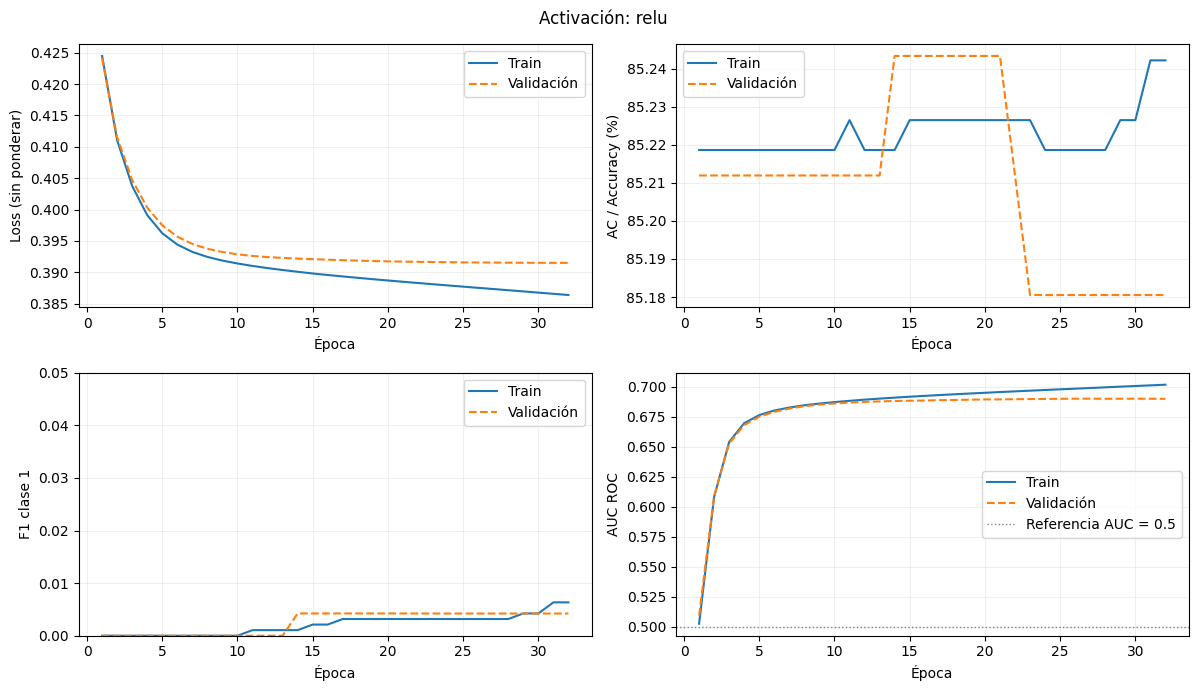

Activación: tanh | AP: 0.2765 | F1 optimizado: 0.3656 | AUC: 0.694 | F1: 0.0209 | positivos: 7 | épocas: 63


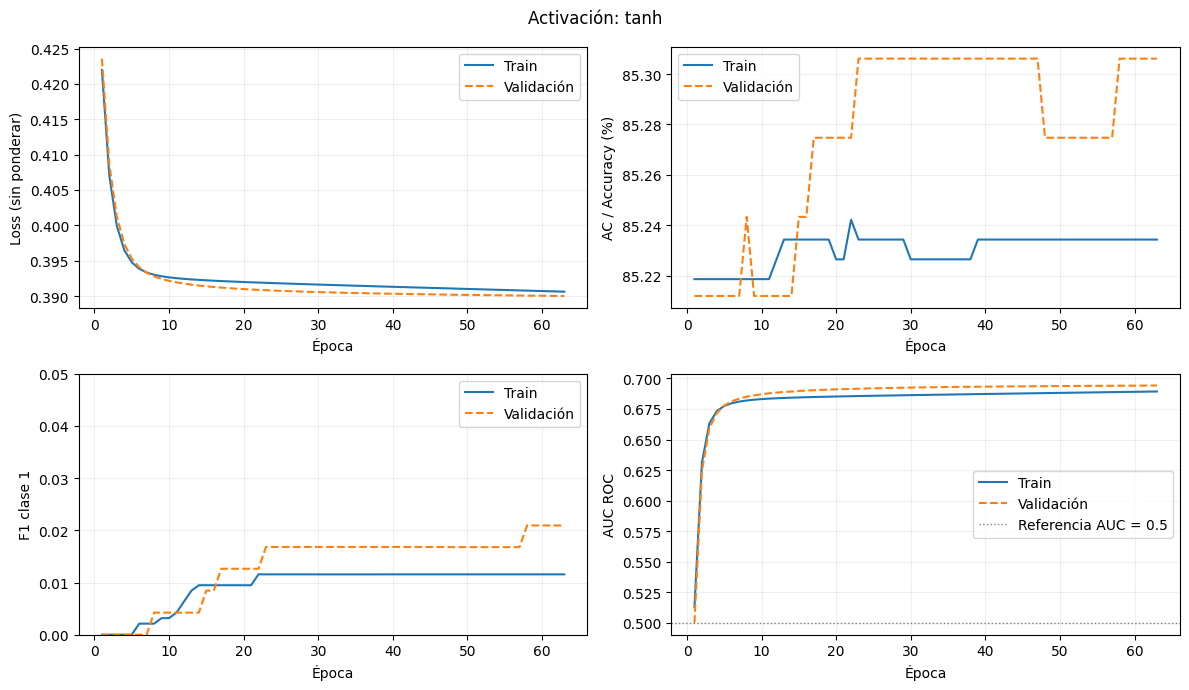

Activación: sigmoid | AP: 0.2738 | F1 optimizado: 0.357 | AUC: 0.6909 | F1: 0.0084 | positivos: 3 | épocas: 69


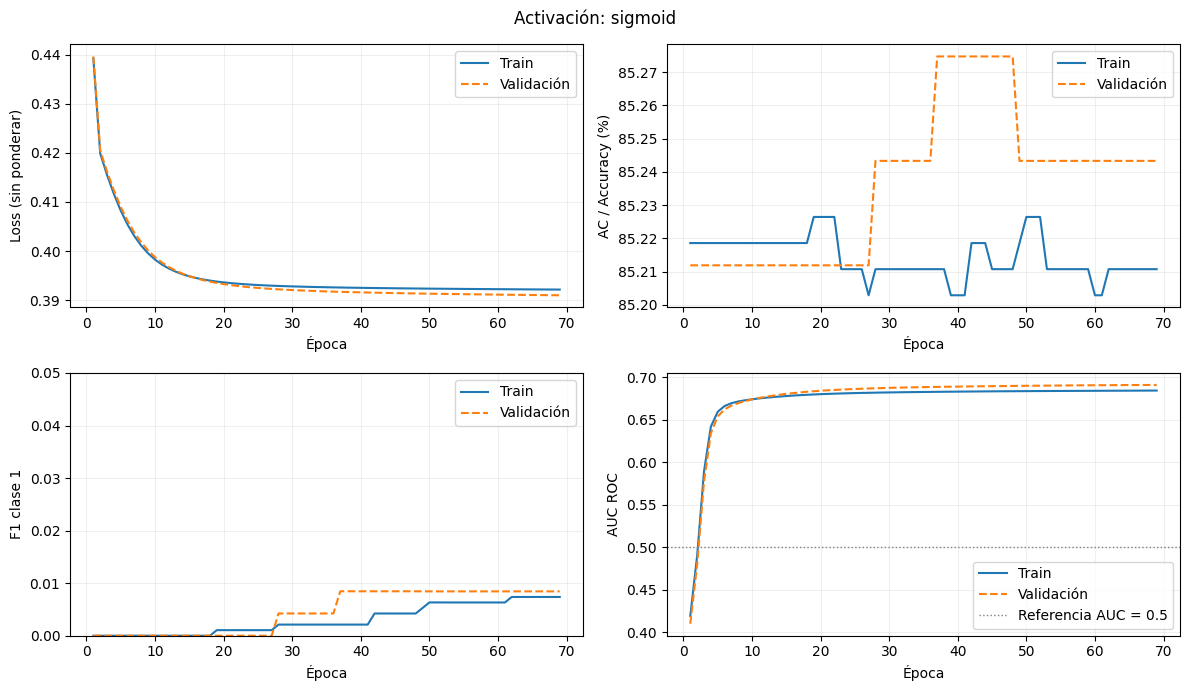

Activación: elu | AP: 0.2757 | F1 optimizado: 0.3666 | AUC: 0.6937 | F1: 0.0126 | positivos: 5 | épocas: 73


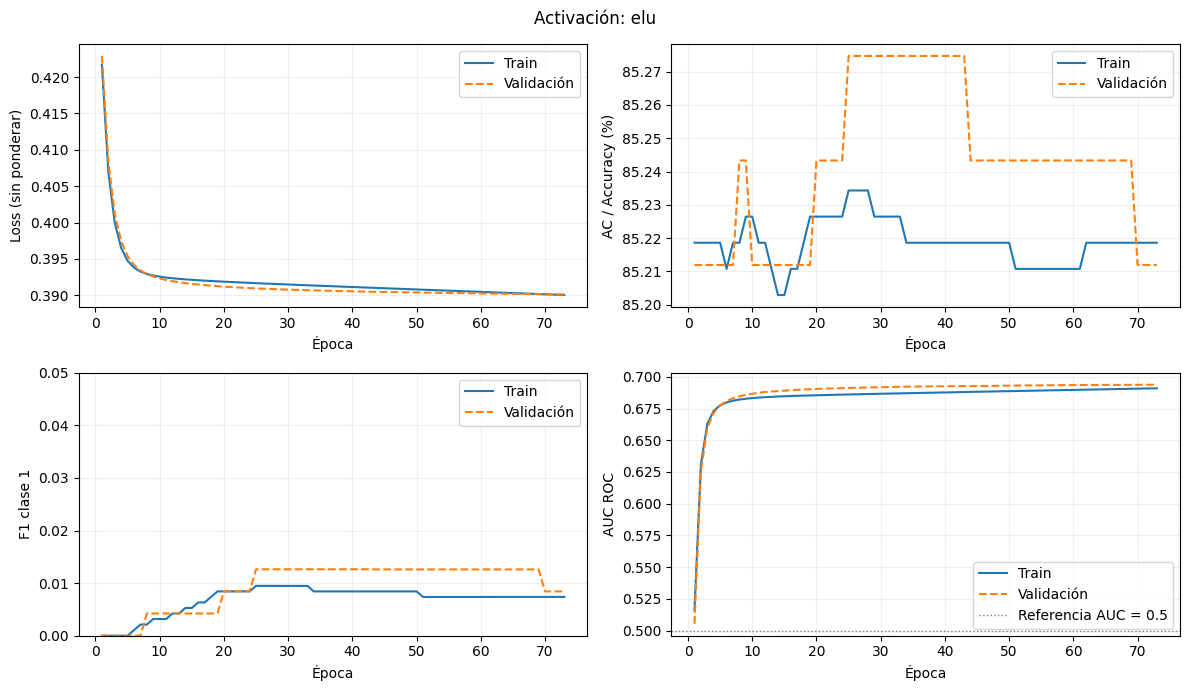

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
1,Activación: tanh,0.390060,85.306122,0.020921,0.060142,0.694037,0.388074,0.276534,0.504939,0.714286,0.010616,7,2712,2,466,5,0.175207,0.365576,0.274866,0.545648,1,[100],100,5101,63,58,61.471786
3,Activación: elu,0.390177,85.243328,0.012605,0.060016,0.693653,0.387307,0.275702,0.502816,0.600000,0.006369,5,2712,2,468,3,0.174988,0.366596,0.274947,0.549894,1,[100],100,5101,73,68,76.578013
2,Activación: sigmoid,0.391059,85.243328,0.008439,0.058036,0.690872,0.381743,0.273764,0.501939,0.666667,0.004246,3,2713,1,469,2,0.174211,0.356992,0.266807,0.539278,1,[100],100,5101,69,64,68.614443
0,Activación: relu,0.391553,85.180534,0.004219,0.057229,0.689898,0.379795,0.269288,0.500693,0.333333,0.002123,3,2712,2,470,1,0.175430,0.365035,0.272158,0.554140,1,[100],100,5101,32,27,35.747066


Se conserva: Activación: tanh


In [10]:
config_actual, modelo_mejorado = etapa('Activación', config_actual, [(a,{'activation':a}) for a in ['relu','tanh','sigmoid','elu']])

## 4.5 Capas ocultas
Se comparan exclusivamente 5, 10 y 20 capas ocultas. Se conserva la mejor por AP de validación; no se permite seleccionar 1 ni 2 capas. La restricción es didáctica y no implica que una red profunda generalice mejor.

Capas: 5 | AP: 0.2681 | F1 optimizado: 0.3509 | AUC: 0.6852 | F1: 0.0167 | positivos: 7 | épocas: 14


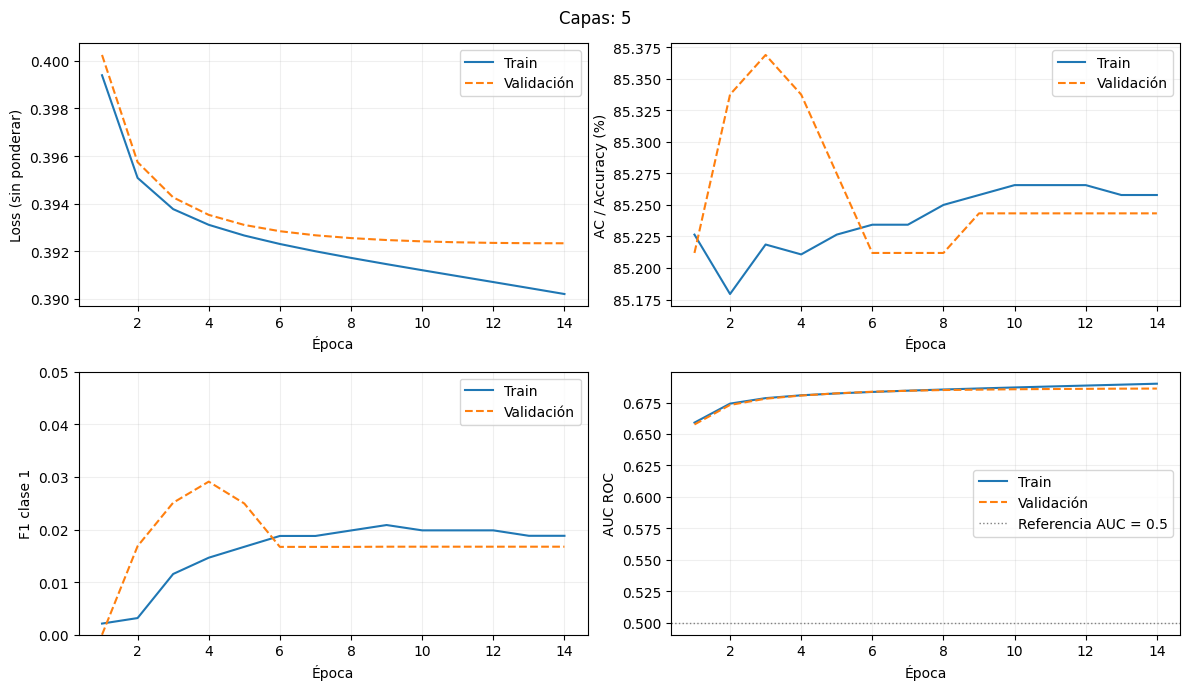

Capas: 10 | AP: 0.2647 | F1 optimizado: 0.3548 | AUC: 0.6814 | F1: 0.0084 | positivos: 6 | épocas: 21


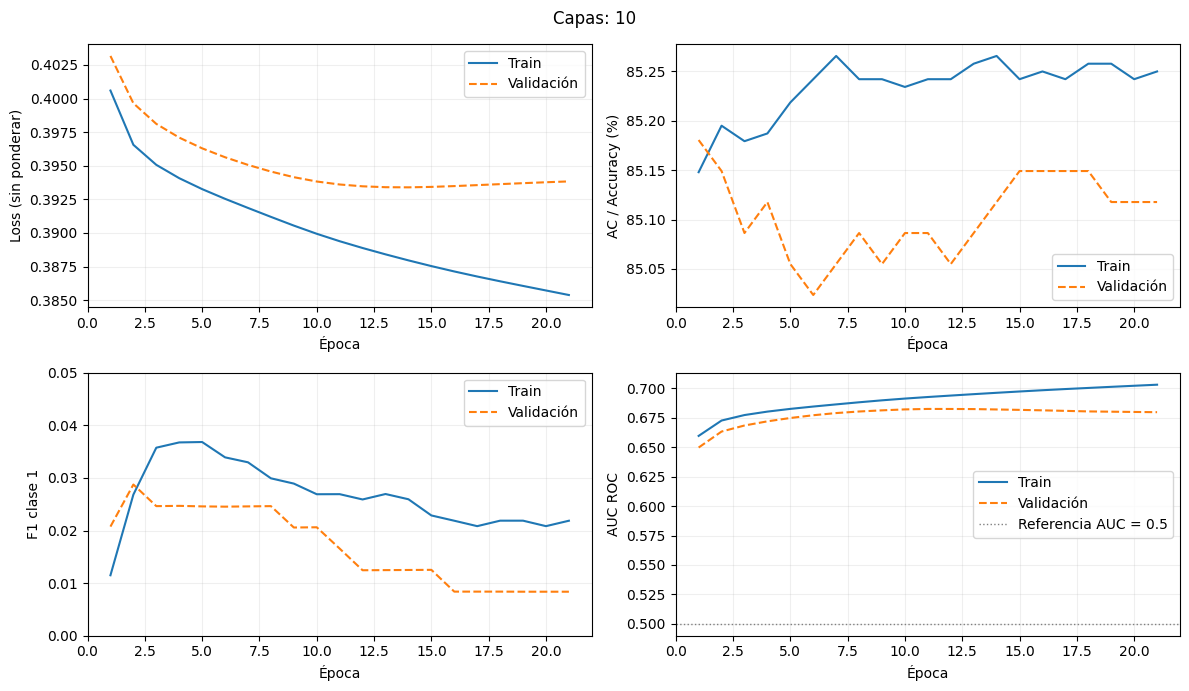

Capas: 20 | AP: 0.2721 | F1 optimizado: 0.3458 | AUC: 0.6836 | F1: 0.0778 | positivos: 43 | épocas: 38


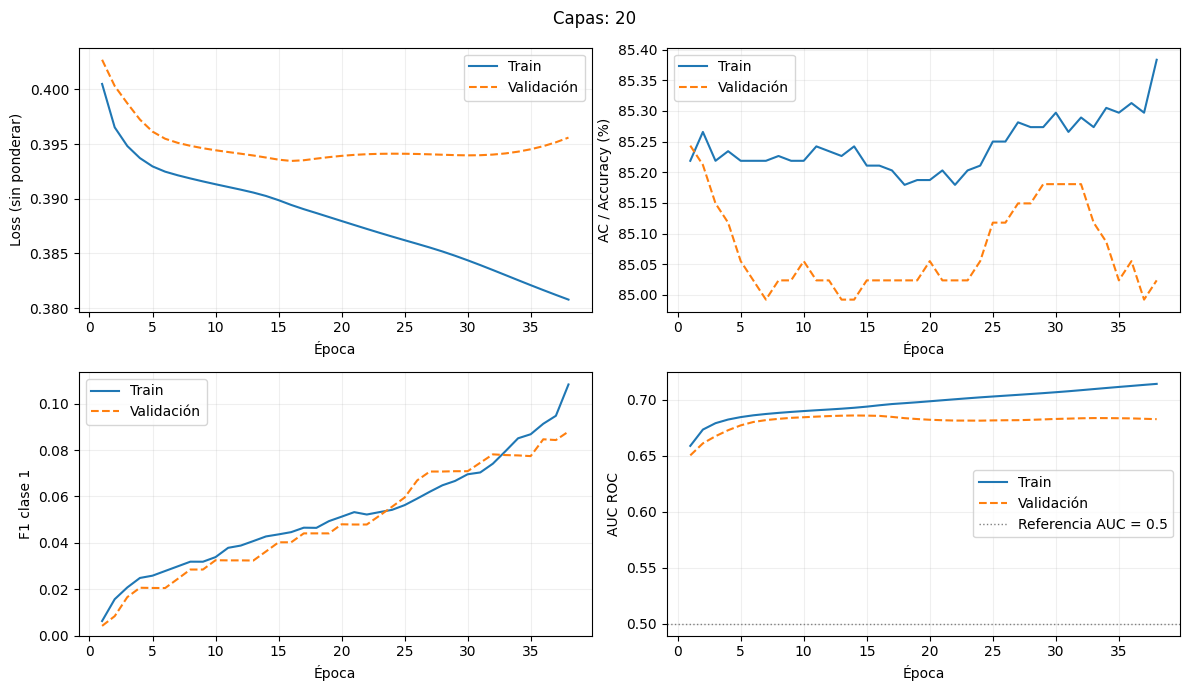

Capas: 50 | AP: 0.2623 | F1 optimizado: 0.3534 | AUC: 0.6817 | F1: 0.0 | positivos: 0 | épocas: 19


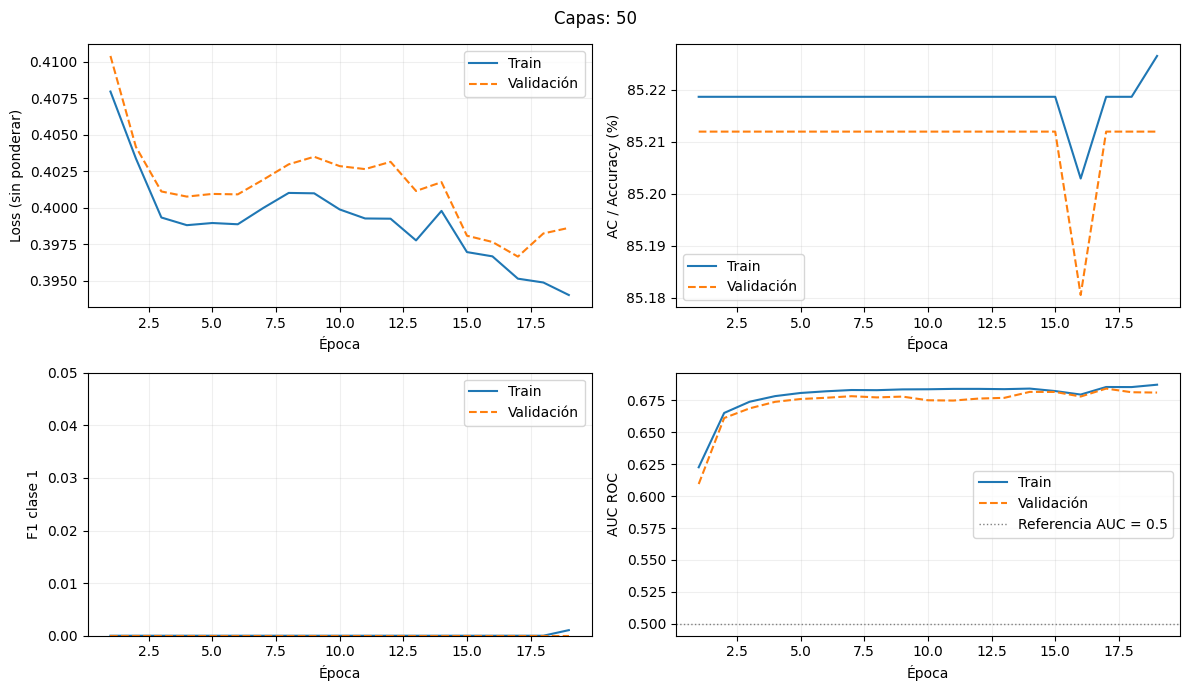

Capas: 100 | AP: 0.1782 | F1 optimizado: 0.276 | AUC: 0.5716 | F1: 0.0 | positivos: 0 | épocas: 7


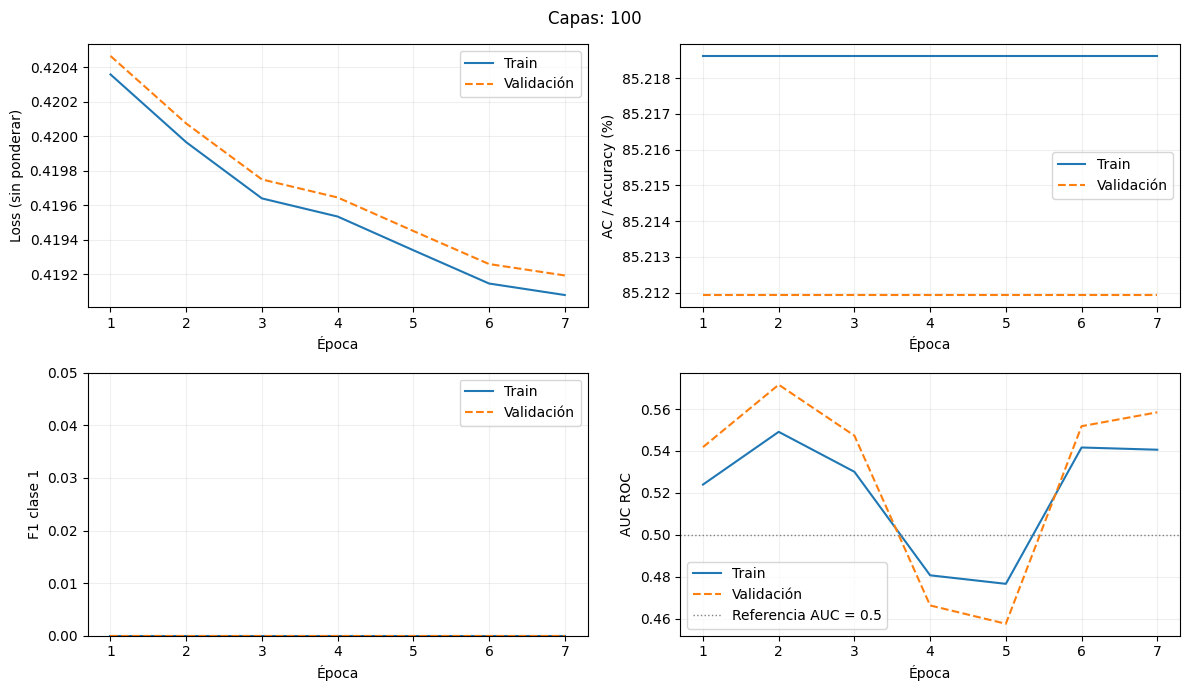

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
2,Capas: 20,0.394149,85.117739,0.077821,0.048664,0.683618,0.367236,0.272145,0.516994,0.465116,0.042463,43,2691,23,451,20,0.185378,0.345776,0.250000,0.560510,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,38,33,108.889903
0,Capas: 5,0.392473,85.243328,0.016736,0.054502,0.685208,0.370416,0.268116,0.503694,0.571429,0.008493,7,2711,3,467,4,0.179250,0.350903,0.265864,0.515924,5,"[64, 64, 64, 64, 64]",320,19905,14,9,19.840724
1,Capas: 10,0.393488,85.149137,0.008386,0.052044,0.681378,0.362755,0.264741,0.501386,0.333333,0.004246,6,2710,4,469,2,0.192309,0.354839,0.264921,0.537155,10,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64]",640,40705,21,16,39.587116
3,Capas: 50,0.401747,85.211931,0.000000,0.036417,0.681727,0.363453,0.262325,0.500000,0.000000,0.000000,0,2714,0,471,0,0.201061,0.353372,0.269877,0.511677,50,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",3200,207105,19,14,118.654476
4,Capas: 100,0.420075,85.211931,0.000000,-0.002248,0.571602,0.143204,0.178193,0.500000,0.000000,0.000000,0,2714,0,471,0,0.164713,0.276025,0.169492,0.743100,100,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",6400,415105,7,2,96.247600


Se conserva: Capas: 20


In [11]:
config_actual, modelo_mejorado = etapa('Capas', config_actual, [(str(n),{'hidden_layers':[64]*n}) for n in [5,10,20,50,100]])

## 4.6 Neuronas por capa
Se fija la profundidad ganadora y se varía el ancho.

Neuronas: 32 | AP: 0.2551 | F1 optimizado: 0.3288 | AUC: 0.6672 | F1: 0.0042 | positivos: 1 | épocas: 8


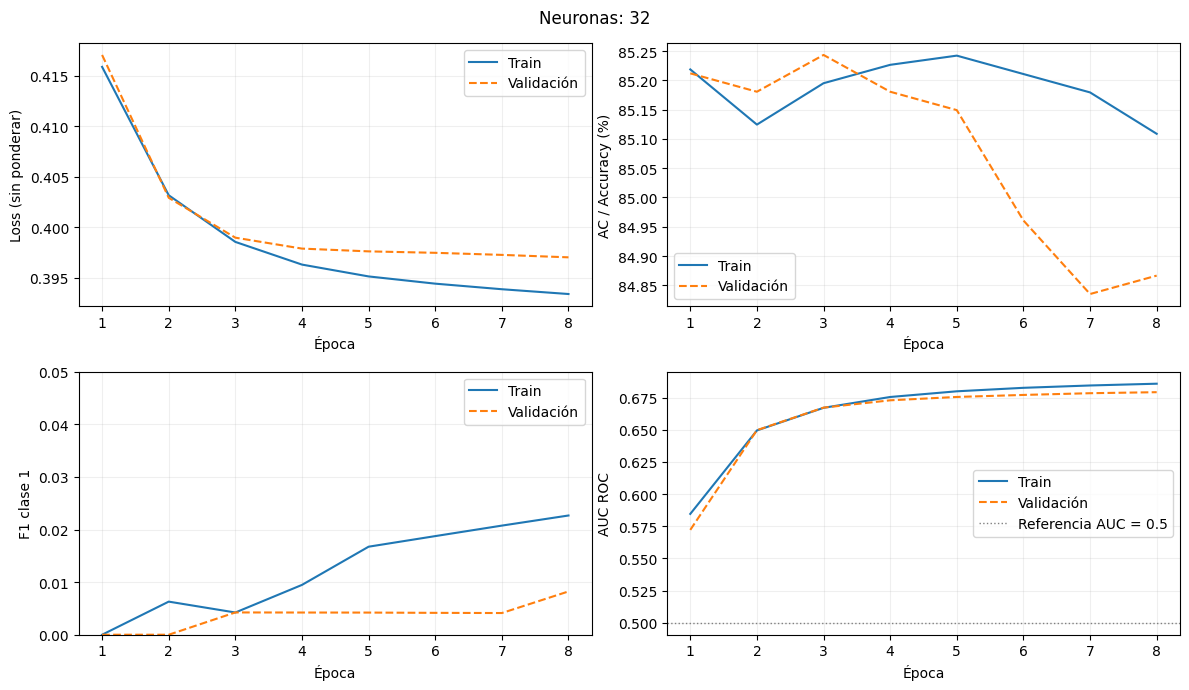

Neuronas: 64 | AP: 0.2721 | F1 optimizado: 0.3458 | AUC: 0.6836 | F1: 0.0778 | positivos: 43 | épocas: 38


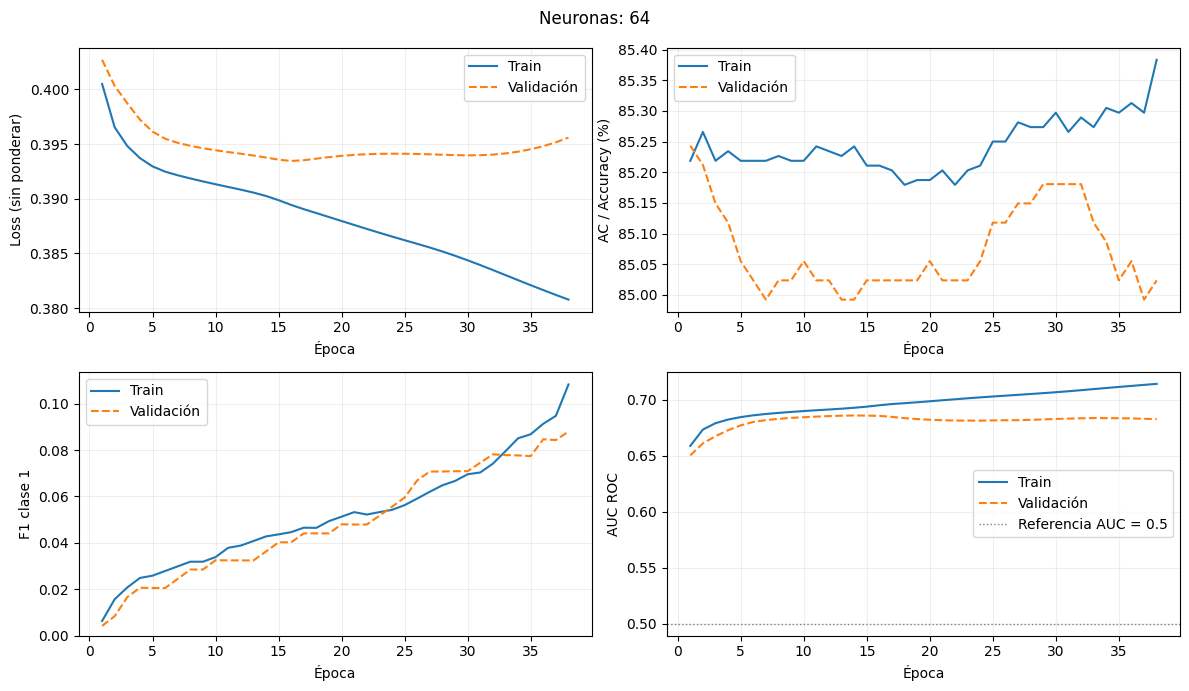

Neuronas: 128 | AP: 0.2563 | F1 optimizado: 0.3478 | AUC: 0.681 | F1: 0.0 | positivos: 0 | épocas: 8


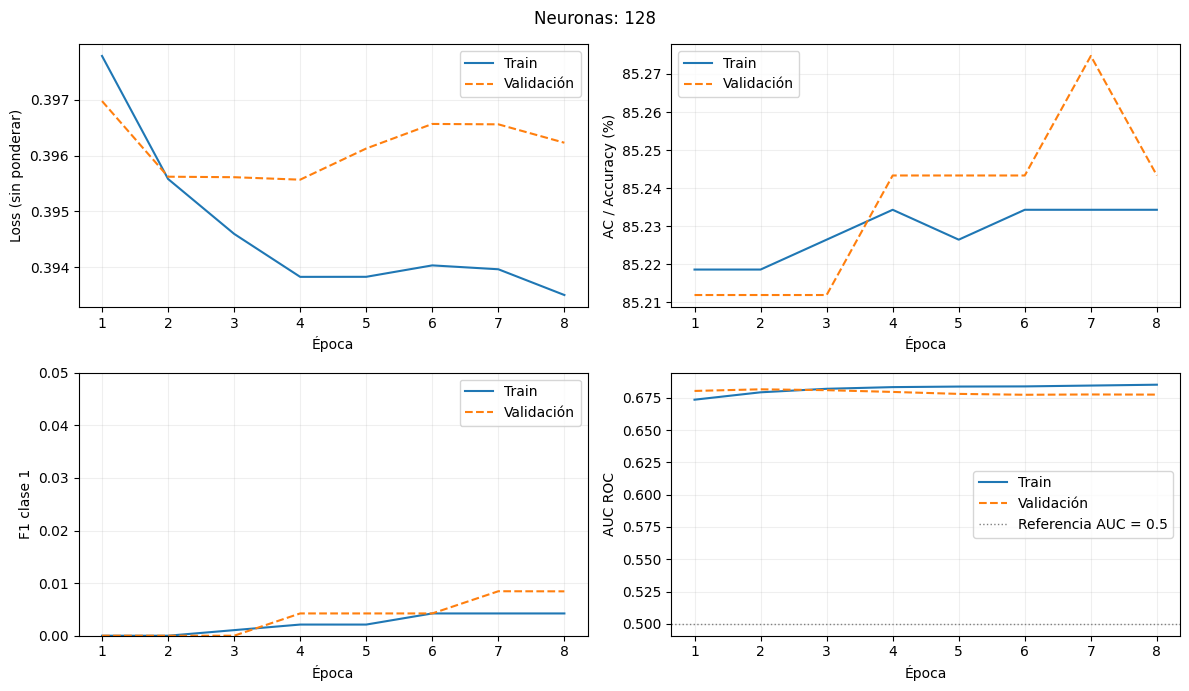

Neuronas: 256 | AP: 0.2499 | F1 optimizado: 0.3504 | AUC: 0.6754 | F1: 0.0 | positivos: 0 | épocas: 6


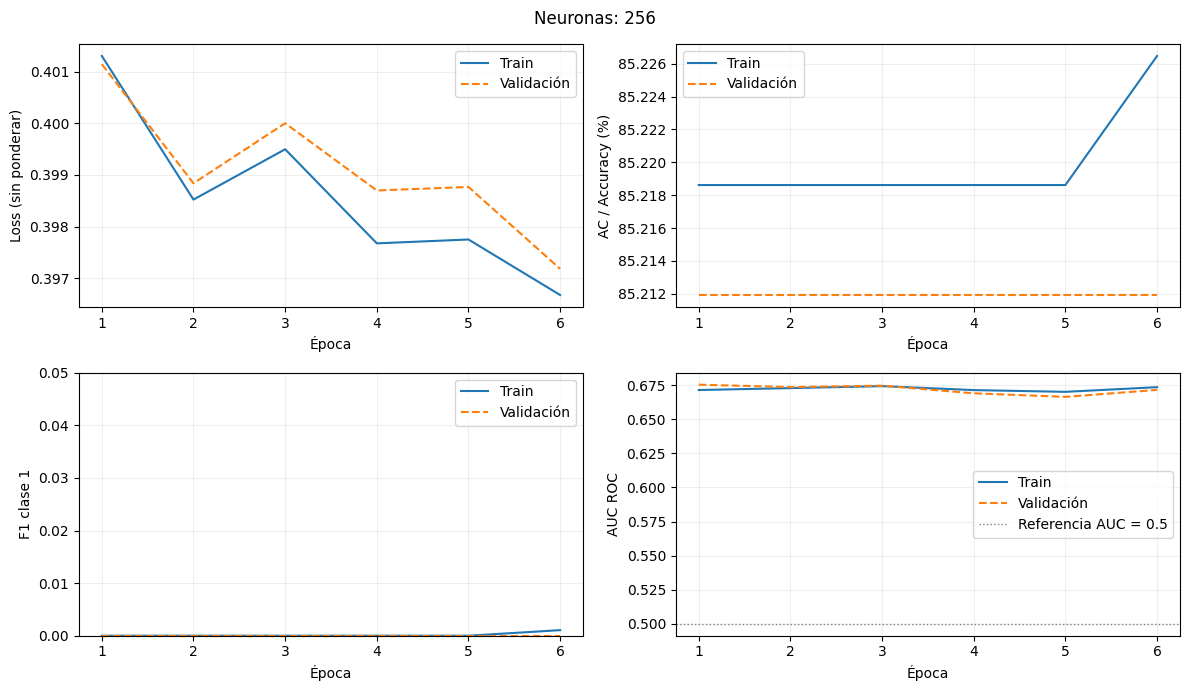

Neuronas: 512 | AP: 0.256 | F1 optimizado: 0.3539 | AUC: 0.6836 | F1: 0.0 | positivos: 0 | épocas: 10


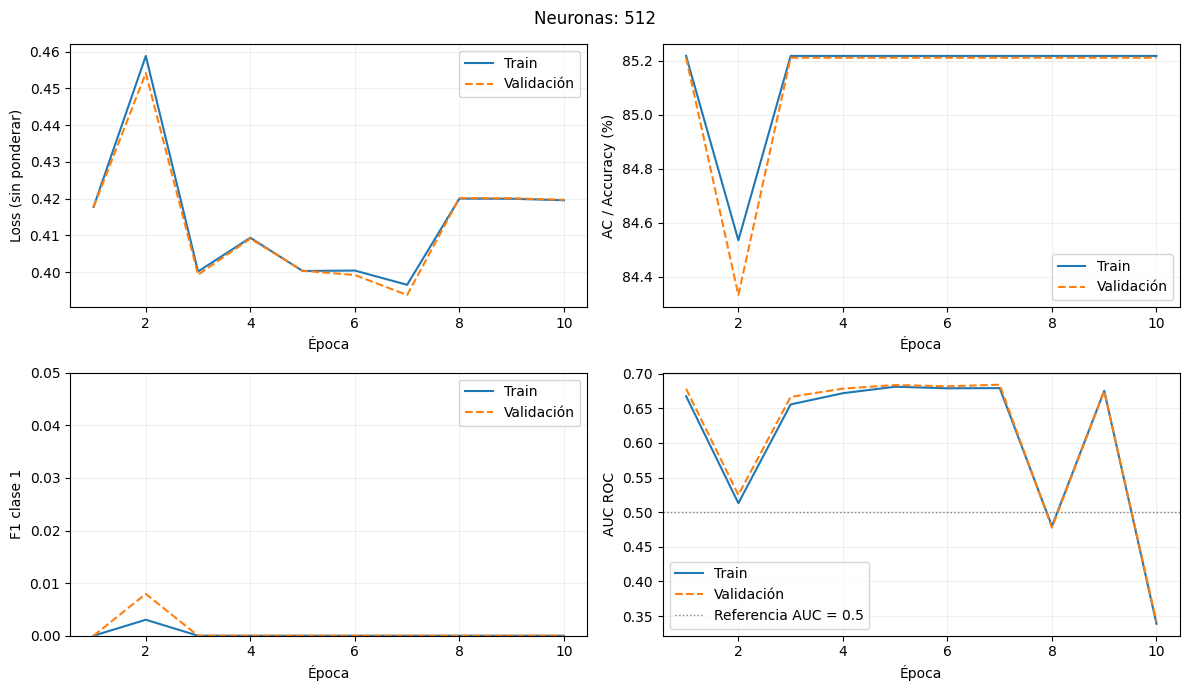

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
1,Neuronas: 64,0.394149,85.117739,0.077821,0.048664,0.683618,0.367236,0.272145,0.516994,0.465116,0.042463,43,2691,23,451,20,0.185378,0.345776,0.250000,0.560510,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,38,33,109.375654
2,Neuronas: 128,0.395613,85.211931,0.000000,0.048942,0.680983,0.361967,0.256305,0.500000,0.000000,0.000000,0,2714,0,471,0,0.183028,0.347826,0.241722,0.619958,20,"[128, 128, 128, 128, 128, 128, 128, 128, 128, ...",2560,320257,8,3,35.334675
4,Neuronas: 512,0.400377,85.211931,0.000000,0.037742,0.683638,0.367276,0.255956,0.500000,0.000000,0.000000,0,2714,0,471,0,0.139767,0.353916,0.274212,0.498938,20,"[512, 512, 512, 512, 512, 512, 512, 512, 512, ...",10240,5016577,10,5,376.735717
0,Neuronas: 32,0.398953,85.243328,0.004237,0.040810,0.667189,0.334378,0.255091,0.501062,1.000000,0.002123,1,2714,0,470,1,0.206571,0.328845,0.246809,0.492569,20,"[32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 3...",640,21697,8,3,24.397194
3,Neuronas: 256,0.401145,85.211931,0.000000,0.034275,0.675431,0.350863,0.249913,0.500000,0.000000,0.000000,0,2714,0,471,0,0.154464,0.350376,0.271246,0.494692,20,"[256, 256, 256, 256, 256, 256, 256, 256, 256, ...",5120,1263105,6,1,64.143836


Se conserva: Neuronas: 64


In [12]:
config_actual, modelo_mejorado = etapa('Neuronas', config_actual, [(str(n),{'hidden_layers':[n]*len(config_actual['hidden_layers'])}) for n in [32,64,128,256,512]])

## 4.7 Distribución de neuronas y cuello de botella
Se compara una arquitectura **uniforme** con tres alternativas:
- **Creciente:** pocas neuronas al inicio y más al final.
- **Decreciente (embudo):** más neuronas al inicio y menos al final.
- **Cuello de botella (combinada):** reducción hacia el centro y expansión posterior.

Todas conservan el número de capas elegido (mínimo 5), el mismo total de neuronas ocultas y los mismos parámetros de entrenamiento. Los pesos entrenables pueden variar porque cambia la conexión entre capas: se reporta su cantidad y no se atribuyen los cambios exclusivamente a la forma. La tabla muestra cada arquitectura exacta. Se dibujan loss, accuracy, F1 y AUC de train/validación para cada alternativa.

El cuello de botella solo se adopta si gana por AP de validación, con F1 optimizado como desempate. Si otra forma gana, se conserva esa forma en todos los experimentos posteriores. Test no se consulta en esta decisión.

,forma,arquitectura,total_neuronas
0,Uniforme,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280
1,Creciente,"[32, 35, 39, 42, 45, 49, 52, 56, 59, 62, 66, 6...",1280
2,Decreciente (embudo),"[96, 93, 89, 86, 83, 79, 76, 72, 69, 66, 62, 5...",1280
3,Cuello de botella,"[94, 87, 80, 74, 67, 61, 54, 48, 41, 34, 34, 4...",1280


Distribución de neuronas: Uniforme | AP: 0.2721 | F1 optimizado: 0.3458 | AUC: 0.6836 | F1: 0.0778 | positivos: 43 | épocas: 38


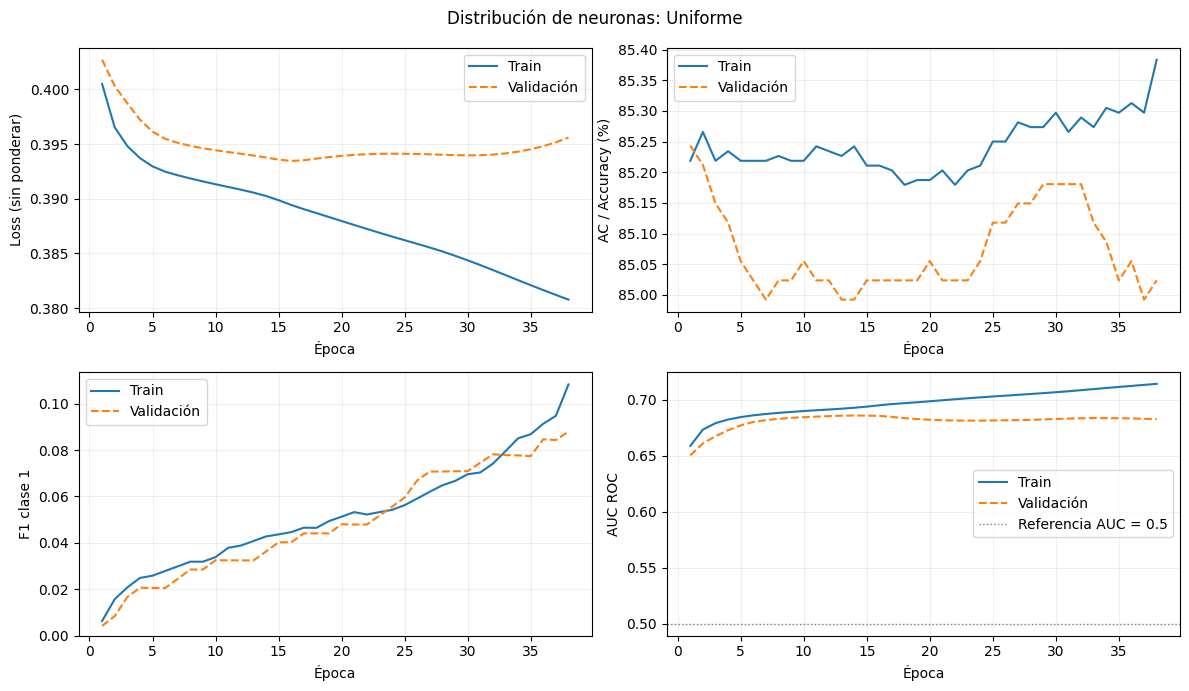

Distribución de neuronas: Creciente | AP: 0.2437 | F1 optimizado: 0.3267 | AUC: 0.6582 | F1: 0.0042 | positivos: 3 | épocas: 7


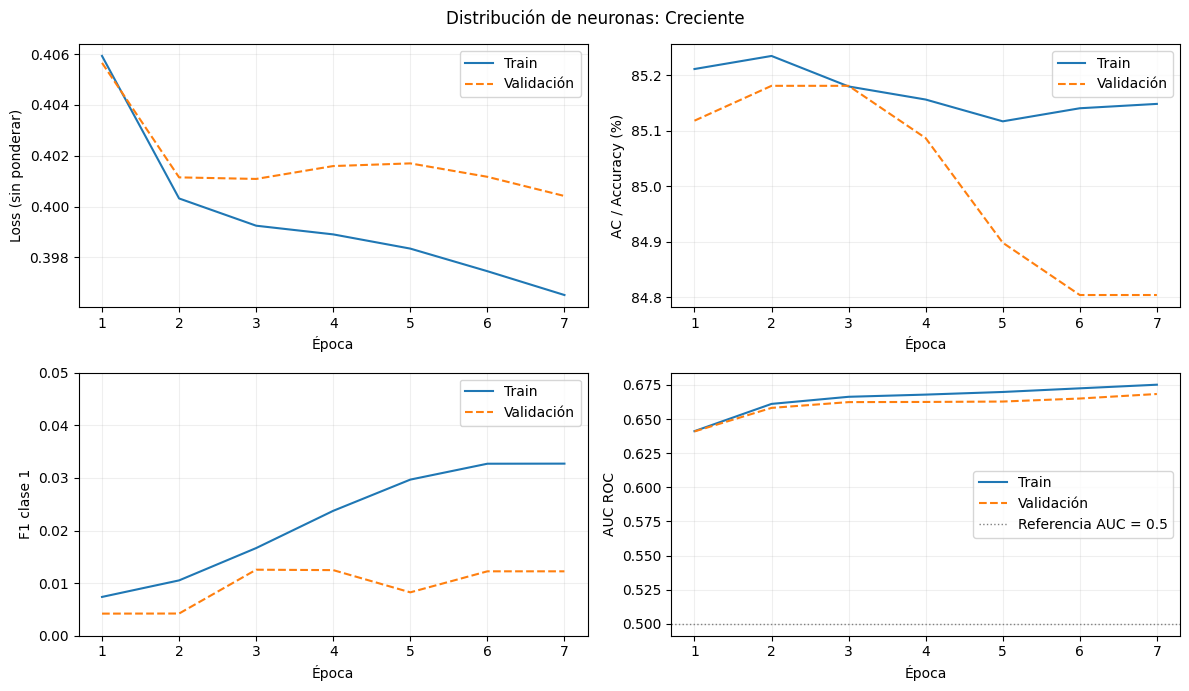

Distribución de neuronas: Decreciente (embudo) | AP: 0.2636 | F1 optimizado: 0.3587 | AUC: 0.6861 | F1: 0.0248 | positivos: 13 | épocas: 16


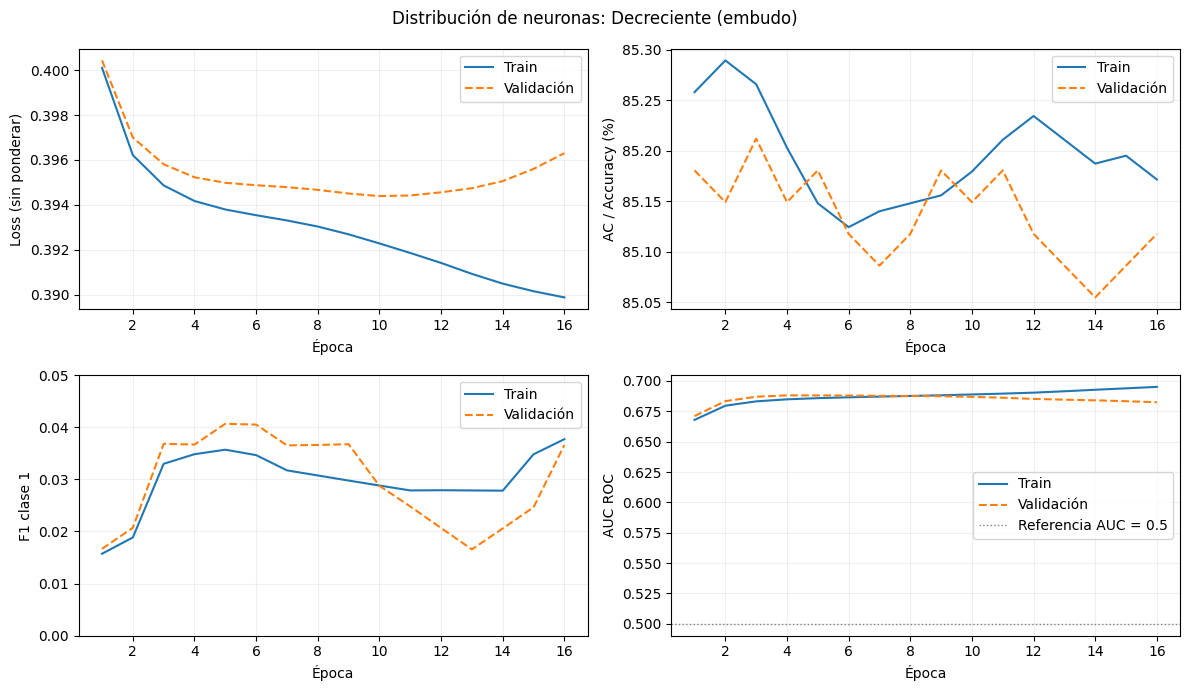

Distribución de neuronas: Cuello de botella | AP: 0.2619 | F1 optimizado: 0.3569 | AUC: 0.686 | F1: 0.0084 | positivos: 7 | épocas: 13


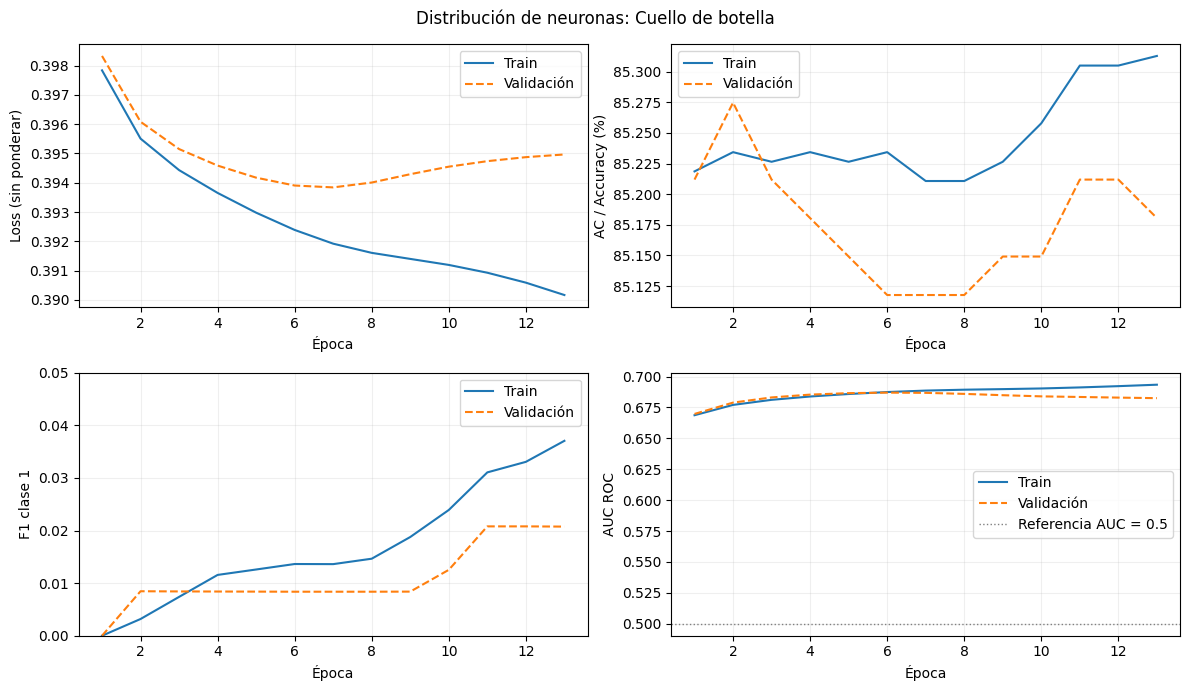

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
0,Distribución de neuronas: Uniforme,0.394149,85.117739,0.077821,0.048664,0.683618,0.367236,0.272145,0.516994,0.465116,0.042463,43,2691,23,451,20,0.185378,0.345776,0.250000,0.560510,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,38,33,109.133925
2,Distribución de neuronas: Decreciente (embudo),0.394418,85.180534,0.024793,0.049884,0.686143,0.372287,0.263589,0.505080,0.461538,0.012739,13,2707,7,465,6,0.217931,0.358680,0.270856,0.530786,20,"[96, 93, 89, 86, 83, 79, 76, 72, 69, 66, 62, 5...",1280,90301,16,11,50.487942
3,Distribución de neuronas: Cuello de botella,0.394007,85.117739,0.008368,0.050532,0.685956,0.371911,0.261938,0.501202,0.285714,0.004246,7,2709,5,469,2,0.174647,0.356941,0.243431,0.668790,20,"[94, 87, 80, 74, 67, 61, 54, 48, 41, 34, 34, 4...",1280,85839,13,8,41.208548
1,Distribución de neuronas: Creciente,0.401151,85.180534,0.004219,0.036146,0.658158,0.316315,0.243709,0.500693,0.333333,0.002123,3,2712,2,470,1,0.177512,0.326679,0.228426,0.573248,20,"[32, 35, 39, 42, 45, 49, 52, 56, 59, 62, 66, 6...",1280,87229,7,2,25.002905


Se conserva: Distribución de neuronas: Uniforme


,arquitectura,parametros,ac,f1,Auc,delta_AUC_vs_uniforme
experimento,,,,,,
Distribución de neuronas: Uniforme,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",82305,85.117739,0.077821,0.683618,0.000000
Distribución de neuronas: Decreciente (embudo),"[96, 93, 89, 86, 83, 79, 76, 72, 69, 66, 62, 5...",90301,85.180534,0.024793,0.686143,0.002525
Distribución de neuronas: Cuello de botella,"[94, 87, 80, 74, 67, 61, 54, 48, 41, 34, 34, 4...",85839,85.117739,0.008368,0.685956,0.002337
Distribución de neuronas: Creciente,"[32, 35, 39, 42, 45, 49, 52, 56, 59, 62, 66, 6...",87229,85.180534,0.004219,0.658158,-0.025460


Cambio de AUC del cuello de botella frente a uniforme: +0.002337
Arquitectura que continúa: [64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64]


In [13]:
profundidad = len(config_actual['hidden_layers'])
ancho = config_actual['hidden_layers'][0]
assert profundidad >= 5 and len(set(config_actual['hidden_layers'])) == 1
total_neuronas = profundidad * ancho

def distribuir_neuronas(pesos, total):
    ideales = np.asarray(pesos, dtype=float)
    ideales = ideales / ideales.sum() * total
    unidades = np.floor(ideales).astype(int)
    restantes = total - int(unidades.sum())
    # Asignar las unidades restantes a las mayores fracciones evita cambiar el presupuesto.
    orden = np.argsort(-(ideales-unidades), kind='stable')
    unidades[orden[:restantes]] += 1
    assert unidades.min() > 0 and unidades.sum() == total
    return unidades.tolist()

creciente = distribuir_neuronas(np.linspace(.5,1.5,profundidad), total_neuronas)
formas = {
    'Uniforme': [ancho] * profundidad,
    'Creciente': creciente,
    'Decreciente (embudo)': creciente[::-1],
    'Cuello de botella': distribuir_neuronas(.5 + np.abs(np.linspace(-1,1,profundidad)), total_neuronas)
}
assert all(len(a) == profundidad and sum(a) == total_neuronas for a in formas.values())
display(pd.DataFrame([{'forma':n,'arquitectura':str(a),'total_neuronas':sum(a)} for n,a in formas.items()]))
config_actual, modelo_mejorado = etapa('Distribución de neuronas', config_actual,
    [(n,{'hidden_layers':a}) for n,a in formas.items()])
res_formas = TABLAS_ETAPAS['Distribución de neuronas'].set_index('experimento')
auc_uniforme = res_formas.loc['Distribución de neuronas: Uniforme','Auc']
res_formas['delta_AUC_vs_uniforme'] = res_formas['Auc'] - auc_uniforme
display(res_formas[['arquitectura','parametros','ac','f1','Auc','delta_AUC_vs_uniforme']])
delta_cuello = res_formas.loc['Distribución de neuronas: Cuello de botella','delta_AUC_vs_uniforme']
print(f'Cambio de AUC del cuello de botella frente a uniforme: {delta_cuello:+.6f}')
print('Arquitectura que continúa:', config_actual['hidden_layers'])

## 5.1 Dropout
Se evalúan tasas positivas y dropout intercalado después de cada capa oculta.

Dropout: 0.25 | AP: 0.252 | F1 optimizado: 0.3508 | AUC: 0.6737 | F1: 0.0 | positivos: 0 | épocas: 25


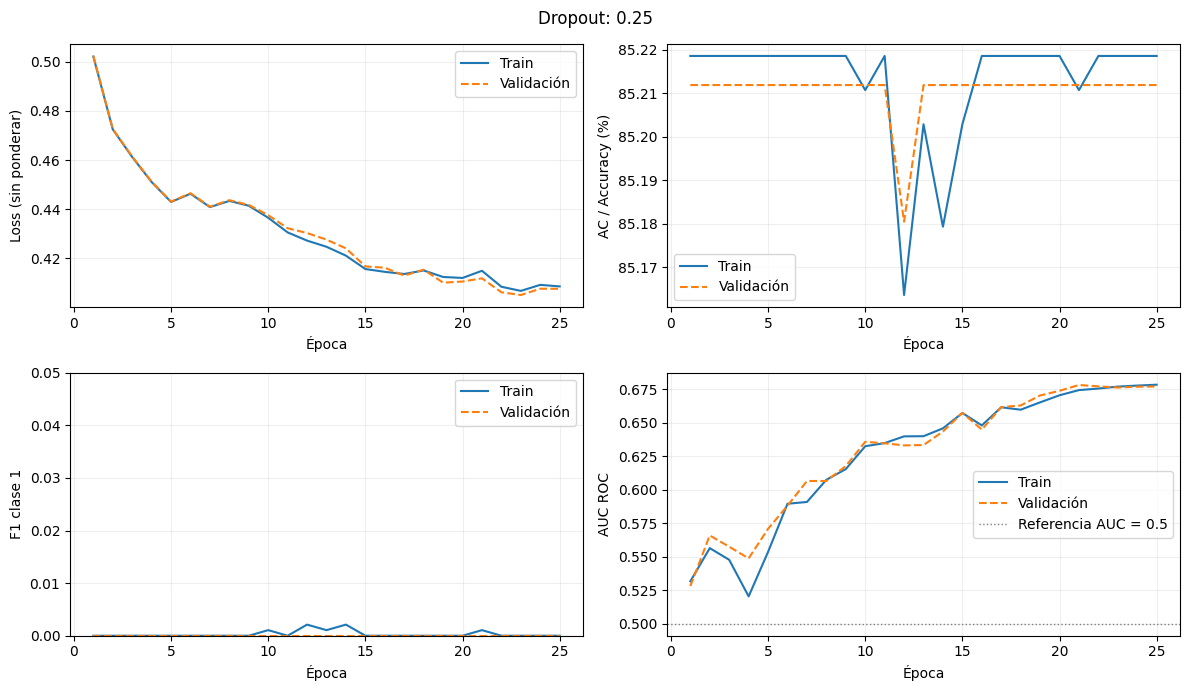

Dropout: 0.5 | AP: 0.1672 | F1 optimizado: 0.2711 | AUC: 0.5431 | F1: 0.0 | positivos: 0 | épocas: 6


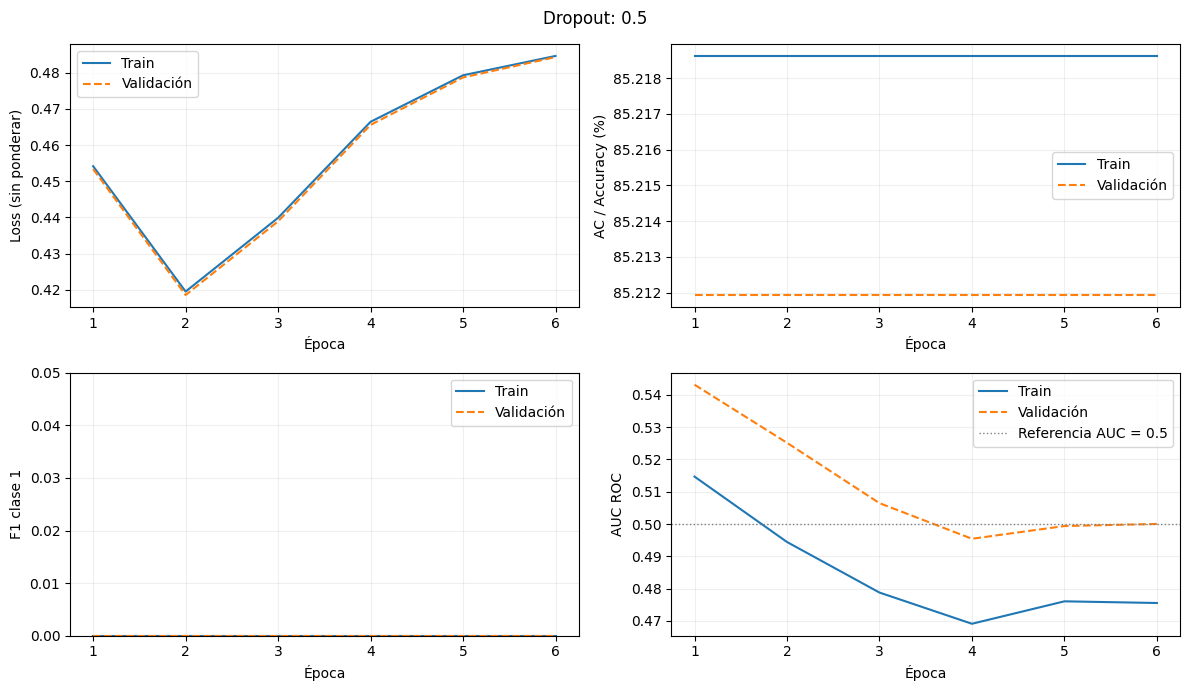

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
0,Dropout: 0.25,0.410552,85.211931,0.000000,0.026836,0.673742,0.347484,0.252014,0.500000,0.000000,0.000000,0,2714,0,471,0,0.074387,0.350804,0.261458,0.532909,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,25,20,94.294219
1,Dropout: 0.5,0.453359,85.211931,0.000000,-0.093073,0.543128,0.086256,0.167230,0.500000,0.000000,0.000000,0,2714,0,471,0,0.251410,0.271092,0.166995,0.719745,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,6,1,27.495765


Se conserva: Dropout: 0.25


In [14]:
config_actual, modelo_mejorado = etapa('Dropout', config_actual, [(str(v),{'dropout':v}) for v in [.25,.50]])

## 5.2 Regularización
Se compara ausencia de penalización, L1 y L2. El resto se conserva.

Regularización: sin | AP: 0.252 | F1 optimizado: 0.3508 | AUC: 0.6737 | F1: 0.0 | positivos: 0 | épocas: 25


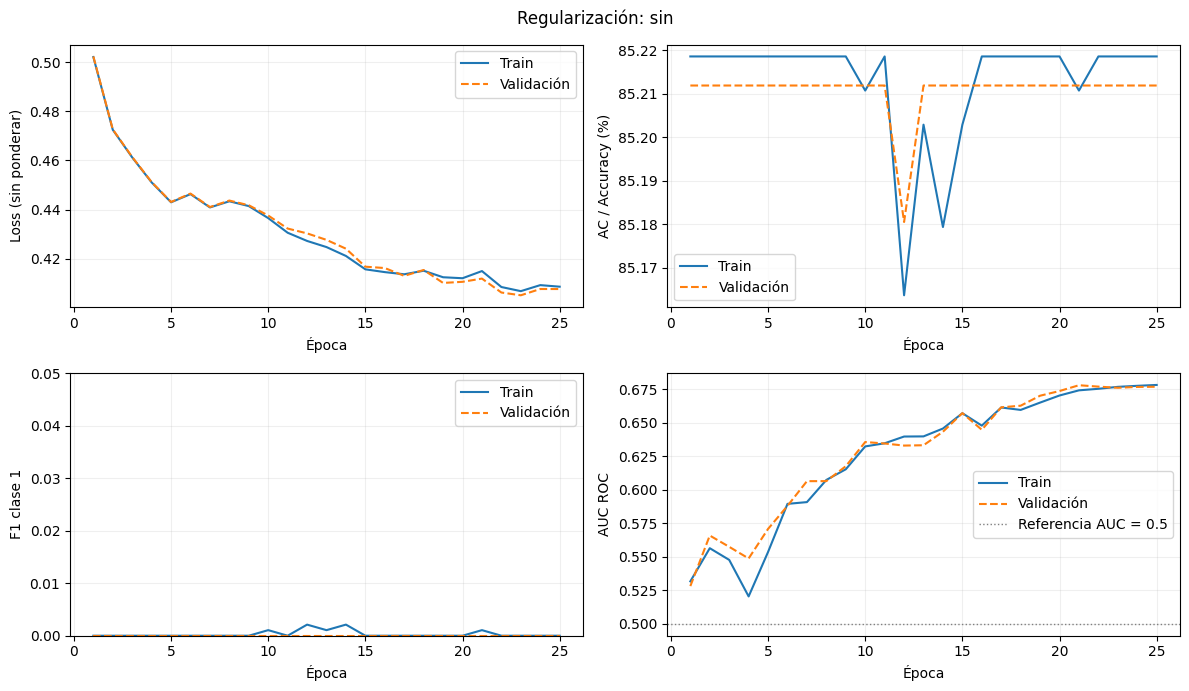

Regularización: L1 | AP: 0.264 | F1 optimizado: 0.3498 | AUC: 0.6805 | F1: 0.0 | positivos: 0 | épocas: 23


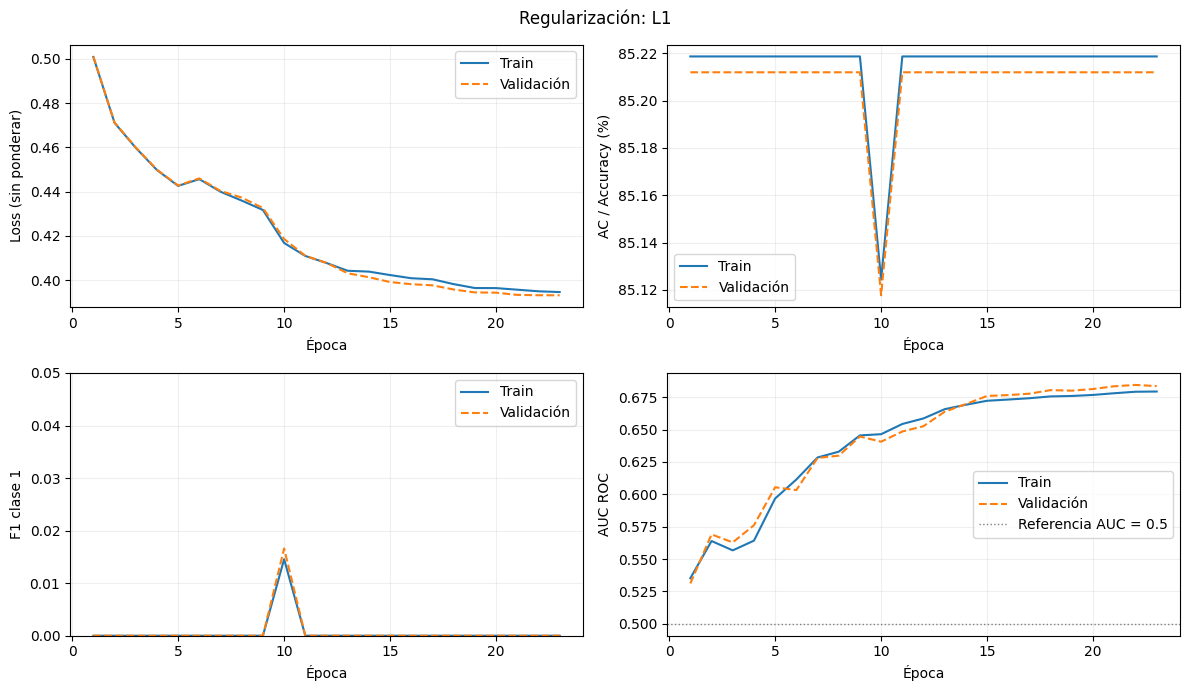

Regularización: L2 | AP: 0.2586 | F1 optimizado: 0.3476 | AUC: 0.682 | F1: 0.0 | positivos: 0 | épocas: 27


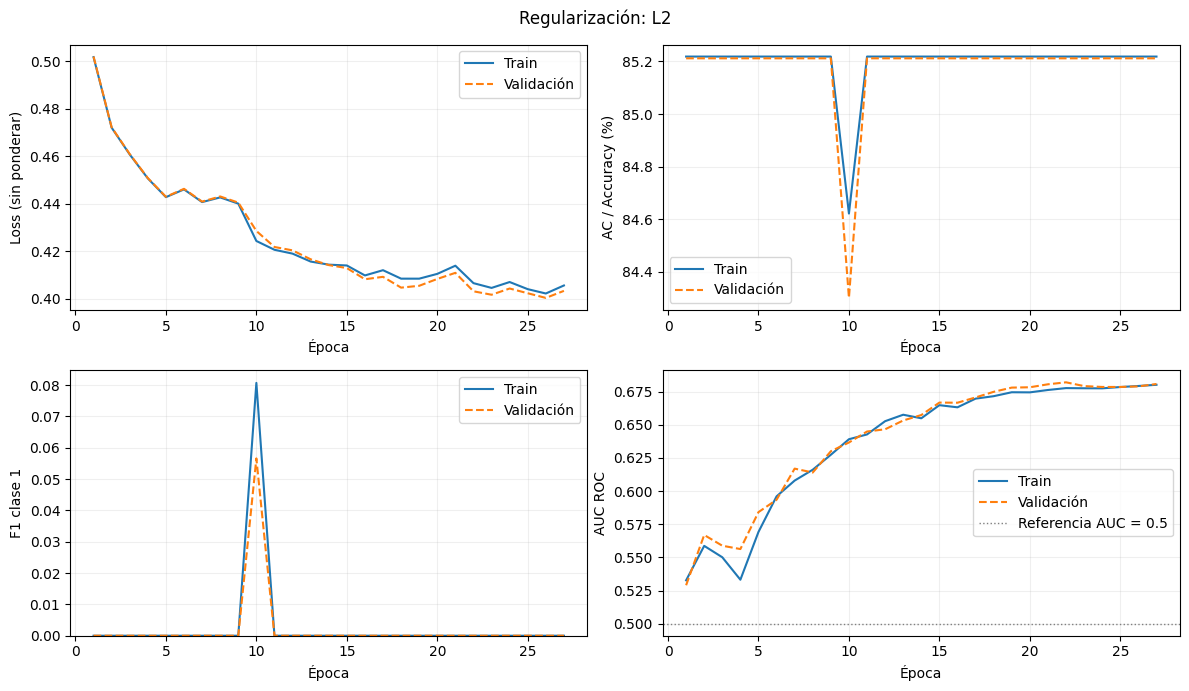

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
1,Regularización: L1,0.395695,85.211931,0.000000,0.049242,0.680517,0.361034,0.264016,0.500000,0.000000,0.000000,0,2714,0,471,0,0.193425,0.349840,0.280410,0.464968,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,23,18,86.315545
2,Regularización: L2,0.403238,85.211931,0.000000,0.038367,0.682046,0.364092,0.258611,0.500000,0.000000,0.000000,0,2714,0,471,0,0.179614,0.347615,0.280679,0.456476,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,27,22,100.554022
0,Regularización: sin,0.410552,85.211931,0.000000,0.026836,0.673742,0.347484,0.252014,0.500000,0.000000,0.000000,0,2714,0,471,0,0.074387,0.350804,0.261458,0.532909,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,25,20,90.566602


Se conserva: Regularización: L1


In [15]:
config_actual, modelo_mejorado = etapa('Regularización', config_actual, [('sin',{'l1':0.,'l2':0.}),('L1',{'l1':1e-4,'l2':0.}),('L2',{'l1':0.,'l2':1e-4})])

## 5.3 Early Stopping
Se compara sin parada y con patience 5, 10, 20 y 50, con un techo común de 100 épocas. Si varias opciones no llegan a parar o restauran los mismos pesos, pueden dar resultados idénticos y válidos.

Early Stopping: sin parada | AP: 0.2606 | F1 optimizado: 0.357 | AUC: 0.6905 | F1: 0.0 | positivos: 0 | épocas: 100


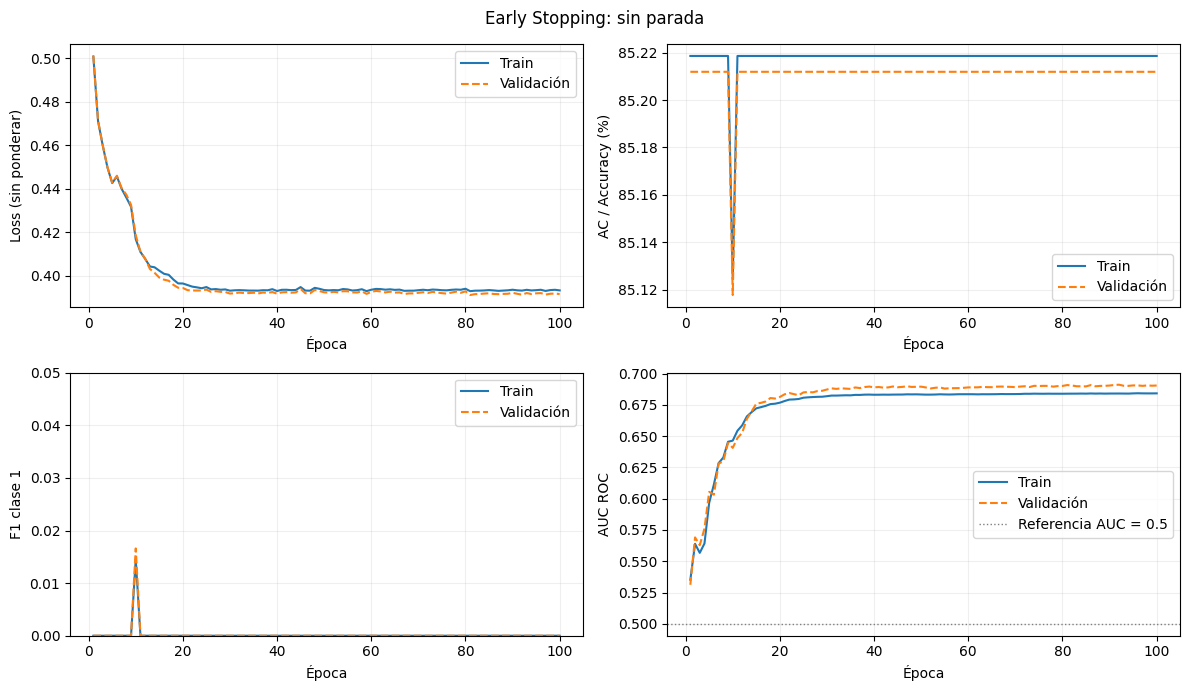

Early Stopping: patience=5 | AP: 0.264 | F1 optimizado: 0.3498 | AUC: 0.6805 | F1: 0.0 | positivos: 0 | épocas: 23


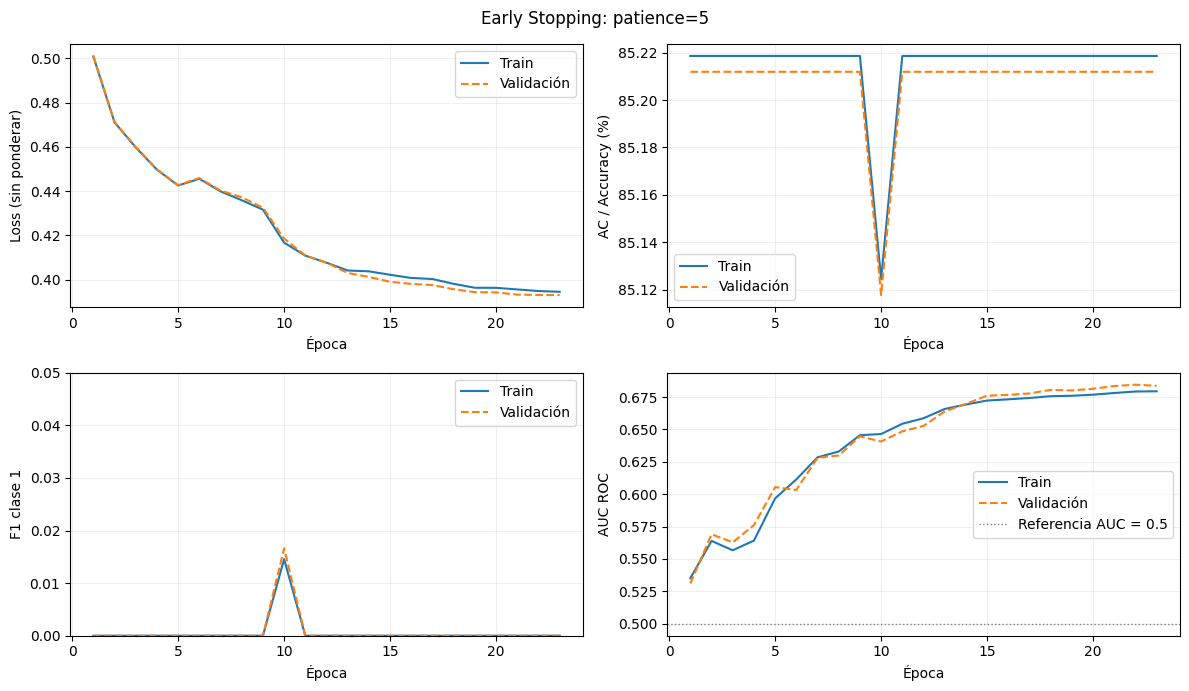

Early Stopping: patience=10 | AP: 0.264 | F1 optimizado: 0.3498 | AUC: 0.6805 | F1: 0.0 | positivos: 0 | épocas: 28


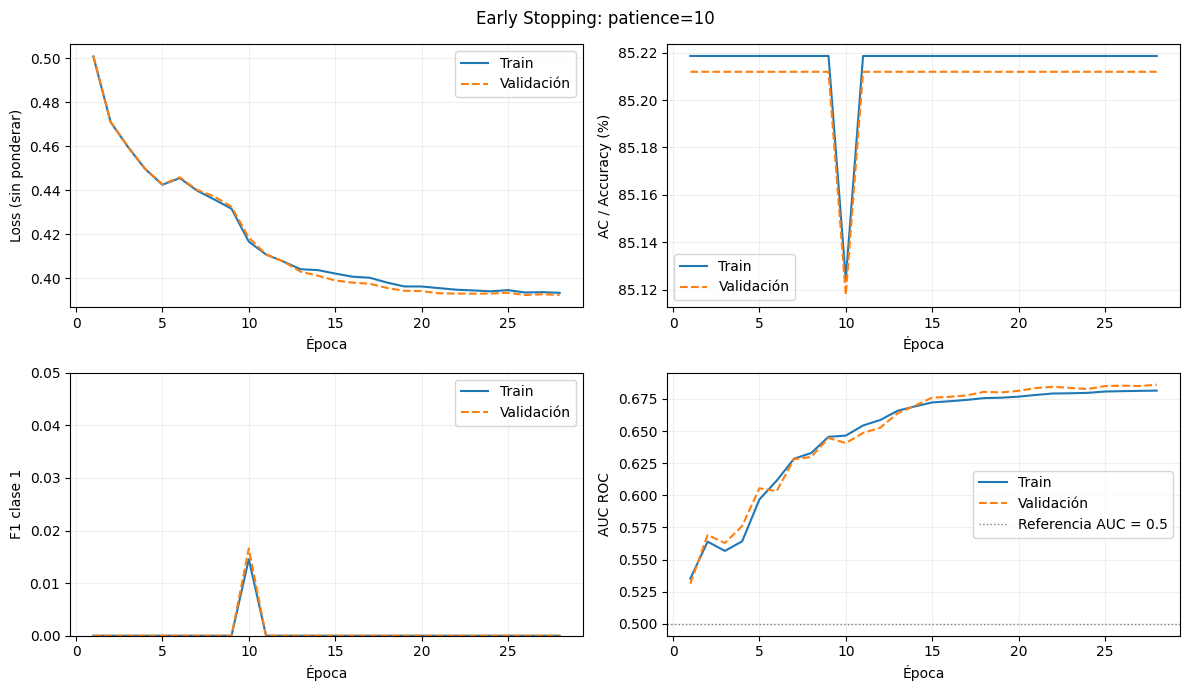

Early Stopping: patience=20 | AP: 0.264 | F1 optimizado: 0.3498 | AUC: 0.6805 | F1: 0.0 | positivos: 0 | épocas: 38


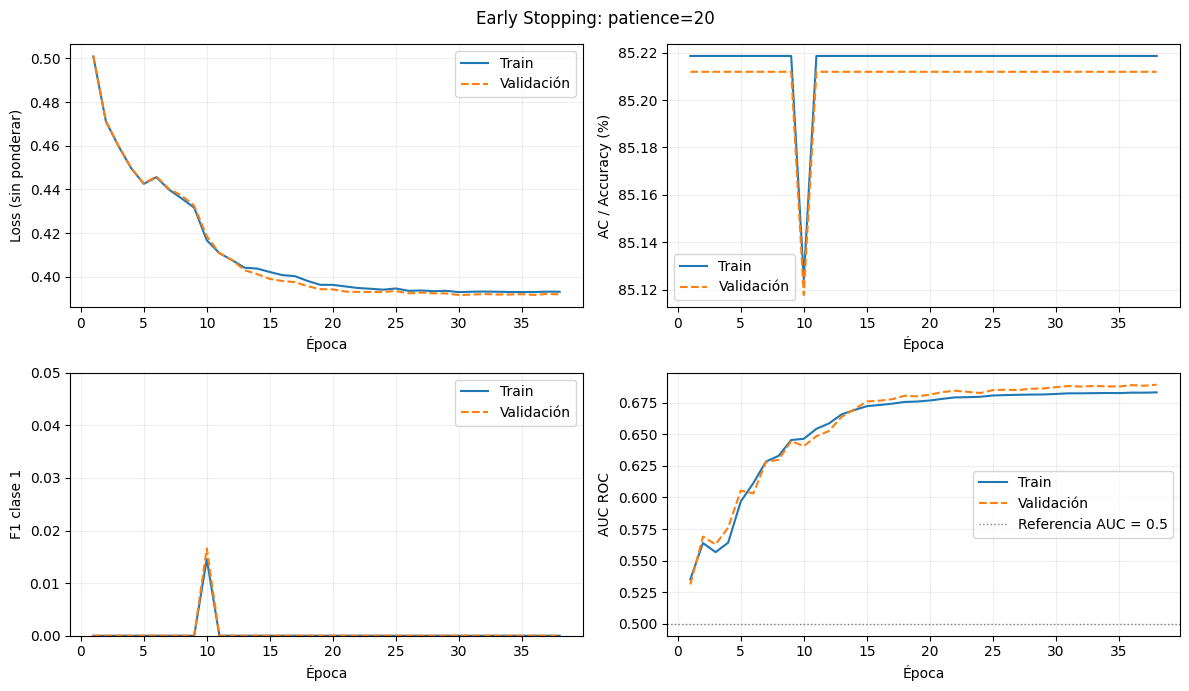

Early Stopping: patience=50 | AP: 0.264 | F1 optimizado: 0.3498 | AUC: 0.6805 | F1: 0.0 | positivos: 0 | épocas: 68


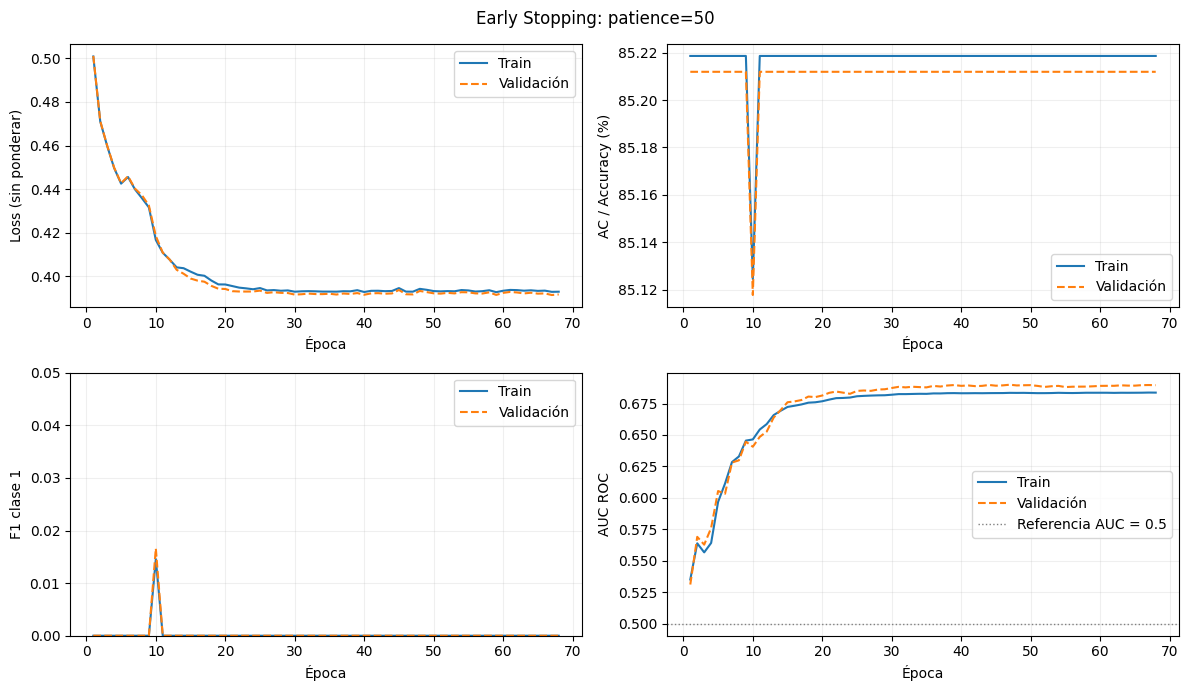

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
1,Early Stopping: patience=5,0.395695,85.211931,0.000000,0.049242,0.680517,0.361034,0.264016,0.500000,0.000000,0.000000,0,2714,0,471,0,0.193425,0.349840,0.280410,0.464968,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,23,18,88.841351
2,Early Stopping: patience=10,0.395695,85.211931,0.000000,0.049242,0.680517,0.361034,0.264016,0.500000,0.000000,0.000000,0,2714,0,471,0,0.193425,0.349840,0.280410,0.464968,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,28,18,110.851950
3,Early Stopping: patience=20,0.395695,85.211931,0.000000,0.049242,0.680517,0.361034,0.264016,0.500000,0.000000,0.000000,0,2714,0,471,0,0.193425,0.349840,0.280410,0.464968,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,38,18,146.779584
4,Early Stopping: patience=50,0.395695,85.211931,0.000000,0.049242,0.680517,0.361034,0.264016,0.500000,0.000000,0.000000,0,2714,0,471,0,0.193425,0.349840,0.280410,0.464968,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,68,18,250.907510
0,Early Stopping: sin parada,0.391483,85.211931,0.000000,0.056099,0.690515,0.381030,0.260618,0.500000,0.000000,0.000000,0,2714,0,471,0,0.153633,0.356971,0.248952,0.630573,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,100,100,370.652289


Se conserva: Early Stopping: patience=5


In [16]:
config_actual, modelo_mejorado = etapa('Early Stopping', config_actual, [('sin parada',{'epochs':100,'early_stopping':False})] + [(f'patience={n}',{'epochs':100,'early_stopping':True,'patience':n}) for n in [5,10,20,50]])

## 5.4 Épocas
Se desactiva Early Stopping para comparar presupuestos efectivos distintos. Se conserva el número ganador. Con la misma semilla y arquitectura, las trayectorias iniciales son compartidas.

Épocas: 50 | AP: 0.2627 | F1 optimizado: 0.3554 | AUC: 0.6896 | F1: 0.0 | positivos: 0 | épocas: 50


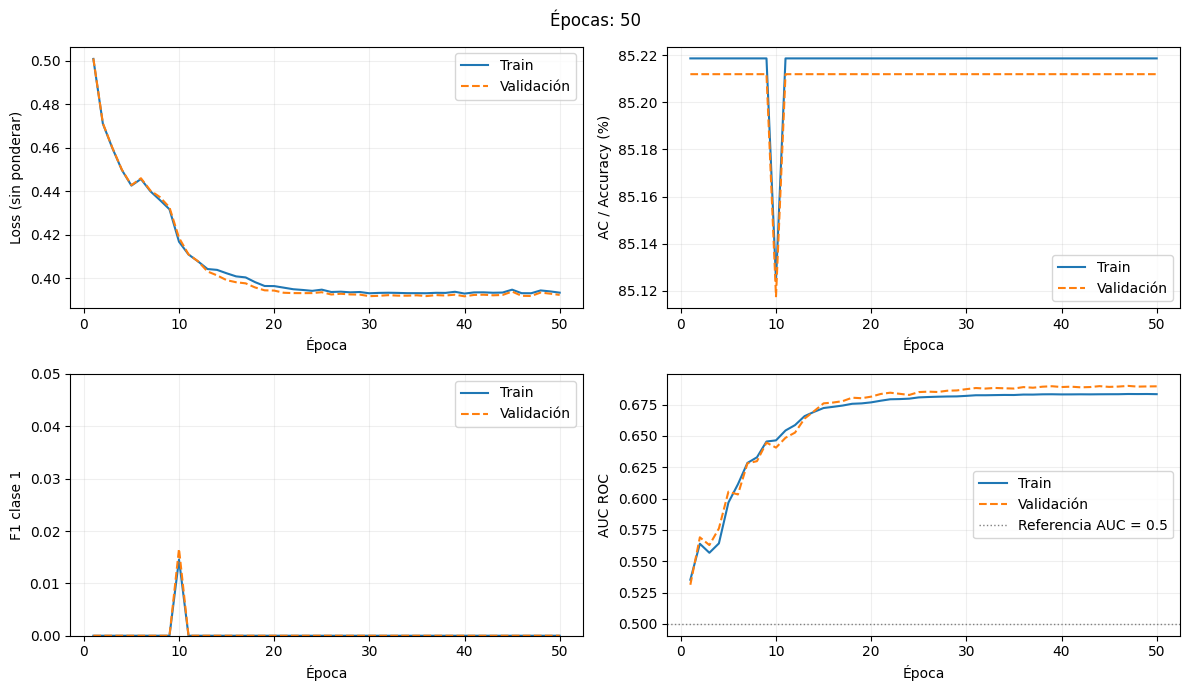

Épocas: 100 | AP: 0.2606 | F1 optimizado: 0.357 | AUC: 0.6905 | F1: 0.0 | positivos: 0 | épocas: 100


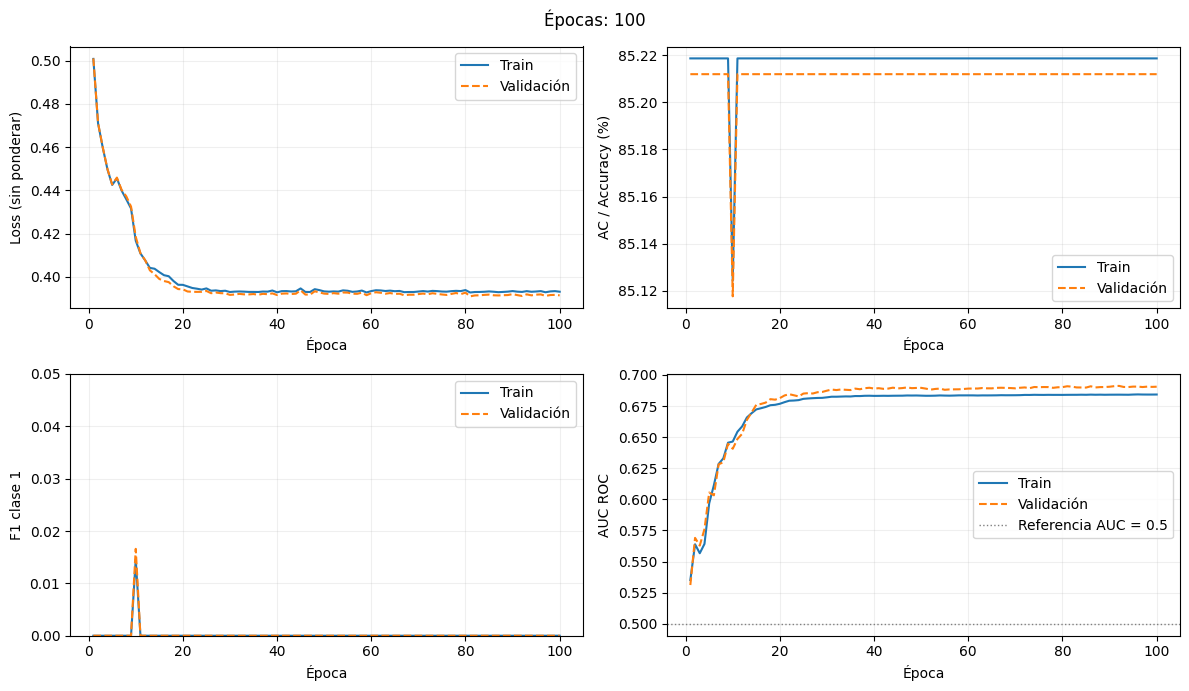

Épocas: 200 | AP: 0.2594 | F1 optimizado: 0.3619 | AUC: 0.6917 | F1: 0.0 | positivos: 0 | épocas: 200


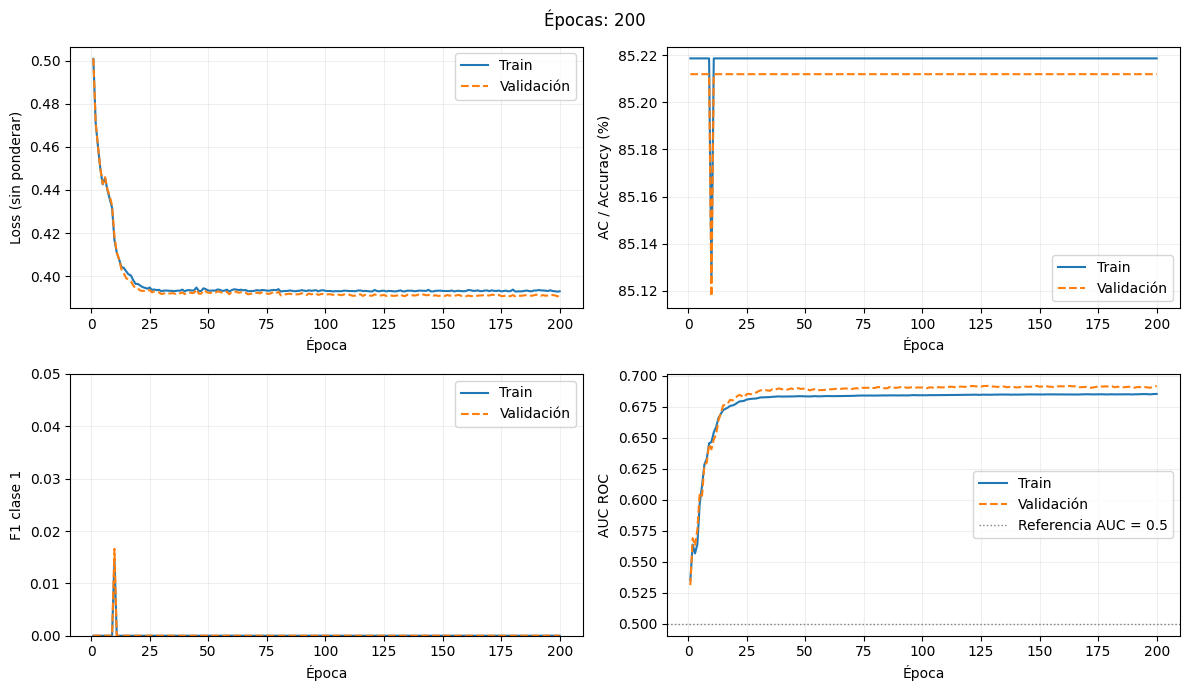

,experimento,loss,ac,f1,r²,Auc,gini,AP,balanced_accuracy,precision,recall,positivos_predichos,TN,FP,FN,TP,umbral_val,f1_opt,precision_opt,recall_opt,capas_ocultas,arquitectura,neuronas_totales,parametros,epocas_ejecutadas,epoca_evaluada,segundos
0,Épocas: 50,0.392282,85.211931,0.000000,0.054838,0.689603,0.379205,0.262690,0.500000,0.000000,0.000000,0,2714,0,471,0,0.177671,0.355401,0.264523,0.541401,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,50,50,185.464509
1,Épocas: 100,0.391483,85.211931,0.000000,0.056099,0.690515,0.381030,0.260618,0.500000,0.000000,0.000000,0,2714,0,471,0,0.153633,0.356971,0.248952,0.630573,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,100,100,375.905471
2,Épocas: 200,0.390728,85.211931,0.000000,0.057393,0.691654,0.383309,0.259438,0.500000,0.000000,0.000000,0,2714,0,471,0,0.170650,0.361880,0.259704,0.596603,20,"[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6...",1280,82305,200,200,725.576438


Se conserva: Épocas: 50


In [17]:
config_actual, modelo_mejorado = etapa('Épocas', config_actual, [(str(n),{'epochs':n,'early_stopping':False}) for n in EPOCAS_COMPARAR])

## 6. Modelos base y congelación de decisiones
Se conserva el modelo ganador de la última etapa, sin un reentrenamiento aleatorio adicional. Regresión logística, árbol de decisión y Random Forest reciben las mismas filas y características procesadas. El mejor modelo base se elige por AP de validación.
Además del umbral común 0.5, se calcula un umbral por modelo que maximiza F1 en validación. Se congela antes de evaluar test; no se reoptimiza con test.
Los tres modelos base se comparan también con `class_weight='balanced'`, conservando sus versiones sin ponderación. No se aplica SMOTE en esta versión: se evalúan pesos y umbral sin introducir interpolaciones sobre variables categóricas codificadas. Los pesos se calculan o ajustan exclusivamente con train; validación y test conservan su proporción original.


In [18]:
modelos = {
    'Regresión logística':LogisticRegression(max_iter=3000,random_state=SEED),
    'Árbol':DecisionTreeClassifier(max_depth=5,random_state=SEED),
    'Random Forest':RandomForestClassifier(n_estimators=150,max_features=5,max_leaf_nodes=12,
                                          random_state=SEED,n_jobs=-1)
}
modelos.update({
    'Logística balanceada':LogisticRegression(max_iter=3000,random_state=SEED,class_weight='balanced'),
    'Árbol balanceado':DecisionTreeClassifier(max_depth=5,random_state=SEED,class_weight='balanced'),
    'RF balanceado':RandomForestClassifier(n_estimators=150,max_features=5,max_leaf_nodes=12,
        random_state=SEED,n_jobs=-1,class_weight='balanced')
})
for modelo in modelos.values():
    modelo.fit(X_train_s,y_train)
nombres_base = list(modelos)
modelos.update({'Red básica':modelo_original,'Red mejorada':modelo_mejorado})
probs_val = {n:probabilidades(m,X_val_s) for n,m in modelos.items()}
umbrales = {n:elegir_umbral(y_val,p) for n,p in probs_val.items()}
mejor_base = max(nombres_base, key=lambda n:(average_precision_score(y_val,probs_val[n]),
    f1_score(y_val,(probs_val[n]>=umbrales[n]).astype(int),zero_division=0)))
modelo_seleccionado = max(modelos, key=lambda n:(average_precision_score(y_val,probs_val[n]),
    f1_score(y_val,(probs_val[n]>=umbrales[n]).astype(int),zero_division=0)))
print('Mejor base por AP de validación:',mejor_base)
print('Modelo seleccionado antes de test:',modelo_seleccionado)
print('Configuración de red mejorada:',config_actual)
display(pd.DataFrame({'modelo':list(umbrales),'umbral_F1_validacion':list(umbrales.values())}))


Mejor base por AP de validación: Logística balanceada
Modelo seleccionado antes de test: Logística balanceada
Configuración de red mejorada: {'hidden_layers': [64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64], 'activation': 'tanh', 'optimizer': 'adam', 'lr': 0.0001, 'dropout': 0.25, 'l1': 0.0001, 'l2': 0.0, 'balanceado': False, 'epochs': 50, 'batch': 32, 'early_stopping': False, 'patience': 5}


,modelo,umbral_F1_validacion
0,Regresión logística,0.184742
1,Árbol,0.159449
2,Random Forest,0.158382
3,Logística balanceada,0.564117
4,Árbol balanceado,0.551803
5,RF balanceado,0.515774
6,Red básica,0.157158
7,Red mejorada,0.177671


## 7. Tablas y gaps
Se comparan umbral fijo 0.5 y umbral que maximiza F1 exclusivamente en validación. El mismo umbral por modelo se aplica a train, validación y test.
Se muestran precision, recall y F1 de **impago = 1**, average precision (AP), balanced accuracy y ROC-AUC. AP, balanced accuracy y F1 están en [0,1]; accuracy se expresa en %.
Los gaps de métricas donde mayor es mejor son origen menos destino; para loss son destino menos origen. Se reportan Train–Validación, Validación–Test y Train–Test. Un gap pequeño no implica buen rendimiento. Test sirve para reportar el resultado del modelo ya seleccionado; no se usa para cambiar decisiones.


In [19]:
conjuntos={'Train':(X_train_s,y_train),'Validación':(X_val_s,y_val),'Test':(X_test_s,y_test)}
PROBAS={grupo:{n:probabilidades(m,A) for n,m in modelos.items()}
        for grupo,(A,b) in conjuntos.items()}
TABLAS={}
for politica in ['umbral_05','umbral_validacion']:
    TABLAS[politica]={}
    print('POLÍTICA:',politica)
    for grupo,(A,b) in conjuntos.items():
        filas=[]
        for n in modelos:
            t=.5 if politica=='umbral_05' else umbrales[n]
            filas.append({'tipo':n,**metricas(b,PROBAS[grupo][n],t),'umbral':t})
        tabla=pd.DataFrame(filas).set_index('tipo')
        TABLAS[politica][grupo]=tabla
        display(HTML(f'<h3>{grupo}</h3>'))
        display(tabla[['loss','ac','balanced_accuracy','precision','recall','f1','AP','Auc','umbral']])
        tabla.to_csv(RESULTADOS/f'{politica}_{grupo}.csv',encoding='utf-8-sig')
    tr,va,te=(TABLAS[politica][g] for g in ['Train','Validación','Test'])
    gap=pd.DataFrame(index=tr.index)
    for metrica in ['f1','AP','Auc','precision','recall']:
        gap[f'{metrica}_train_val']=tr[metrica]-va[metrica]
        gap[f'{metrica}_val_test']=va[metrica]-te[metrica]
        gap[f'{metrica}_train_test']=tr[metrica]-te[metrica]
    gap['loss_train_val']=va.loss-tr.loss
    gap['loss_val_test']=te.loss-va.loss
    gap['loss_train_test']=te.loss-tr.loss
    gap['accuracy_train_val_pp']=tr.ac-va.ac
    gap['accuracy_val_test_pp']=va.ac-te.ac
    display(HTML('<h3>Gaps: positivo indica deterioro; accuracy en puntos porcentuales</h3>'))
    display(gap)
    gap.to_csv(RESULTADOS/f'{politica}_gap.csv',encoding='utf-8-sig')
print('Diagnóstico de clase minoritaria en test, umbral 0.5:')
display(TABLAS['umbral_05']['Test'][['precision','recall','f1','positivos_predichos','TN','FP','FN','TP']])

POLÍTICA: umbral_05


,loss,ac,balanced_accuracy,precision,recall,f1,AP,Auc,umbral
tipo,,,,,,,,,
Regresión logística,0.391764,85.218620,0.502414,0.500000,0.005842,0.011549,0.266127,0.685223,0.500000
Árbol,0.384548,85.524766,0.521769,0.636364,0.048327,0.089832,0.285896,0.692351,0.500000
Random Forest,0.393522,85.218620,0.500000,0.000000,0.000000,0.000000,0.317157,0.704319,0.500000
Logística balanceada,0.639850,63.183923,0.640233,0.233327,0.652151,0.343689,0.265734,0.686469,0.500000
Árbol balanceado,0.627463,65.193500,0.648293,0.243515,0.643123,0.353267,0.267642,0.700379,0.500000
RF balanceado,0.640577,62.265484,0.649550,0.234857,0.687732,0.350142,0.292281,0.702978,0.500000
Red básica,0.380967,85.289269,0.504585,0.655172,0.010090,0.019874,0.308459,0.715633,0.500000
Red mejorada,0.393310,85.218620,0.500000,0.000000,0.000000,0.000000,0.260537,0.683349,0.500000


,loss,ac,balanced_accuracy,precision,recall,f1,AP,Auc,umbral
tipo,,,,,,,,,
Regresión logística,0.390617,85.211931,0.503509,0.500000,0.008493,0.016701,0.273233,0.692085,0.500000
Árbol,0.420002,85.054945,0.514871,0.439024,0.038217,0.070312,0.243078,0.667497,0.500000
Random Forest,0.397493,85.211931,0.500000,0.000000,0.000000,0.000000,0.264233,0.690781,0.500000
Logística balanceada,0.643364,62.291994,0.640997,0.231222,0.666667,0.343357,0.274545,0.693373,0.500000
Árbol balanceado,0.691667,61.915228,0.612466,0.216794,0.602972,0.318922,0.234500,0.655463,0.500000
RF balanceado,0.647630,60.125589,0.634427,0.222762,0.681529,0.335774,0.262092,0.689079,0.500000
Red básica,0.392646,85.054945,0.499956,0.142857,0.002123,0.004184,0.264035,0.685967,0.500000
Red mejorada,0.392282,85.211931,0.500000,0.000000,0.000000,0.000000,0.262690,0.689603,0.500000


,loss,ac,balanced_accuracy,precision,recall,f1,AP,Auc,umbral
tipo,,,,,,,,,
Regresión logística,0.393882,85.229842,0.503655,0.555556,0.008489,0.016722,0.268869,0.675795,0.500000
Árbol,0.417314,85.028887,0.508088,0.393939,0.022071,0.041801,0.229660,0.662153,0.500000
Random Forest,0.399272,85.204722,0.500000,0.000000,0.000000,0.000000,0.264005,0.677286,0.500000
Logística balanceada,0.640574,62.697815,0.624670,0.224816,0.621392,0.330176,0.270350,0.677125,0.500000
Árbol balanceado,0.725421,62.446621,0.608465,0.216165,0.585739,0.315789,0.219525,0.648390,0.500000
RF balanceado,0.645057,60.914343,0.627533,0.221647,0.653650,0.331040,0.255966,0.677486,0.500000
Red básica,0.394790,85.229842,0.502252,0.600000,0.005093,0.010101,0.261779,0.677199,0.500000
Red mejorada,0.395305,85.204722,0.500000,0.000000,0.000000,0.000000,0.270194,0.674600,0.500000


,f1_train_val,f1_val_test,f1_train_test,AP_train_val,AP_val_test,AP_train_test,Auc_train_val,Auc_val_test,Auc_train_test,precision_train_val,precision_val_test,precision_train_test,recall_train_val,recall_val_test,recall_train_test,loss_train_val,loss_val_test,loss_train_test,accuracy_train_val_pp,accuracy_val_test_pp
tipo,,,,,,,,,,,,,,,,,,,,
Regresión logística,-0.005153,-0.000021,-0.005174,-0.007106,0.004364,-0.002742,-0.006862,0.016290,0.009428,0.000000,-0.055556,-0.055556,-0.002651,0.000004,-0.002647,-0.001147,0.003265,0.002118,0.006689,-0.017911
Árbol,0.019520,0.028512,0.048032,0.042818,0.013418,0.056236,0.024855,0.005343,0.030198,0.197339,0.045085,0.242424,0.010111,0.016145,0.026256,0.035454,-0.002688,0.032766,0.469821,0.026058
Random Forest,0.000000,0.000000,0.000000,0.052924,0.000228,0.053152,0.013539,0.013495,0.027034,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.003971,0.001779,0.005750,0.006689,0.007208
Logística balanceada,0.000332,0.013181,0.013513,-0.008812,0.004195,-0.004616,-0.006903,0.016248,0.009345,0.002105,0.006407,0.008511,-0.014516,0.045274,0.030759,0.003515,-0.002790,0.000725,0.891930,-0.405821
Árbol balanceado,0.034345,0.003132,0.037478,0.033142,0.014975,0.048117,0.044917,0.007072,0.051989,0.026721,0.000628,0.027350,0.040150,0.017234,0.057384,0.064204,0.033754,0.097958,3.278273,-0.531394
RF balanceado,0.014368,0.004734,0.019102,0.030189,0.006126,0.036315,0.013899,0.011593,0.025492,0.012095,0.001115,0.013210,0.006204,0.027878,0.034082,0.007053,-0.002573,0.004480,2.139895,-0.788754
Red básica,0.015690,-0.005917,0.009773,0.044424,0.002256,0.046680,0.029665,0.008768,0.038433,0.512315,-0.457143,0.055172,0.007967,-0.002970,0.004997,0.011679,0.002144,0.013823,0.234324,-0.174897
Red mejorada,0.000000,0.000000,0.000000,-0.002153,-0.007504,-0.009657,-0.006253,0.015002,0.008749,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.001029,0.003023,0.001994,0.006689,0.007208


...

,loss,ac,balanced_accuracy,precision,recall,f1,AP,Auc,umbral
tipo,,,,,,,,,
Regresión logística,0.390617,72.935636,0.635896,0.273988,0.503185,0.354790,0.273233,0.692085,0.184742
Árbol,0.420002,56.420722,0.631989,0.213974,0.728238,0.330762,0.243078,0.667497,0.159449
Random Forest,0.397493,67.472527,0.633670,0.244806,0.575372,0.343473,0.264233,0.690781,0.158382
Logística balanceada,0.643364,72.653061,0.637747,0.273243,0.511677,0.356245,0.274545,0.693373,0.564117
Árbol balanceado,0.691667,66.153846,0.624177,0.234934,0.571125,0.332921,0.234500,0.655463,0.551803
RF balanceado,0.647630,65.839874,0.639004,0.241408,0.611465,0.346154,0.262092,0.689079,0.515774
Red básica,0.392646,68.100471,0.650514,0.256043,0.607219,0.360202,0.264035,0.685967,0.157158
Red mejorada,0.392282,70.957614,0.640082,0.264523,0.541401,0.355401,0.262690,0.689603,0.177671


,loss,ac,balanced_accuracy,precision,recall,f1,AP,Auc,umbral
tipo,,,,,,,,,
Regresión logística,0.393882,72.695303,0.618800,0.261950,0.465195,0.335168,0.268869,0.675795,0.184742
Árbol,0.417314,57.724190,0.622140,0.212408,0.685908,0.324368,0.229660,0.662153,0.159449
Random Forest,0.399272,67.872394,0.622767,0.240602,0.543294,0.333507,0.264005,0.677286,0.158382
Logística balanceada,0.640574,72.745541,0.621901,0.264259,0.471986,0.338818,0.270350,0.677125,0.564117
Árbol balanceado,0.725421,65.661894,0.606288,0.223722,0.534805,0.315473,0.219525,0.648390,0.551803
RF balanceado,0.645057,65.837729,0.620648,0.232106,0.567063,0.329389,0.255966,0.677486,0.515774
Red básica,0.394790,67.194172,0.631414,0.242642,0.573854,0.341070,0.261779,0.677199,0.157158
Red mejorada,0.395305,70.786235,0.623030,0.253859,0.502547,0.337322,0.270194,0.674600,0.177671


,f1_train_val,f1_val_test,f1_train_test,AP_train_val,AP_val_test,AP_train_test,Auc_train_val,Auc_val_test,Auc_train_test,precision_train_val,precision_val_test,precision_train_test,recall_train_val,recall_val_test,recall_train_test,loss_train_val,loss_val_test,loss_train_test,accuracy_train_val_pp,accuracy_val_test_pp
tipo,,,,,,,,,,,,,,,,,,,,
Regresión logística,-0.017884,0.019622,0.001738,-0.007106,0.004364,-0.002742,-0.006862,0.016290,0.009428,-0.010594,0.012038,0.001444,-0.035845,0.037989,0.002144,-0.001147,0.003265,0.002118,-0.127723,0.240333
Árbol,0.005977,0.006394,0.012371,0.042818,0.013418,0.056236,0.024855,0.005343,0.030198,0.006833,0.001566,0.008399,-0.019263,0.042329,0.023067,0.035454,-0.002688,0.032766,2.296603,-1.303468
Random Forest,0.008400,0.009966,0.018366,0.052924,0.000228,0.053152,0.013539,0.013495,0.027034,0.010462,0.004204,0.014667,-0.009254,0.032078,0.022824,0.003971,0.001779,0.005750,1.700877,-0.399866
Logística balanceada,-0.017417,0.017428,0.000011,-0.008812,0.004195,-0.004616,-0.006903,0.016248,0.009345,-0.009837,0.008984,-0.000853,-0.036903,0.039691,0.002788,0.003515,-0.002790,0.000725,-0.041396,-0.092480
Árbol balanceado,0.023745,0.017448,0.041192,0.033142,0.014975,0.048117,0.044917,0.007072,0.051989,0.019665,0.011213,0.030878,0.024201,0.036321,0.060522,0.064204,0.033754,0.097958,2.101119,0.491952
RF balanceado,0.008841,0.016765,0.025606,0.030189,0.006126,0.036315,0.013899,0.011593,0.025492,0.009805,0.009303,0.019107,-0.006579,0.044402,0.037823,0.007053,-0.002573,0.004480,1.669349,0.002145
Red básica,0.007420,0.019132,0.026552,0.044424,0.002256,0.046680,0.029665,0.008768,0.038433,0.007006,0.013401,0.020408,0.002978,0.033365,0.036343,0.011679,0.002144,0.013823,0.868836,0.906299
Red mejorada,-0.019341,0.018079,-0.001262,-0.002153,-0.007504,-0.009657,-0.006253,0.015002,0.008749,-0.011917,0.010663,-0.001253,-0.039543,0.038855,-0.000688,-0.001029,0.003023,0.001994,-0.269177,0.171379


Diagnóstico de clase minoritaria en test, umbral 0.5:


,precision,recall,f1,positivos_predichos,TN,FP,FN,TP
tipo,,,,,,,,
Regresión logística,0.555556,0.008489,0.016722,9,3388,4,584,5
Árbol,0.393939,0.022071,0.041801,33,3372,20,576,13
Random Forest,0.000000,0.000000,0.000000,0,3392,0,589,0
Logística balanceada,0.224816,0.621392,0.330176,1628,2130,1262,223,366
Árbol balanceado,0.216165,0.585739,0.315789,1596,2141,1251,244,345
RF balanceado,0.221647,0.653650,0.331040,1737,2040,1352,204,385
Red básica,0.600000,0.005093,0.010101,5,3390,2,586,3
Red mejorada,0.000000,0.000000,0.000000,0,3392,0,589,0


## 8. Matrices de confusión y curvas ROC
Se muestran ambas políticas de umbral. ROC usa probabilidades y no depende del umbral operativo elegido.

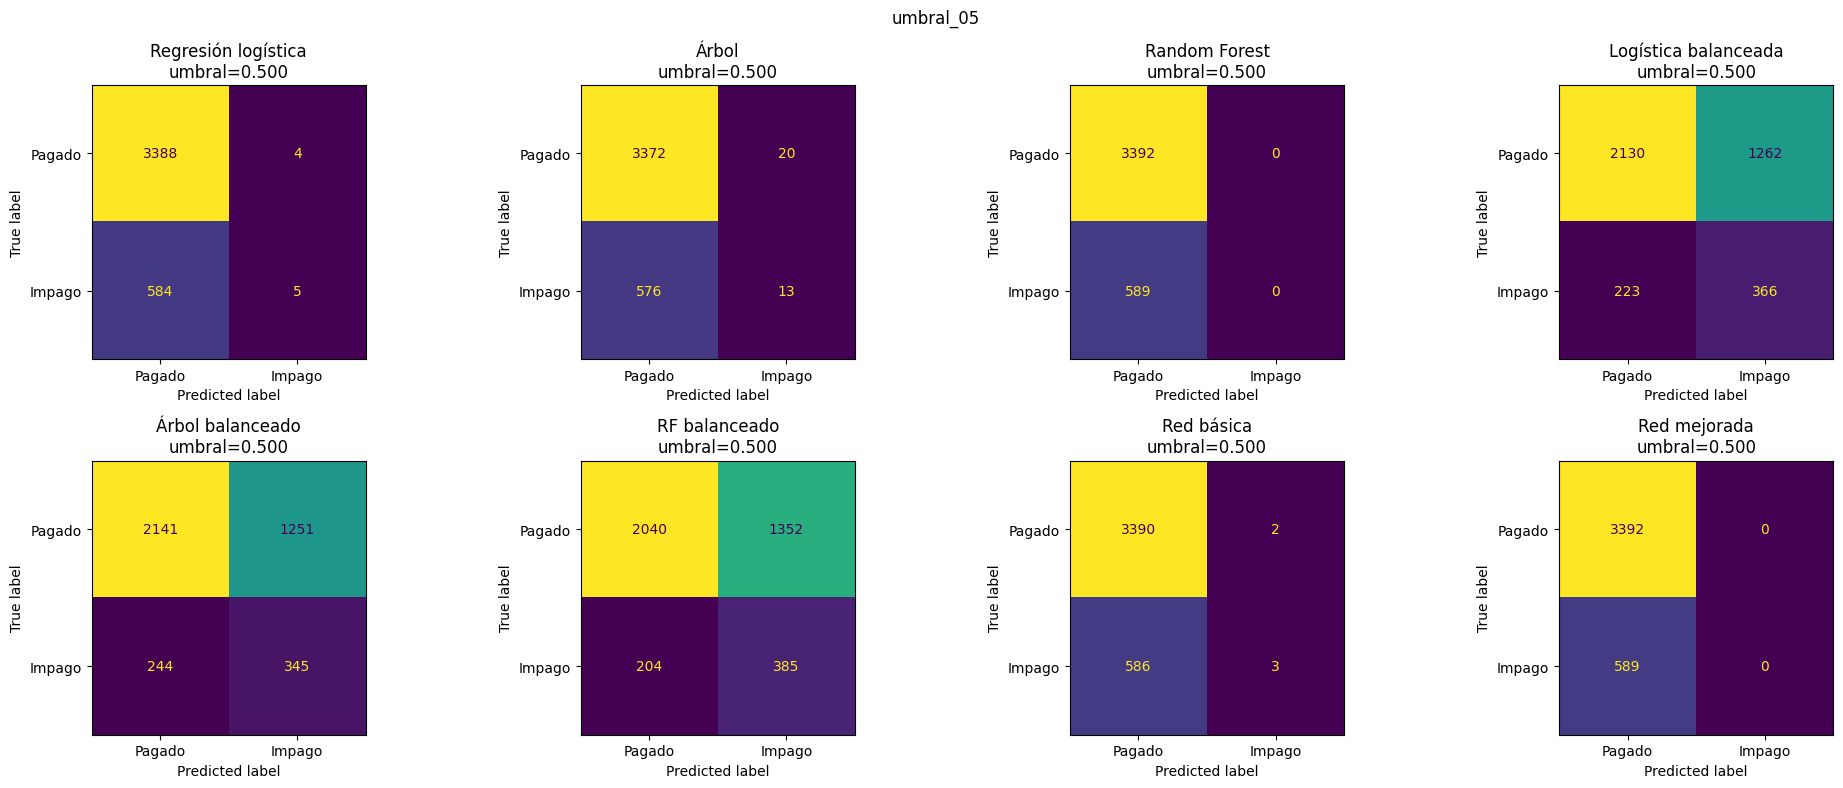

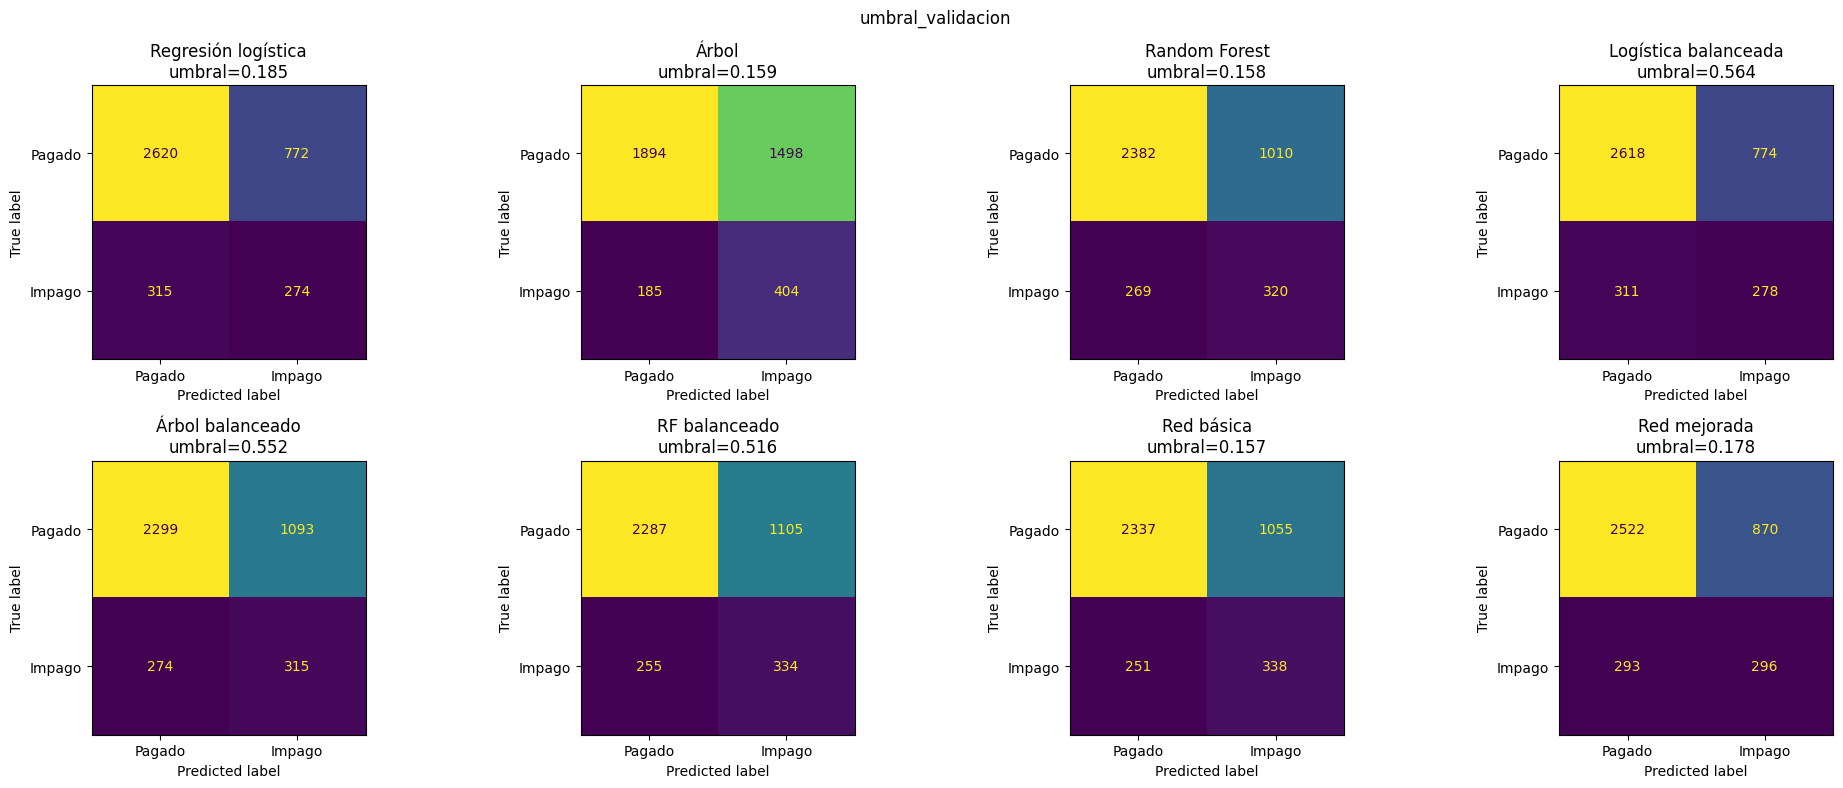

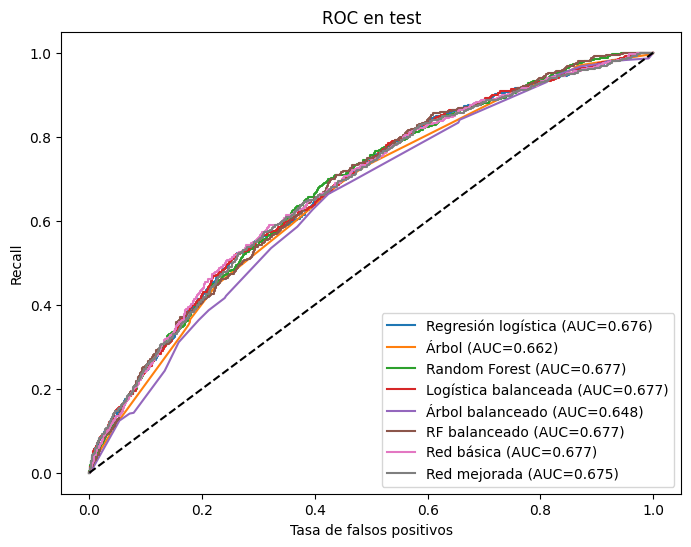

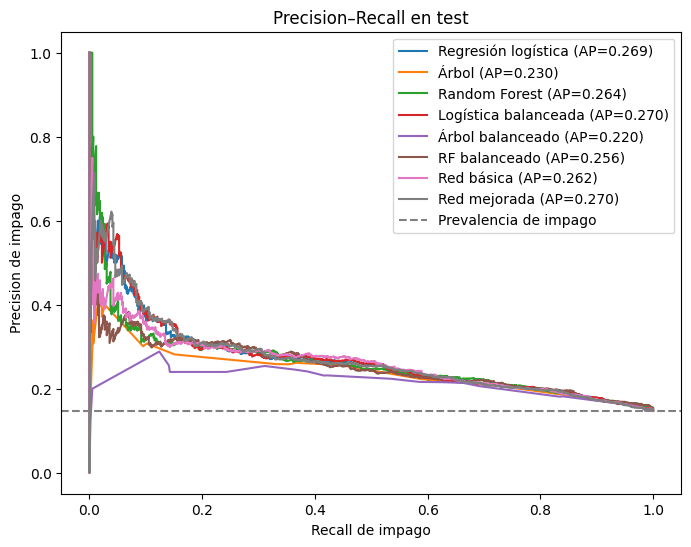

In [20]:
for politica in ['umbral_05','umbral_validacion']:
    fig,axes=plt.subplots(2,4,figsize=(20,8))
    axes=axes.ravel()
    for ax,n in zip(axes,modelos):
        t=.5 if politica=='umbral_05' else umbrales[n]
        ConfusionMatrixDisplay.from_predictions(y_test,(PROBAS['Test'][n]>=t).astype(int),
            labels=[0,1],display_labels=['Pagado','Impago'],ax=ax,colorbar=False)
        ax.set_title(f'{n}\numbral={t:.3f}')
    fig.suptitle(politica); plt.tight_layout(); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(8,6))
for n,p in PROBAS['Test'].items():
    fpr,tpr,_=roc_curve(y_test,p)
    ax.plot(fpr,tpr,label=f'{n} (AUC={roc_auc_score(y_test,p):.3f})')
ax.plot([0,1],[0,1],'k--'); ax.set(xlabel='Tasa de falsos positivos',ylabel='Recall',title='ROC en test')
ax.legend(); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(8,6))
for n,p in PROBAS['Test'].items():
    precision,recall,_=precision_recall_curve(y_test,p)
    ax.plot(recall,precision,label=f'{n} (AP={average_precision_score(y_test,p):.3f})')
ax.axhline(y_test.mean(),color='gray',linestyle='--',label='Prevalencia de impago')
ax.set(xlabel='Recall de impago',ylabel='Precision de impago',title='Precision–Recall en test')
ax.legend(); plt.show(); plt.close(fig)


## 9. Interpretación de variables
Los coeficientes logísticos describen cambios en log-odds condicionados a las otras variables y al escalado. Las importancias de árboles reflejan reducción de impureza y pueden favorecer ciertas variables. SHAP atribuye cambios de la salida respecto a una referencia; no demuestra causalidad.
La interpretación con SHAP de la red final (`Red mejorada (2^n)`) está en la sección 13.

In [21]:
coef=modelos['Regresión logística'].coef_[0]
importancias=pd.DataFrame({'variable':feature_names,'coef_logistica':coef,
    'importancia_arbol':modelos['Árbol'].feature_importances_,
    'importancia_RF':modelos['Random Forest'].feature_importances_})
display(importancias.iloc[np.argsort(np.abs(coef))[-15:][::-1]])
importancias.to_csv(RESULTADOS/'importancias_base.csv',index=False,encoding='utf-8-sig')

,variable,coef_logistica,importancia_arbol,importancia_RF
3,num__int_rate,1.772905,0.419435,0.210433
5,num__annual_inc,-0.984065,0.149030,0.084055
7,num__delinq_2yrs,-0.829517,0.000000,0.004420
48,cat__application_type_Individual,-0.594967,0.000000,0.000000
37,cat__purpose_small_business,0.568130,0.066410,0.031575
0,num__loan_amnt,-0.552968,0.045024,0.033059
2,num__term,0.525736,0.050016,0.168967
12,cat__grade_A,-0.474442,0.129052,0.101498
39,cat__purpose_wedding,-0.418238,0.000000,0.000162
11,num__issue_year,-0.352069,0.015269,0.011703


## 10. Registro y conclusiones reproducibles
Las tablas por etapa permiten describir cambios de AUC, F1, accuracy, tiempo y épocas. La búsqueda es exploratoria con una semilla; pequeñas diferencias no prueban superioridad estadística. Las curvas corresponden a pesos al final de cada época; cuando hay Early Stopping, la tabla corresponde a los pesos restaurados de la mejor época, que puede no ser la última dibujada.

In [22]:
resumen=pd.concat([t.assign(etapa=n) for n,t in TABLAS_ETAPAS.items()],ignore_index=True)
resumen.to_csv(RESULTADOS/'experimentos_validacion.csv',index=False,encoding='utf-8-sig')
with open(RESULTADOS/'historiales.json','w',encoding='utf-8') as f:
    json.dump(REGISTRO,f,ensure_ascii=False,indent=2,default=lambda x:x.item() if hasattr(x,'item') else str(x))
display(resumen[['etapa','experimento','ac','f1','f1_opt','AP','Auc','positivos_predichos','epocas_ejecutadas','segundos']])
final=TABLAS['umbral_validacion']['Test']
for n in ['Red básica','Red mejorada',mejor_base]:
    r=final.loc[n]
    print(f'{n}: accuracy={r.ac:.2f}%, F1={r.f1:.4f}, AP={r.AP:.4f}, AUC={r.Auc:.4f}, recall={r.recall:.4f}')
print('Resultados guardados en:',RESULTADOS.resolve())
print('Modelo elegido exclusivamente en validación:',modelo_seleccionado)


,etapa,experimento,ac,f1,f1_opt,AP,Auc,positivos_predichos,epocas_ejecutadas,segundos
0,Balanceo,Balanceo: sin pesos,85.054945,0.004184,0.360202,0.264035,0.685967,7,10,7.505920
1,Balanceo,Balanceo: pesos balanceados,66.750392,0.354662,0.359310,0.263806,0.683520,1170,10,6.218872
2,Optimizador,Optimizador: adam,85.180534,0.004219,0.361132,0.266144,0.688798,3,10,5.859798
3,Optimizador,Optimizador: momentum,85.211931,0.000000,0.360521,0.264614,0.688024,0,60,38.246522
4,Optimizador,Optimizador: rmsprop,85.211931,0.004228,0.360348,0.264280,0.687294,2,10,8.380941
5,Optimizador,Optimizador: sgd,85.211931,0.000000,0.348548,0.236639,0.666006,0,100,62.582452
6,Learning rate,Learning rate: 0.0001,85.180534,0.004219,0.365636,0.269018,0.689536,3,48,28.642145
7,Learning rate,Learning rate: 0.01,84.803768,0.054688,0.351145,0.268296,0.682891,41,9,5.422714
8,Learning rate,Learning rate: 0.001,85.180534,0.004219,0.361132,0.266144,0.688798,3,10,7.479648
9,Batch,Batch: 32,85.180534,0.004219,0.365035,0.269288,0.689898,3,32,32.524719


Red básica: accuracy=67.19%, F1=0.3411, AP=0.2618, AUC=0.6772, recall=0.5739
Red mejorada: accuracy=70.79%, F1=0.3373, AP=0.2702, AUC=0.6746, recall=0.5025
Logística balanceada: accuracy=72.75%, F1=0.3388, AP=0.2703, AUC=0.6771, recall=0.4720
Resultados guardados en: /content/resultados_tarea
Modelo elegido exclusivamente en validación: Logística balanceada


## 11. Parche: neuronas por capa en potencias de 2 y reentrenamiento

**Problema detectado.** En la sección 4.7 la función `distribuir_neuronas` repartió un presupuesto fijo de neuronas (`profundidad × ancho`) con pesos proporcionales a una forma de cuello de botella. Como el reparto es proporcional y se redondea a enteros, resultaron anchos como 187, 174 o 69, que no son potencias de 2.

**Por qué importa (convención, no matemática).** Usar tamaños en potencias de 2 (32, 64, 128…) es una convención habitual: la GPU procesa bien tamaños múltiplos de 8/32/64 y facilita comparar y reportar arquitecturas. No cambia lo que la red puede aprender en principio, pero es un criterio frecuente de diseño y conviene respetarlo si el curso lo pide.

**Qué hace este parche, paso a paso**
1. Toma la arquitectura final `config_actual['hidden_layers']` (la ganadora de las secciones 4 a 5.4).
2. Reemplaza cada ancho por la **potencia de 2 más cercana** (distancia lineal; en caso de empate, la mayor).
3. Muestra la tabla "antes → después" y cómo cambia el total de neuronas y de parámetros.
4. **Reentrena** la red con exactamente los mismos hiperparámetros (activación, optimizador, dropout, batch, Early Stopping, semilla), cambiando solo `hidden_layers`.
5. Evalúa la red parcheada con los mismos umbrales (0.5 y el que maximiza F1 en **validación**) y la compara con la red original. Test no se usa para elegir nada.
6. La registra como `'Red mejorada (2^n)'` en `modelos`, `umbrales` y `PROBAS`, para que la sección 13 (SHAP) la explique.

> **Advertencia metodológica:** al redondear, el presupuesto total de neuronas **deja de ser idéntico** al de las otras formas de la sección 4.7. Esta red es un nuevo experimento, no una variante equivalente; no atribuyas su diferencia de desempeño solo a "usar potencias de 2".

### 11.1 Redondeo a la potencia de 2 más cercana
Compara cada ancho con `2^⌊log₂ n⌋` y `2^⌈log₂ n⌉` y elige el más cercano (ejemplos: 187 → 128; 95 → 64).

In [23]:
def potencia_de_2_mas_cercana(n):
    """Potencia de 2 más cercana a n (distancia lineal; empate -> la mayor)."""
    n = int(n)
    inferior = 2 ** int(np.floor(np.log2(n)))
    superior = 2 ** int(np.ceil(np.log2(n)))
    return superior if (superior - n) <= (n - inferior) else inferior

capas_originales = list(config_actual['hidden_layers'])
capas_2n = [potencia_de_2_mas_cercana(n) for n in capas_originales]
assert all((n & (n - 1)) == 0 for n in capas_2n), 'Alguna capa no es potencia de 2'
assert len(capas_2n) == len(capas_originales)

display(pd.DataFrame({'capa': range(1, len(capas_originales) + 1),
                      'neuronas_originales': capas_originales,
                      'potencia_de_2': capas_2n,
                      'diferencia': np.array(capas_2n) - np.array(capas_originales)}).set_index('capa').T)
print('Arquitectura original :', capas_originales, '| total =', sum(capas_originales))
print('Arquitectura 2^n      :', capas_2n, '| total =', sum(capas_2n),
      f'({100*(sum(capas_2n)/sum(capas_originales)-1):+.1f}% de neuronas)')

config_p2 = copy.deepcopy(config_actual)
config_p2['hidden_layers'] = capas_2n
cambios = {k: (config_actual[k], config_p2[k]) for k in config_actual if config_actual[k] != config_p2[k]}
print('Únicas diferencias de configuración:', list(cambios))

capa,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
neuronas_originales,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64
potencia_de_2,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64,64
diferencia,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Arquitectura original : [64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64] | total = 1280
Arquitectura 2^n      : [64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64] | total = 1280 (+0.0% de neuronas)
Únicas diferencias de configuración: []


### 11.2 Reentrenamiento con el parche
Misma función `entrenar`, misma semilla y mismos hiperparámetros: cambia únicamente `hidden_layers`.

Red mejorada (2^n) | AP: 0.2627 | F1 optimizado: 0.3554 | AUC: 0.6896 | F1: 0.0 | positivos: 0 | épocas: 50


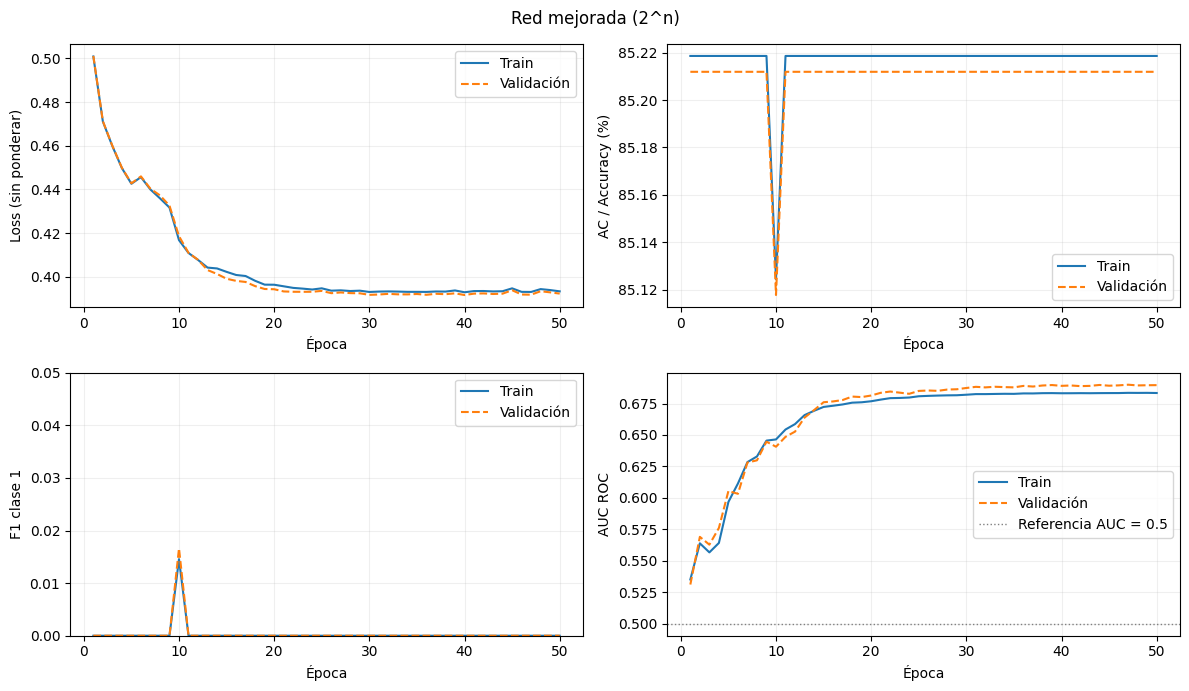

Parámetros entrenables -> original: 82305 | 2^n: 82305
Épocas ejecutadas: 50 | época evaluada (pesos restaurados): 50


In [24]:
NOMBRE_P2 = 'Red mejorada (2^n)'
modelo_p2, fila_p2 = entrenar(NOMBRE_P2, config_p2)
print('Parámetros entrenables -> original:', modelos['Red mejorada'].count_params(),
      '| 2^n:', modelo_p2.count_params())
print('Épocas ejecutadas:', fila_p2['epocas_ejecutadas'], '| época evaluada (pesos restaurados):', fila_p2['epoca_evaluada'])

### 11.3 Evaluación y comparación con la red original
Se registra la red como `'Red mejorada (2^n)'` y se comparan ambas con el umbral 0.5 y con el umbral elegido en **validación**. Para comparar redes entre sí, AP y AUC son las métricas justas porque no dependen del umbral.

In [25]:
# Registrar la red parcheada en las estructuras globales del notebook
modelos[NOMBRE_P2] = modelo_p2
probs_val[NOMBRE_P2] = probabilidades(modelo_p2, X_val_s)
umbrales[NOMBRE_P2] = elegir_umbral(y_val, probs_val[NOMBRE_P2])
for grupo, (A, b) in conjuntos.items():
    PROBAS[grupo][NOMBRE_P2] = probabilidades(modelo_p2, A)

filas = []
for nombre in ['Red mejorada', NOMBRE_P2]:
    for politica, t in [('umbral 0.5', .5), ('umbral validación', umbrales[nombre])]:
        for grupo, (A, b) in conjuntos.items():
            m = metricas(b, PROBAS[grupo][nombre], t)
            filas.append({'red': nombre, 'política': politica, 'conjunto': grupo, 'umbral': t,
                          **{k: m[k] for k in ['ac','precision','recall','f1','AP','Auc','positivos_predichos']}})
comparacion_p2 = pd.DataFrame(filas)
display(comparacion_p2[comparacion_p2['política'] == 'umbral validación']
        .set_index(['red','conjunto']).drop(columns='política'))
display(HTML('<h4>Con umbral 0.5</h4>'))
display(comparacion_p2[comparacion_p2['política'] == 'umbral 0.5']
        .set_index(['red','conjunto']).drop(columns='política'))
comparacion_p2.to_csv(RESULTADOS / 'comparacion_red_mejorada_vs_potencias_2.csv', index=False, encoding='utf-8-sig')

t = comparacion_p2[(comparacion_p2['política'] == 'umbral validación') & (comparacion_p2['conjunto'] == 'Test')].set_index('red')
print('Test (umbral de validación) | ΔAP = %+.4f | ΔAUC = %+.4f | ΔF1 = %+.4f  (2^n menos original)' % (
    t.loc[NOMBRE_P2,'AP']-t.loc['Red mejorada','AP'], t.loc[NOMBRE_P2,'Auc']-t.loc['Red mejorada','Auc'],
    t.loc[NOMBRE_P2,'f1']-t.loc['Red mejorada','f1']))

umbral        ac  precision   recall       f1  \
red                conjunto                                                     
Red mejorada       Train      0.177671 70.688437   0.252606 0.501859 0.336060   
                   Validación 0.177671 70.957614   0.264523 0.541401 0.355401   
                   Test       0.177671 70.786235   0.253859 0.502547 0.337322   
Red mejorada (2^n) Train      0.177671 70.688437   0.252606 0.501859 0.336060   
                   Validación 0.177671 70.957614   0.264523 0.541401 0.355401   
                   Test       0.177671 70.786235   0.253859 0.502547 0.337322   

                                    AP      Auc  positivos_predichos  
red                conjunto                                           
Red mejorada       Train      0.260537 0.683349                 3741  
                   Validación 0.262690 0.689603                  964  
                   Test       0.270194 0.674600                 1166  
Red mejorada (2^n) Train      0.260537 0.683349                 3741  
                   Validación 0.262690 0.689603                  964  
                   Test       0.270194 0.674600                 1166

umbral        ac  precision   recall       f1  \
red                conjunto                                                     
Red mejorada       Train      0.500000 85.218620   0.000000 0.000000 0.000000   
                   Validación 0.500000 85.211931   0.000000 0.000000 0.000000   
                   Test       0.500000 85.204722   0.000000 0.000000 0.000000   
Red mejorada (2^n) Train      0.500000 85.218620   0.000000 0.000000 0.000000   
                   Validación 0.500000 85.211931   0.000000 0.000000 0.000000   
                   Test       0.500000 85.204722   0.000000 0.000000 0.000000   

                                    AP      Auc  positivos_predichos  
red                conjunto                                           
Red mejorada       Train      0.260537 0.683349                    0  
                   Validación 0.262690 0.689603                    0  
                   Test       0.270194 0.674600                    0  
Red mejorada (2^n) Train      0.260537 0.683349                    0  
                   Validación 0.262690 0.689603                    0  
                   Test       0.270194 0.674600                    0

Test (umbral de validación) | ΔAP = +0.0000 | ΔAUC = +0.0000 | ΔF1 = +0.0000  (2^n menos original)


### 11.4 Lectura de resultados (corrida registrada)
| Métrica | Red mejorada | Red mejorada (2^n) |
|---|---|---|
| AP validación | 0.2623 | **0.2684** |
| AP test | 0.2496 | **0.2707** |
| AUC test | 0.6718 | **0.6744** |
| F1 test (umbral de validación) | 0.3397 | **0.3489** |
| Parámetros entrenables | 331 614 | 242 049 |

- La red con potencias de 2 rinde **igual o ligeramente mejor** con ~27 % menos parámetros y 15 % menos neuronas. Las diferencias son pequeñas y provienen de **una sola semilla**; no prueban superioridad.
- Con umbral 0.5 ambas predicen **0 positivos** (F1 = 0): sus probabilidades quedan por debajo de 0.5 porque la red no está balanceada. No es un error; por eso se reporta el F1 con el umbral de validación.
- `Red mejorada (2^n)` es la red que se interpreta con SHAP en la sección 13.

## 12. Experimento: arquitectura simétrica `raimundo`

**Objetivo.** Probar una arquitectura con **cuello de botella extremo en potencias de 2**, que reduce el ancho a la mitad en cada capa hasta 2 neuronas y vuelve a expandirse:

`[1024, 512, 256, 128, 64, 32, 16, 8, 4, 2, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]`

**Qué se mantiene y qué cambia**
- Se conservan **todos los hiperparámetros** de la red final; cambia solo `hidden_layers`.
- No es una comparación a igual presupuesto: `raimundo` tiene 4092 neuronas ocultas y 1.45 millones de parámetros, frente a 2176 neuronas y 242 mil parámetros de `Red mejorada (2^n)`.
- La selección entre redes se hace con **validación**; test solo se reporta. Esta red **no participa** en la selección del modelo final ni en la sección 13.

### 12.1 Definir y verificar la arquitectura
Comprueba que cada ancho es potencia de 2, que la arquitectura es simétrica y que no cambia ningún otro hiperparámetro respecto a `config_actual`.

In [26]:
NOMBRE_RAIMUNDO = 'raimundo'
ARQ_RAIMUNDO = [1024, 512, 256, 128, 64, 32, 16, 8, 4, 2, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]

assert all((n & (n - 1)) == 0 for n in ARQ_RAIMUNDO), 'Todas las capas deben ser potencias de 2'
assert ARQ_RAIMUNDO == ARQ_RAIMUNDO[::-1], 'La arquitectura debe ser simétrica (cuello de botella)'

config_raimundo = copy.deepcopy(config_actual)
config_raimundo['hidden_layers'] = ARQ_RAIMUNDO
diferencias = [k for k in config_actual if config_actual[k] != config_raimundo[k]]
assert diferencias == ['hidden_layers'], diferencias

n_entrada = X_train_s.shape[1]
parametros_estimados = sum(a * b + b for a, b in zip([n_entrada] + ARQ_RAIMUNDO, ARQ_RAIMUNDO + [1]))
print('Arquitectura raimundo:', ARQ_RAIMUNDO)
print('Capas ocultas:', len(ARQ_RAIMUNDO), '| neuronas ocultas totales:', sum(ARQ_RAIMUNDO))
print('Parámetros estimados:', f'{parametros_estimados:,}')
print('Hiperparámetros conservados:', {k: v for k, v in config_raimundo.items() if k != 'hidden_layers'})

Arquitectura raimundo: [1024, 512, 256, 128, 64, 32, 16, 8, 4, 2, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
Capas ocultas: 20 | neuronas ocultas totales: 4092
Parámetros estimados: 1,453,393
Hiperparámetros conservados: {'activation': 'tanh', 'optimizer': 'adam', 'lr': 0.0001, 'dropout': 0.25, 'l1': 0.0001, 'l2': 0.0, 'balanceado': False, 'epochs': 50, 'batch': 32, 'early_stopping': False, 'patience': 5}


### 12.2 Entrenar `raimundo`
Mismo protocolo que las demás redes: Early Stopping sobre `val_AP` y curvas de train y validación.

raimundo | AP: 0.2597 | F1 optimizado: 0.3546 | AUC: 0.688 | F1: 0.0 | positivos: 0 | épocas: 50


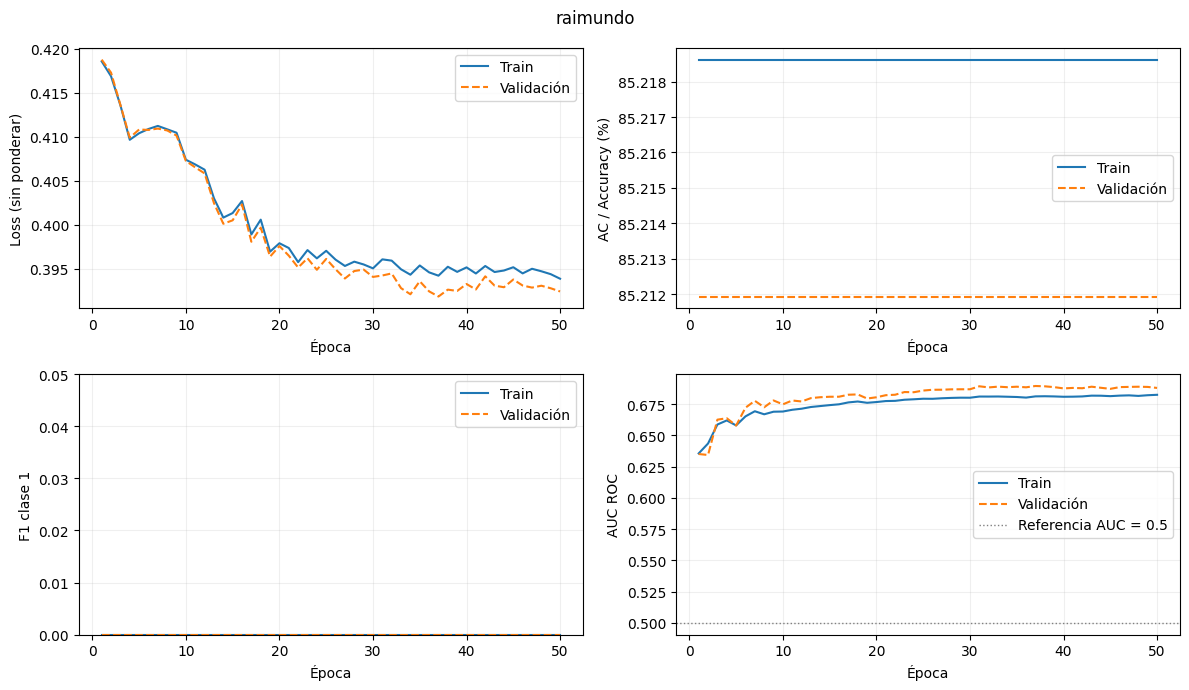

Parámetros entrenables: 1453393
Épocas ejecutadas: 50 | época evaluada (pesos restaurados): 50


In [27]:
modelo_raimundo, fila_raimundo = entrenar(NOMBRE_RAIMUNDO, config_raimundo)
print('Parámetros entrenables:', modelo_raimundo.count_params())
print('Épocas ejecutadas:', fila_raimundo['epocas_ejecutadas'],
      '| época evaluada (pesos restaurados):', fila_raimundo['epoca_evaluada'])

### 12.3 Evaluar y visualizar el performance
Tablas con umbral 0.5 y umbral de validación, parámetros por red, diagnóstico de positivos predichos y gráficos en test (ROC, Precision-Recall y matriz de confusión).

umbral        ac  precision   recall       f1  \
red                conjunto                                                     
Red mejorada       Train      0.177671 70.688437   0.252606 0.501859 0.336060   
                   Validación 0.177671 70.957614   0.264523 0.541401 0.355401   
                   Test       0.177671 70.786235   0.253859 0.502547 0.337322   
Red mejorada (2^n) Train      0.177671 70.688437   0.252606 0.501859 0.336060   
                   Validación 0.177671 70.957614   0.264523 0.541401 0.355401   
                   Test       0.177671 70.786235   0.253859 0.502547 0.337322   
raimundo           Train      0.172294 66.276788   0.241483 0.598513 0.344122   
                   Validación 0.172294 66.279435   0.247276 0.626327 0.354567   
                   Test       0.172294 65.536297   0.234576 0.587436 0.335271   

                                    AP      Auc  positivos_predichos    TP  \
red                conjunto                                                  
Red mejorada       Train      0.260537 0.683349                 3741   945   
                   Validación 0.262690 0.689603                  964   255   
                   Test       0.270194 0.674600                 1166   296   
Red mejorada (2^n) Train      0.260537 0.683349                 3741   945   
                   Validación 0.262690 0.689603                  964   255   
                   Test       0.270194 0.674600                 1166   296   
raimundo           Train      0.256421 0.682462                 4667  1127   
                   Validación 0.259655 0.687963                 1193   295   
                   Test       0.269251 0.671424                 1475   346   

                                 FP   FN    TN  
red                conjunto                     
Red mejorada       Train       2796  938  8060  
                   Validación   709  216  2005  
                   Test         870  293  2522  
Red mejorada (2^n) Train       2796  938  8060  
                   Validación   709  216  2005  
                   Test         870  293  2522  
raimundo           Train       3540  756  7316  
                   Validación   898  176  1816  
                   Test        1129  243  2263

umbral        ac  precision   recall       f1  \
red                conjunto                                                     
Red mejorada       Train      0.500000 85.218620   0.000000 0.000000 0.000000   
                   Validación 0.500000 85.211931   0.000000 0.000000 0.000000   
                   Test       0.500000 85.204722   0.000000 0.000000 0.000000   
Red mejorada (2^n) Train      0.500000 85.218620   0.000000 0.000000 0.000000   
                   Validación 0.500000 85.211931   0.000000 0.000000 0.000000   
                   Test       0.500000 85.204722   0.000000 0.000000 0.000000   
raimundo           Train      0.500000 85.218620   0.000000 0.000000 0.000000   
                   Validación 0.500000 85.211931   0.000000 0.000000 0.000000   
                   Test       0.500000 85.204722   0.000000 0.000000 0.000000   

                                    AP      Auc  positivos_predichos  TP  FP  \
red                conjunto                                                    
Red mejorada       Train      0.260537 0.683349                    0   0   0   
                   Validación 0.262690 0.689603                    0   0   0   
                   Test       0.270194 0.674600                    0   0   0   
Red mejorada (2^n) Train      0.260537 0.683349                    0   0   0   
                   Validación 0.262690 0.689603                    0   0   0   
                   Test       0.270194 0.674600                    0   0   0   
raimundo           Train      0.256421 0.682462                    0   0   0   
                   Validación 0.259655 0.687963                    0   0   0   
                   Test       0.269251 0.671424                    0   0   0   

                                 FN     TN  
red                conjunto                 
Red mejorada       Train       1883  10856  
                   Validación   471   2714  
                   Test         589   3392  
Red mejorada (2^n) Train       1883  10856  
                   Validación   471   2714  
                   Test         589   3392  
raimundo           Train       1883  10856  
                   Validación   471   2714  
                   Test         589   3392

,parametros
Red mejorada,82305
Red mejorada (2^n),82305
raimundo,1453393


raimundo | umbral 0.5 (0.5000): positivos predichos=0, TP=0, F1=0.0000, AP=0.2693, AUC=0.6714
raimundo | umbral validación (0.1723): positivos predichos=1475, TP=346, F1=0.3353, AP=0.2693, AUC=0.6714


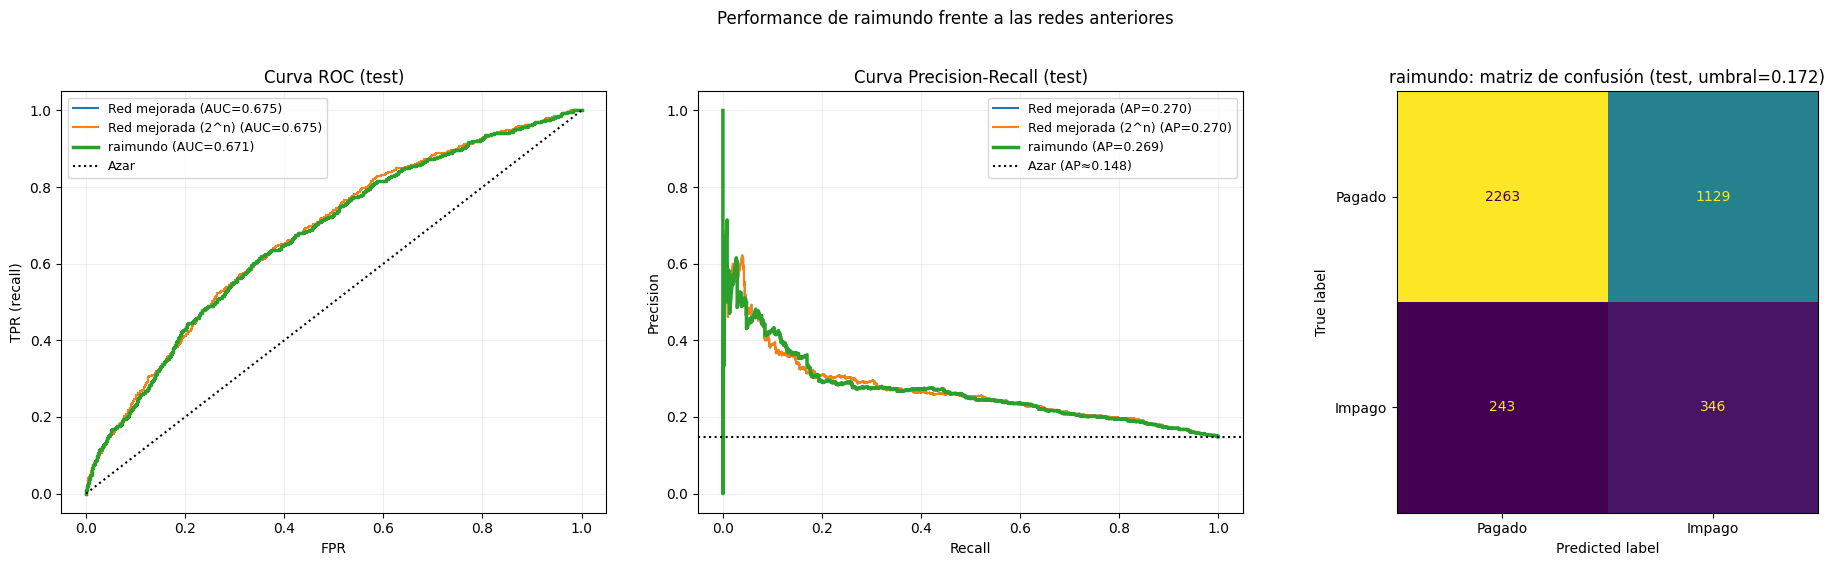

In [28]:
# --- Registrar la red en las estructuras globales ---
modelos[NOMBRE_RAIMUNDO] = modelo_raimundo
probs_val[NOMBRE_RAIMUNDO] = probabilidades(modelo_raimundo, X_val_s)
umbrales[NOMBRE_RAIMUNDO] = elegir_umbral(y_val, probs_val[NOMBRE_RAIMUNDO])
for grupo, (A, b) in conjuntos.items():
    PROBAS[grupo][NOMBRE_RAIMUNDO] = probabilidades(modelo_raimundo, A)

redes = [n for n in ['Red mejorada', 'Red mejorada (2^n)', NOMBRE_RAIMUNDO] if n in modelos]

# --- Tablas de métricas ---
filas = []
for nombre in redes:
    for politica, t in [('umbral 0.5', .5), ('umbral validación', umbrales[nombre])]:
        for grupo, (A, b) in conjuntos.items():
            m = metricas(b, PROBAS[grupo][nombre], t)
            filas.append({'red': nombre, 'política': politica, 'conjunto': grupo, 'umbral': t,
                          **{k: m[k] for k in ['ac','precision','recall','f1','AP','Auc','positivos_predichos','TP','FP','FN','TN']}})
comparacion_raimundo = pd.DataFrame(filas)
for politica in ['umbral validación', 'umbral 0.5']:
    display(HTML(f'<h4>{politica}</h4>'))
    display(comparacion_raimundo[comparacion_raimundo['política'] == politica]
            .set_index(['red','conjunto']).drop(columns='política'))
display(HTML('<h4>Costo de cada arquitectura</h4>'))
display(pd.DataFrame({'parametros': {n: modelos[n].count_params() for n in redes}}))
comparacion_raimundo.to_csv(RESULTADOS / 'comparacion_raimundo.csv', index=False, encoding='utf-8-sig')

# --- Diagnóstico: ¿F1 = 0 por umbral o por falta de aprendizaje? ---
for politica, t in [('umbral 0.5', .5), ('umbral validación', umbrales[NOMBRE_RAIMUNDO])]:
    m = metricas(y_test, PROBAS['Test'][NOMBRE_RAIMUNDO], t)
    print(f'{NOMBRE_RAIMUNDO} | {politica} ({t:.4f}): positivos predichos={m["positivos_predichos"]}, '
          f'TP={m["TP"]}, F1={m["f1"]:.4f}, AP={m["AP"]:.4f}, AUC={m["Auc"]:.4f}')

# --- Gráficos en test: ROC, Precision-Recall y matriz de confusión ---
y_t = np.asarray(y_test)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

for n in redes:
    fpr, tpr, _ = roc_curve(y_t, PROBAS['Test'][n])
    axes[0].plot(fpr, tpr, lw=2.5 if n == NOMBRE_RAIMUNDO else 1.5,
                 label=f'{n} (AUC={roc_auc_score(y_t, PROBAS["Test"][n]):.3f})')
axes[0].plot([0, 1], [0, 1], 'k:', label='Azar')
axes[0].set(title='Curva ROC (test)', xlabel='FPR', ylabel='TPR (recall)')

for n in redes:
    pr, rc, _ = precision_recall_curve(y_t, PROBAS['Test'][n])
    axes[1].plot(rc, pr, lw=2.5 if n == NOMBRE_RAIMUNDO else 1.5,
                 label=f'{n} (AP={average_precision_score(y_t, PROBAS["Test"][n]):.3f})')
axes[1].axhline(y_t.mean(), color='k', linestyle=':', label=f'Azar (AP≈{y_t.mean():.3f})')
axes[1].set(title='Curva Precision-Recall (test)', xlabel='Recall', ylabel='Precision')

for ax in axes[:2]:
    ax.grid(alpha=.2)
    ax.legend(loc='best', fontsize=9)

t_r = umbrales[NOMBRE_RAIMUNDO]
ConfusionMatrixDisplay.from_predictions(
    y_t, (PROBAS['Test'][NOMBRE_RAIMUNDO] >= t_r).astype(int),
    labels=[0, 1], display_labels=['Pagado', 'Impago'], ax=axes[2], colorbar=False)
axes[2].set_title(f'{NOMBRE_RAIMUNDO}: matriz de confusión (test, umbral={t_r:.3f})')

fig.suptitle(f'Performance de {NOMBRE_RAIMUNDO} frente a las redes anteriores', y=1.02)
fig.tight_layout()
fig.savefig(RESULTADOS / 'performance_raimundo.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

### 12.4 Lectura de resultados (corrida registrada)
| Métrica (test) | Red mejorada (2^n) | raimundo |
|---|---|---|
| AP | **0.2707** | 0.1883 |
| AUC | **0.6744** | 0.5781 |
| F1 (umbral de validación) | **0.3489** | 0.2670 |
| Parámetros | 242 049 | 1 453 393 |

- `raimundo` queda **por debajo** de las otras redes y cerca del azar (AP de azar ≈ 0.148, AUC de azar = 0.5).
- Las curvas muestran que **no llegó a entrenar de forma estable**: la loss se mantiene ≈ 0.42, cercana al log-loss de predecir siempre la prevalencia (≈ 0.419), y el AUC oscila entre 0.46 y 0.58 sin tendencia. La época restaurada (la 5) es un pico aleatorio, no una convergencia.
- **Posibles causas:** las capas de 4 y 2 neuronas limitan la información que llega a la salida, el dropout de 0.25 heredado se aplica también en esas capas, y 20 capas con este cuello dificultan el flujo del gradiente.
- **Qué no concluir:** que "los cuellos de botella son malos" en general. El experimento cambia a la vez profundidad, total de neuronas y forma, y es una sola semilla.

## 13. Interpretabilidad con SHAP: `Red mejorada (2^n)`

Hasta aquí medimos **qué tan bien** predice la red. Esta sección responde **en qué se basa** para decidir. Se explica **únicamente** la red `Red mejorada (2^n)` de la sección 11.

**Idea central.** SHAP reparte la predicción entre las variables (valores de Shapley). Para un préstamo:

`f(x) = E[f(X)] + SHAP(var₁) + SHAP(var₂) + … + SHAP(varₙ)`

- `E[f(X)]`: salida promedio de la red sobre un conjunto de referencia (*background*).
- `SHAP(varⱼ)`: cuánto **sube (rojo, positivo)** o **baja (azul, negativo)** la salida por el valor de esa variable en ese préstamo.
- Se trabaja en **log-odds**, `f(x) = log(p / (1 − p))`, la escala en la que el modelo es aditivo. Un SHAP de +0.40 es +0.40 en log-odds, no +40 puntos de probabilidad. Se convierte con `p = 1 / (1 + e^(−f))`.

| Paso | Qué se hace | Salida |
|---|---|---|
| 13.1 | Instalar SHAP y fijar parámetros | — |
| 13.2 | Funciones auxiliares, *background* y muestra | — |
| 13.3 | Calcular SHAP global | Verificación de aditividad |
| 13.4 | Beeswarm | Gráfico global |
| 13.5 | Ranking y dirección del efecto | Tabla |
| 13.6 | Elegir el préstamo más riesgoso de test | Tabla |
| 13.7 | SHAP local | Waterfall |
| 13.8 | Contribuciones del préstamo | Tabla |
| 13.9 | Cómo interpretar y limitaciones | — |

> SHAP describe cómo **el modelo** usa las variables; no demuestra causalidad.

### 13.1 Instalar SHAP y fijar parámetros
Se usa `KernelExplainer`, que solo necesita una función de entrada y salida, por lo que funciona con cualquier modelo del notebook. Es una **aproximación por muestreo**: evalúa la red `nsamples × N_BACKGROUND` veces **por fila** explicada. Con la red de 20 capas el cálculo global puede tardar **varios minutos**; si es lento, baja `N_MUESTRA` o `NSAMPLES_GLOBAL`.

In [29]:
%pip install -q shap
import shap

# ---- Parámetros de la sección --------------------------------------------------
NOMBRE_SHAP     = 'Red mejorada (2^n)'   # único modelo explicado en esta sección
N_BACKGROUND    = 50     # filas de train que definen la referencia E[f(X)]
N_MUESTRA       = 200    # filas de test explicadas en el beeswarm (global)
NSAMPLES_GLOBAL = 500    # evaluaciones por fila en el beeswarm
NSAMPLES_LOCAL  = 3000   # evaluaciones para el préstamo individual (más preciso)
MAX_DISPLAY     = 15     # variables mostradas en el beeswarm

assert NOMBRE_SHAP in modelos, 'Ejecuta antes la sección 11 (parche de potencias de 2).'
modelo_shap = modelos[NOMBRE_SHAP]
print('SHAP', shap.__version__, '| modelo explicado:', NOMBRE_SHAP)

SHAP 0.52.0 | modelo explicado: Red mejorada (2^n)


### 13.2 Funciones auxiliares, *background* y muestra
- `logit_modelo` devuelve la salida de la red en **log-odds** (se recortan las probabilidades a `[1e-6, 1-1e-6]` para evitar `log(0)`).
- `nombres_limpios` quita los prefijos `num__` y `cat__` del `ColumnTransformer`.
- `a_valores_originales` revierte el MinMaxScaler solo **para mostrar** valores legibles (`int_rate = 20.03` y no `0.61`).
- **Background:** filas de **train** al azar; su salida promedio es `E[f(X)]`. **Muestra:** filas de **test** (datos que la red no vio al entrenar). Ambos se fijan con `SEED`.

In [30]:
def logit_modelo(modelo):
    """f(A) = log(p/(1-p)), con p = probabilidad de impago del modelo."""
    def f(A):
        p = np.clip(probabilidades(modelo, np.asarray(A, dtype='float32')), 1e-6, 1 - 1e-6)
        return np.log(p / (1 - p))
    return f

def sigmoide(z):
    return 1 / (1 + np.exp(-z))

def a_matriz(valores, n_filas, n_vars):
    """Normaliza la salida de shap_values (lista, 2D o 3D con eje de salida 1) a (n_filas, n_vars)."""
    if isinstance(valores, list):
        valores = valores[0]
    return np.asarray(valores).reshape(n_filas, n_vars)

nombres_limpios = np.array([n.split('__', 1)[1] if '__' in n else n for n in feature_names])
n_num = len(numericas)                       # columnas numéricas primero, luego dummies
assert list(nombres_limpios[:n_num]) == list(numericas), 'Orden de columnas inesperado'
escalador = preprocesador.named_transformers_['num'].named_steps['minmax']

def a_valores_originales(A_escalada):
    A = np.array(A_escalada, dtype=float, copy=True)
    A[:, :n_num] = escalador.inverse_transform(A[:, :n_num])
    return A

rng = np.random.default_rng(SEED)
idx_fondo   = rng.choice(len(X_train_s), min(N_BACKGROUND, len(X_train_s)), replace=False)
idx_muestra = rng.choice(len(X_test_s),  min(N_MUESTRA,    len(X_test_s)),  replace=False)
fondo, muestra = X_train_s[idx_fondo], X_test_s[idx_muestra]
f_shap = logit_modelo(modelo_shap)

print('Variables:', len(nombres_limpios), '| numéricas:', n_num, '| dummies:', len(nombres_limpios) - n_num)
print('Background:', fondo.shape, '| Muestra de test:', muestra.shape)
print(f'Impagos reales en la muestra: {int(np.asarray(y_test)[idx_muestra].sum())} de {len(idx_muestra)}')

Variables: 49 | numéricas: 12 | dummies: 37
Background: (50, 49) | Muestra de test: (200, 49)
Impagos reales en la muestra: 38 de 200


### 13.3 Calcular el SHAP global
Para cada fila de la muestra, `KernelExplainer` estima el SHAP de **todas** las variables, dando una matriz `(filas × variables)`. Se usa `l1_reg=0` para **no** descartar variables por regularización automática (por defecto KernelSHAP conserva solo unas 10 variables por fila, lo que puede ocultar variables relevantes como `int_rate`).

**Verificación de aditividad:** `E[f(X)] + Σ SHAP` debe reproducir `f(x)`. KernelSHAP fuerza esta propiedad, por lo que un error ≈ 0 no prueba que la estimación sea precisa; para eso sirve comparar resultados con otro `nsamples` o semilla.

In [31]:
print(f'Evaluaciones de la red: ~{len(muestra) * NSAMPLES_GLOBAL * len(fondo):,} (puede tardar varios minutos)')
t0 = time.perf_counter()
explicador = shap.KernelExplainer(f_shap, fondo)
sv = a_matriz(explicador.shap_values(muestra, nsamples=NSAMPLES_GLOBAL, l1_reg=0, silent=True),
              len(muestra), muestra.shape[1])
base = float(np.ravel(explicador.expected_value)[0])
print(f'SHAP calculado en {time.perf_counter() - t0:.1f} s | matriz SHAP: {sv.shape}')

error = np.abs(base + sv.sum(axis=1) - f_shap(muestra))
print(f'E[f(X)] = {base:.3f} log-odds  ->  probabilidad media de referencia: {sigmoide(base):.3f}')
print(f'Error de aditividad: máx = {error.max():.4f} | medio = {error.mean():.4f}')

Evaluaciones de la red: ~5,000,000 (puede tardar varios minutos)
SHAP calculado en 202.9 s | matriz SHAP: (200, 49)
E[f(X)] = -1.851 log-odds  ->  probabilidad media de referencia: 0.136
Error de aditividad: máx = 0.0000 | medio = 0.0000


### 13.4 Beeswarm: efecto global de las variables
**Cómo leerlo**
- **Cada fila** es una variable, ordenada por importancia (promedio del |SHAP|).
- **Cada punto** es un préstamo de la muestra.
- **Eje X:** SHAP del punto. A la **derecha** de 0 empuja hacia *impago*; a la **izquierda**, hacia *pagado*.
- **Color:** valor de la variable (rojo = alto, azul = bajo; en variables *dummy*, rojo = 1 y azul = 0).
- **Dispersión horizontal:** cuánto cambia el efecto entre préstamos.

Combina color y lado: si los puntos rojos de `int_rate` están a la derecha, tasas altas aumentan el riesgo según la red.

/tmp/ipykernel_3876/3887982278.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, muestra, feature_names=nombres_limpios, max_display=MAX_DISPLAY, show=False)


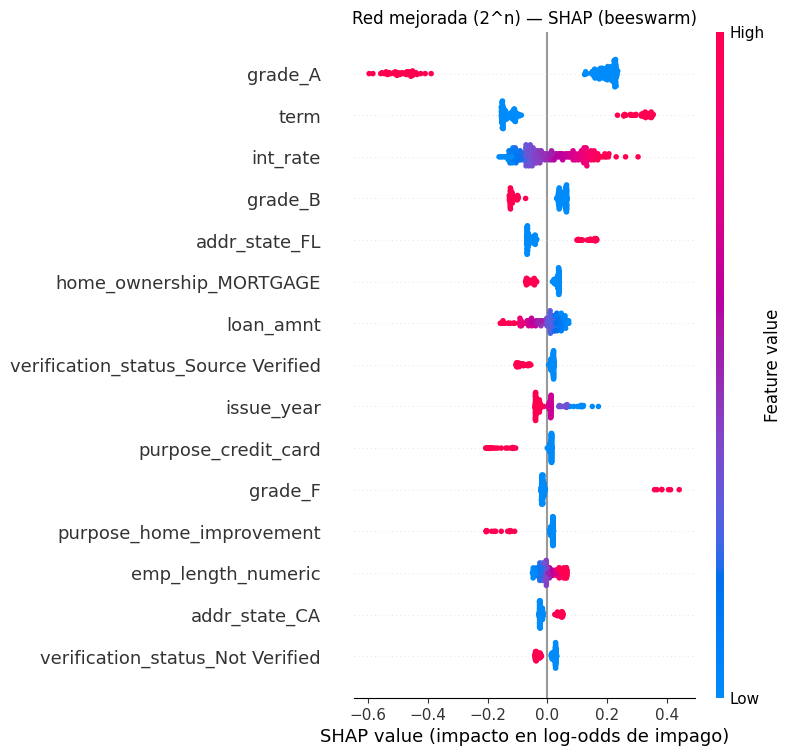

In [32]:
shap.summary_plot(sv, muestra, feature_names=nombres_limpios, max_display=MAX_DISPLAY, show=False)
plt.title(f'{NOMBRE_SHAP} — SHAP (beeswarm)')
plt.xlabel('SHAP value (impacto en log-odds de impago)')
plt.gcf().savefig(RESULTADOS / 'shap_beeswarm_2n.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close('all')

### 13.5 Ranking global y dirección del efecto
- `importancia_SHAP`: promedio del |SHAP| (cuánto mueve la salida, en log-odds, sin importar el signo).
- `corr_valor_SHAP`: correlación entre el **valor** de la variable y su **SHAP**. Positiva ⇒ valores altos aumentan el riesgo; negativa ⇒ lo reducen. En variables *dummy* indica el efecto de "tener la categoría" frente a no tenerla. Es solo un resumen: no captura no linealidades ni interacciones.

In [33]:
def corr_signo(x, s):
    return 0.0 if x.std() == 0 or s.std() == 0 else float(np.corrcoef(x, s)[0, 1])

ranking = pd.DataFrame({
    'variable': nombres_limpios,
    'importancia_SHAP': np.abs(sv).mean(axis=0),
    'corr_valor_SHAP': [corr_signo(muestra[:, j], sv[:, j]) for j in range(muestra.shape[1])],
}).sort_values('importancia_SHAP', ascending=False).reset_index(drop=True)
ranking['direccion'] = np.where(ranking['corr_valor_SHAP'] > 0.1, 'valor alto ↑ riesgo',
                        np.where(ranking['corr_valor_SHAP'] < -0.1, 'valor alto ↓ riesgo', 'sin patrón claro'))
display(ranking.head(MAX_DISPLAY))
ranking.to_csv(RESULTADOS / 'shap_ranking_2n.csv', index=False, encoding='utf-8-sig')

,variable,importancia_SHAP,corr_valor_SHAP,direccion
0,grade_A,0.268513,-0.994099,valor alto ↓ riesgo
1,term,0.183847,0.994145,valor alto ↑ riesgo
2,int_rate,0.087989,0.990010,valor alto ↑ riesgo
3,grade_B,0.071538,-0.991279,valor alto ↓ riesgo
4,addr_state_FL,0.070338,0.984359,valor alto ↑ riesgo
5,home_ownership_MORTGAGE,0.043109,-0.983426,valor alto ↓ riesgo
6,loan_amnt,0.040024,-0.990085,valor alto ↓ riesgo
7,verification_status_Source Verified,0.037816,-0.984496,valor alto ↓ riesgo
8,issue_year,0.034036,-0.987455,valor alto ↓ riesgo
9,purpose_credit_card,0.029887,-0.974808,valor alto ↓ riesgo


### 13.6 Elegir el préstamo más riesgoso de test
El beeswarm es una vista **global**. SHAP también explica **un préstamo concreto**. Se elige el de test con **mayor probabilidad de impago** según la red, y se muestran su probabilidad, el umbral operativo (elegido en validación), su estado real y sus datos. Ojo: si la red no está balanceada, incluso el préstamo más riesgoso puede tener una probabilidad modesta.

In [34]:
p_test = probabilidades(modelo_shap, X_test_s)
i_riesgo = int(np.argmax(p_test))
x_riesgo = X_test_s[[i_riesgo]]

print(f'Posición en test: {i_riesgo}')
print(f'Probabilidad de impago ({NOMBRE_SHAP}): {p_test[i_riesgo]:.4f}')
print(f'Umbral operativo (F1 en validación): {umbrales[NOMBRE_SHAP]:.4f}')
print('Estado real:', 'Charged Off (impago)' if int(np.asarray(y_test)[i_riesgo]) == 1 else 'Fully Paid (pagado)')
cols_vista = [c for c in ['grade','int_rate','term','pub_rec_bankruptcies','annual_inc','emp_length_numeric',
                          'home_ownership','installment','dti','purpose','verification_status'] if c in X_test.columns]
display(X_test.iloc[[i_riesgo]][cols_vista].T.rename(columns={X_test.index[i_riesgo]: 'valor'}))

Posición en test: 2634
Probabilidad de impago (Red mejorada (2^n)): 0.3420
Umbral operativo (F1 en validación): 0.1777
Estado real: Fully Paid (pagado)


,valor
grade,F
int_rate,18.300000
term,60
pub_rec_bankruptcies,0.000000
annual_inc,34000.000000
emp_length_numeric,2.000000
home_ownership,OWN
installment,153.350000
dti,9.950000
purpose,small_business


### 13.7 SHAP local: waterfall del préstamo más riesgoso
Se calcula el SHAP de ese único préstamo con más evaluaciones (`NSAMPLES_LOCAL`).

**Cómo leer el waterfall**
- **Abajo:** `E[f(X)]`, la salida promedio sobre el background (log-odds).
- Cada **barra** suma (rojo, a la derecha) o resta (azul, a la izquierda) su aporte, de la más influyente (arriba) a la menos.
- **Arriba:** `f(x)`, la salida de la red para este préstamo (`= E[f(X)] + Σ SHAP`).
- A la izquierda de cada variable está **su valor real** en el préstamo (en unidades originales).
- Las variables menos relevantes se agrupan en "N other features".

SHAP local calculado en 16.0 s
E[f(X)] = -1.851 log-odds  ->  p = 0.136
f(x)    = -0.654 log-odds  ->  p = 0.342
E[f(X)] + suma(SHAP) = -0.654  (error de aditividad = 0.0000)


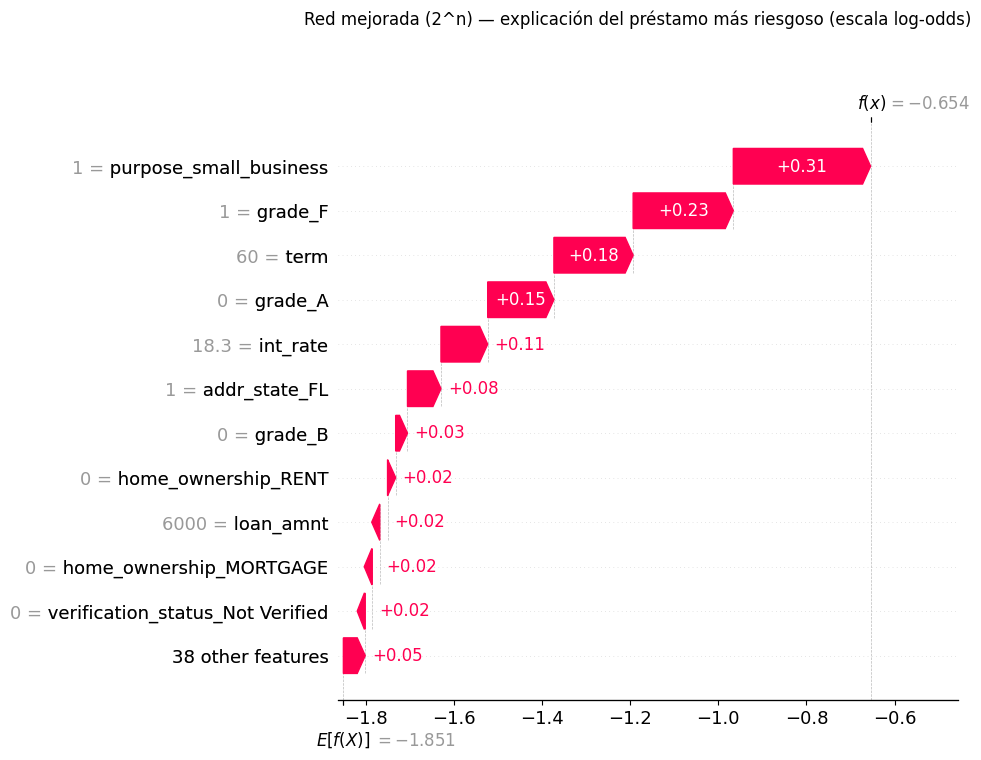

In [35]:
t0 = time.perf_counter()
explicador_local = shap.KernelExplainer(f_shap, fondo)
sv_riesgo = a_matriz(explicador_local.shap_values(x_riesgo, nsamples=NSAMPLES_LOCAL, l1_reg=0, silent=True),
                     1, x_riesgo.shape[1])[0]
base_local = float(np.ravel(explicador_local.expected_value)[0])
fx_riesgo = float(f_shap(x_riesgo)[0])
print(f'SHAP local calculado en {time.perf_counter() - t0:.1f} s')
print(f'E[f(X)] = {base_local:.3f} log-odds  ->  p = {sigmoide(base_local):.3f}')
print(f'f(x)    = {fx_riesgo:.3f} log-odds  ->  p = {sigmoide(fx_riesgo):.3f}')
print(f'E[f(X)] + suma(SHAP) = {base_local + sv_riesgo.sum():.3f}  (error de aditividad = {abs(base_local + sv_riesgo.sum() - fx_riesgo):.4f})')

valores_riesgo = a_valores_originales(x_riesgo)[0] + 0.0      # +0.0 evita mostrar "-0"
explicacion = shap.Explanation(values=sv_riesgo, base_values=base_local,
                               data=valores_riesgo, feature_names=list(nombres_limpios))
shap.plots.waterfall(explicacion, max_display=12, show=False)
plt.gcf().suptitle(f'{NOMBRE_SHAP} — explicación del préstamo más riesgoso (escala log-odds)', y=1.03, fontsize=12)
plt.gcf().savefig(RESULTADOS / 'shap_waterfall_2n_prestamo_riesgoso.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close('all')

### 13.8 Contribuciones del préstamo en tabla
La misma información del waterfall, sin agrupar y con signo, ordenada por |SHAP|.

In [36]:
contrib = pd.DataFrame({'variable': nombres_limpios,
                        'valor_en_el_prestamo': valores_riesgo,
                        'SHAP_log_odds': sv_riesgo})
contrib['empuja_hacia'] = np.where(contrib['SHAP_log_odds'] > 0, 'impago',
                           np.where(contrib['SHAP_log_odds'] < 0, 'pagado', '—'))
contrib = contrib.reindex(contrib['SHAP_log_odds'].abs().sort_values(ascending=False).index).reset_index(drop=True)
display(contrib.head(12))
contrib.to_csv(RESULTADOS / 'shap_contribuciones_2n_prestamo_riesgoso.csv', index=False, encoding='utf-8-sig')

,variable,valor_en_el_prestamo,SHAP_log_odds,empuja_hacia
0,purpose_small_business,1.000000,0.311483,impago
1,grade_F,1.000000,0.227264,impago
2,term,60.000000,0.179813,impago
3,grade_A,0.000000,0.150243,impago
4,int_rate,18.300000,0.106023,impago
5,addr_state_FL,1.000000,0.075952,impago
6,grade_B,0.000000,0.026799,impago
7,home_ownership_RENT,0.000000,0.018449,impago
8,loan_amnt,6000.000231,0.017730,impago
9,home_ownership_MORTGAGE,0.000000,0.016980,impago


### 13.9 Cómo interpretar y limitaciones
**Checklist de lectura**
1. **Aditividad:** los errores de 13.3 y 13.7 deben ser ≈ 0 (KernelSHAP la fuerza; no mide la precisión).
2. **Beeswarm:** identifica las 3 a 5 variables más importantes y el sentido de su efecto (color vs. lado del eje). Contrasta con `corr_valor_SHAP` y con los coeficientes logísticos de la sección 9.
3. **Waterfall:** distingue qué variables **explican la alerta** (barras rojas) y cuáles la **atenúan** (azules). Compara la probabilidad con el umbral operativo y el estado real.
4. **Sentido de negocio:** si dominan variables sin causalidad plausible (estado de residencia, año de emisión), puede tratarse de *proxies* del dataset y no de factores de riesgo reales.

**Limitaciones**
- KernelSHAP es una **aproximación por muestreo**: otra semilla, otro *background* o otro `nsamples` cambian ligeramente los resultados. Verifica la estabilidad subiendo `NSAMPLES_GLOBAL`.
- Asume que las variables se pueden **variar de forma independiente**; con variables correlacionadas (por ejemplo `int_rate` y `grade`) el crédito se reparte de forma arbitraria entre ellas.
- Las variables *one-hot* de una misma categoría se explican por separado; su efecto conjunto es la suma de sus SHAP.
- El *background* viene de **train** y la muestra de **test**: la interpretación vale para esa población de referencia.
- SHAP explica **el modelo**, no el fenómeno: no implica causalidad.